# 10 — 4μ final comparison: loose boundary and fixed-A buffer

Compare **loose boundaries and fixed-A buffers in reconstructed 4μ** using the same sequence and figure layout as the [2μ2e study in 09](09_MuIso_DPhi_2mu2e_WP1_WP2_FinalCheck.ipynb). The primary comparison is between the **extended loose diagnostic point: $I_0<0.30$, $|\Delta\phi|\geq2.4$** and the **WP2 fixed-A buffer: $I_0<0.25$, $|\Delta\phi|\geq2.4$; $I_H=0.25$, $\phi_L=2.0$**.

The extended loose point is the **MC diagnostic point with the largest absolute median known-background Z before applying the gate** among the 20 primary scan points. Currently, **none of the 20 loose points or 78 WP2/WP1 buffer points passes the nominal B/C/D contamination gate.** This point is therefore neither an eligible optimum nor an adopted working point. The buffer retains the WP2 A region from [08](08_MuIso_DPhi_4mu_LocalScan_summary.ipynb). The existing loose WP2 $(0.25,2.4)$ remains an auxiliary anchor; VR Data κ is not used to select the comparison points.

**Neither nominal DD Data A nor B/C/D is queried.** VR Data is used only when it can be reconstructed exactly from already public observations with the same mass, displacement, and partner-isolation selection and also passes the corresponding MC gate. Unavailable values are recorded as NaN with a reason, rather than zero. All 45 figure slots are retained, with explicit status information for unsupported Data results. Adoption of the final method, transfer of nonclosure to DD, and the likelihood remain unresolved.


In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

SIDM_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents)
                if (p/'studies'/'ABCD_finalize').is_dir())
NOTEBOOK_DIR = SIDM_DIR/'studies'/'ABCD_finalize'
for folder in (SIDM_DIR.parent, NOTEBOOK_DIR):
    if str(folder) not in sys.path:
        sys.path.insert(0,str(folder))
get_ipython().run_line_magic('matplotlib','inline')
from abcd_finalize_common import finalize_4mu_final_report_build_4mu_final_report as build_4mu_final_report

REPORT = build_4mu_final_report(NOTEBOOK_DIR)
tables = REPORT['tables']
figure_lookup = dict(REPORT['figures'])


4μ MC: calculating 20 loose points and WP2/WP1 fixed-A buffers.


10 4mu MC projection: 12/138


10 4mu MC projection: 24/138


10 4mu MC projection: 36/138


10 4mu MC projection: 48/138


10 4mu MC projection: 60/138


... (6 outputs left out)

10 4mu MC projection: 138/138


Reusing only existing public observations from the identical VR.


Rendering detailed loose/buffer figures.


Complete: 45 figures. Nominal gate passes: 0; the assessment table records the finalization status.


## Selection, scan ranges, and blinding

For 4μ, **LJ₀ is the leading μ-LJ and LJ₁ is the subleading μ-LJ**. The first letter of PP/PD/DP/DD describes the displacement state of LJ₀ and the second describes LJ₁. Applying a boundary of 2.5 to the stored integer max-pixel-hit variable defines P as >2 and D as ≤2; DSA constituents use 0 according to the stored convention.

The nominal selection is **DD, $M_{\mathrm{LJ,LJ}}\geq150$ GeV, $0\leq I_1<0.5$**. Low mass is $[0,150)$, intermediate mass is $[150,300)$, and inclusive mass is $M\geq0$. Intermediate PP/PD provide the primary validation, while DP is an auxiliary check with sparse statistics. Intermediate DD Data lies in the protected nominal-mass region, and no public input with the same selection exists for inclusive Data.

The primary loose scan contains 20 native points: $I_A=0.20,0.25,0.30,0.40,0.50$ and $\phi_A=2.4,2.6,2.7,2.8$. There is no native 2.5 rad boundary, and no interpolation is performed. The primary buffer scan uses $I_H\leq0.5$ and $\phi_L=0.5,1.0,1.5,2.0,2.2,2.4$. Wide diagnostics at $I_H=0.75,1,2$ are identified separately.

1. **Nominal blinding:** Protect the extended loose A $(I_0<0.30, |\Delta\phi|\geq2.4)$ and the buffer WP2 A $(I_0<0.25, |\Delta\phi|\geq2.4)$. Nominal B/C/D is also not queried because the all-120 MC gate fails. No separate veto automatically combines every historical A candidate.
2. **Integrated contamination:** The central-value ratio $S/B_{\mathrm{MC}}<10\%$ is required for each of the 120 individual signal hypotheses in every nominal B/C/D region or every A/B/C/D region of a VR. Positive background MC support is also required. Data closure is shown only for VRs that pass the gate.
3. **Data reuse:** Exactly reuse only observations made public under the same selection in 02/04/06/08. Partially visible 2D bins are not summed to replace full ABCD yields. Integrated gates and bin gates are distinct.
4. **Signals and weights:** Compute sensitivity separately for the same 60 matching 4Mu models; test contamination separately for all 120 hypotheses. Yields from different hypotheses are not summed. Retain the existing luminosity and cross-section weights. Sample masses are $m_B$ and $m_{Z_D}$, and proper $c\tau$ is expressed in mm.


In [2]:
display(tables['selection_definitions'].style.hide(axis='index'))
baseline_columns = ['wp','tx','ty','sr_background_A','sr_background_error','sr_neff_A',
    'z_median','PP_DATA_kappa','PP_DATA_kappa_error','PD_DATA_kappa','PD_DATA_kappa_error']
display(Markdown('**Auxiliary WP2/WP1 table from 08: the extended loose point (.30,2.4) shares WP1 boundaries but is a diagnostic point that fails the gate.**'))
display(tables['baseline_08'].loc[tables['baseline_08'].wp.isin(['WP2','WP1']),
    baseline_columns].style.hide(axis='index'))
display(tables['decision_summary'].style.hide(axis='index'))
primary_candidates = tables['plot_candidates'].loc[tables['plot_candidates'].is_primary.astype(bool)]
display(Markdown('**Primary comparison: extended loose diagnostic point (.30,2.4) and WP2 fixed-A buffer (.25,2.4)**'))
display(primary_candidates[['label','role','group','a_iso','a_phi','b_iso','c_phi','purity_pass_BCD']].style.hide(axis='index'))


item,definition
Channel and ordering,"Reconstructed 4μ; LJ0=leading μ-LJ, LJ1=subleading μ-LJ"
Nominal,"DD, M_LJ,LJ≥150 GeV, 0≤I1<0.5"
Displacement,"P: max pixel hits>2; D: ≤2, applied to each μ-LJ; DSA constituent=0"
Primary validation,"150≤M_LJ,LJ<300 GeV, PP/PD; DP is an auxiliary validation with limited statistics"
Additional scopes,0≤M<150 GeV and inclusive MC; intermediate DD is MC-only
Loose main scan,"I_A=.20,.25,.30,.40,.50 × phi_A=2.4,2.6,2.7,2.8"
Loose comparison,Maximum absolute median known-background Z over the primary 20 points before the gate; unadopted diagnostic candidate with extended A
Buffer anchors,"WP2 A=(.25,2.4) is primary; WP1 A=(.30,2.4) is auxiliary"
Buffer controls,"Native edges with I_H≥I_A; phi_L=.5,1,1.5,2,2.2,2.4; wide I_H=.75,1,2 are separate"
Signal comparison,Sensitivity: 60 matching 4Mu hypotheses; contamination: 120 separate hypotheses; models are never summed


**Auxiliary WP2/WP1 table from 08: the extended loose point (.30,2.4) shares WP1 boundaries but is a diagnostic point that fails the gate.**

wp,tx,ty,sr_background_A,sr_background_error,sr_neff_A,z_median,PP_DATA_kappa,PP_DATA_kappa_error,PD_DATA_kappa,PD_DATA_kappa_error
WP1,0.300000,2.400000,3.253182,3.248042,1.003167,0.439965,1.104031,0.214704,0.950000,0.506671
WP2,0.250000,2.400000,3.253182,3.248042,1.003167,0.439157,1.083617,0.213250,1.004831,0.544849


strategy,candidates,main_candidates,positive_control_candidates,nominal_BCD_gate_pass,minimum_supported_max_S_B,limiting_region,limiting_sample,selected,status,interpretation
loose,20,20,20,0,16.933229,C,4Mu_800GeV_5p0GeV_5p0mm,False,NO_NOMINAL_GATE_PASS,Minimum contamination is diagnostic; this is not an adopted point satisfying statistical support and disclosure requirements
buffer_wp2,42,24,21,0,225.138606,C,4Mu_800GeV_1p2GeV_1p2mm,False,NO_NOMINAL_GATE_PASS,Minimum contamination is diagnostic; this is not an adopted point satisfying statistical support and disclosure requirements
buffer_wp1,36,18,18,0,226.746739,C,4Mu_800GeV_1p2GeV_1p2mm,False,NO_NOMINAL_GATE_PASS,Minimum contamination is diagnostic; this is not an adopted point satisfying statistical support and disclosure requirements


**Primary comparison: extended loose diagnostic point (.30,2.4) and WP2 fixed-A buffer (.25,2.4)**

label,role,group,a_iso,a_phi,b_iso,c_phi,purity_pass_BCD
Loose extended (MC-score diagnostic),diagnostic,loose_extended,0.300000,2.400000,0.300000,2.400000,False
Buffered WP2,diagnostic,buffer_wp2,0.250000,2.400000,0.250000,2.000000,False


## 1. Nominal MC and the two approaches

The nominal DD MC plane shows the Reference, the WP2 fixed A, and the **extended loose A $(0.30,2.4)$**. This figure uses MC; nominal Data A is not used. The primary loose point and the buffer have different A regions.

Loose boundaries change the isolation and angular edges of A together with B/C/D. The fixed-A buffer retains WP2 A $(0.25,2.4)$ and separates only the control boundaries. Each definition is applied consistently to nominal and VR selections. Both highlighted points are **diagnostic comparison points, not adopted working points**.


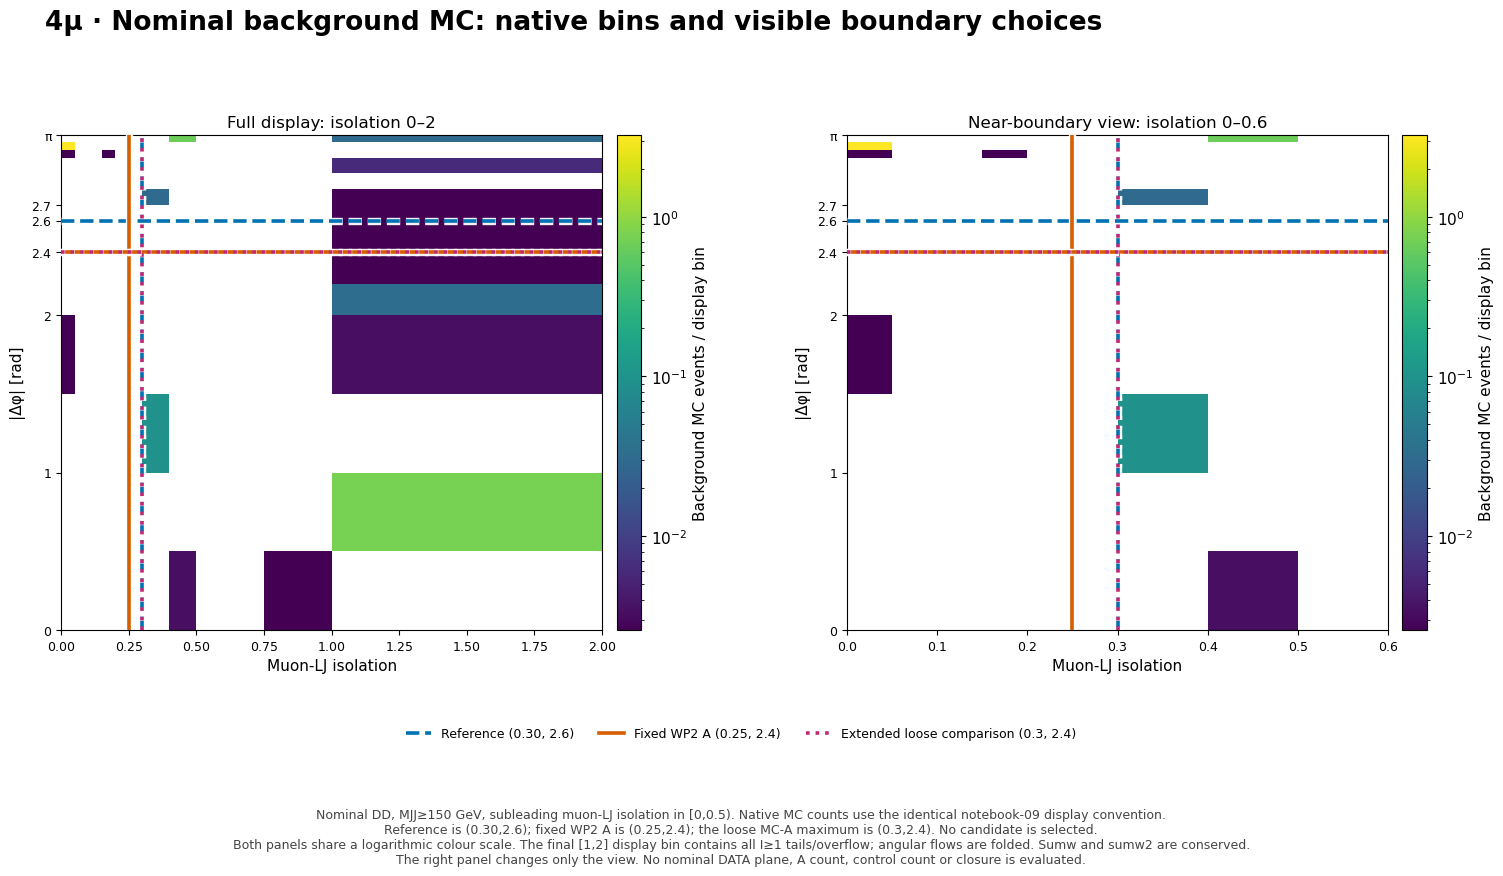

In [3]:
display(figure_lookup['if_nominal_plane'])


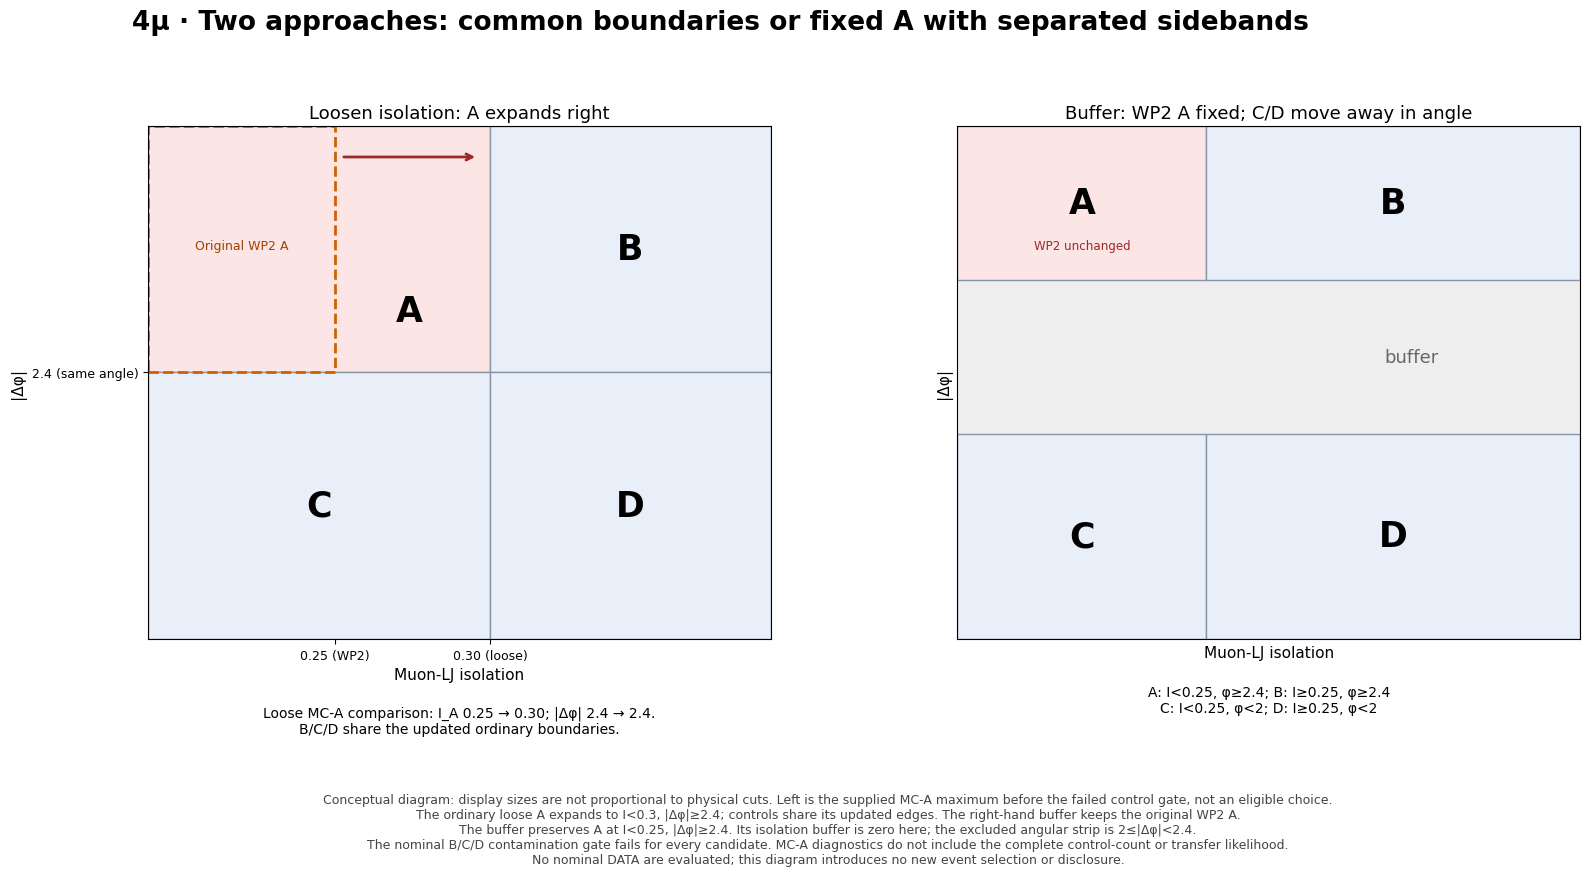

In [4]:
display(figure_lookup['if_approaches'])


## 2. Loose boundary: absolute sensitivity and contamination

The three panels show **$S/\sqrt{S+B}$, Z, and maximum nominal B/C/D contamination**. S and B are the nominal MC A yields for each model. Sensitivity is the **absolute median** over the same 60 matching 4Mu models, rather than a ratio to WP2. Contamination is the maximum obtained by testing 120 hypotheses individually.

Known-background Z is the MC comparison metric; finite-MC Z and control statistics are auxiliary diagnostics. Nominal Data counts and VR Data κ are not used for optimization. All primary scan candidates currently fail the nominal gate, so even the point with the largest sensitivity is not an adopted working point.


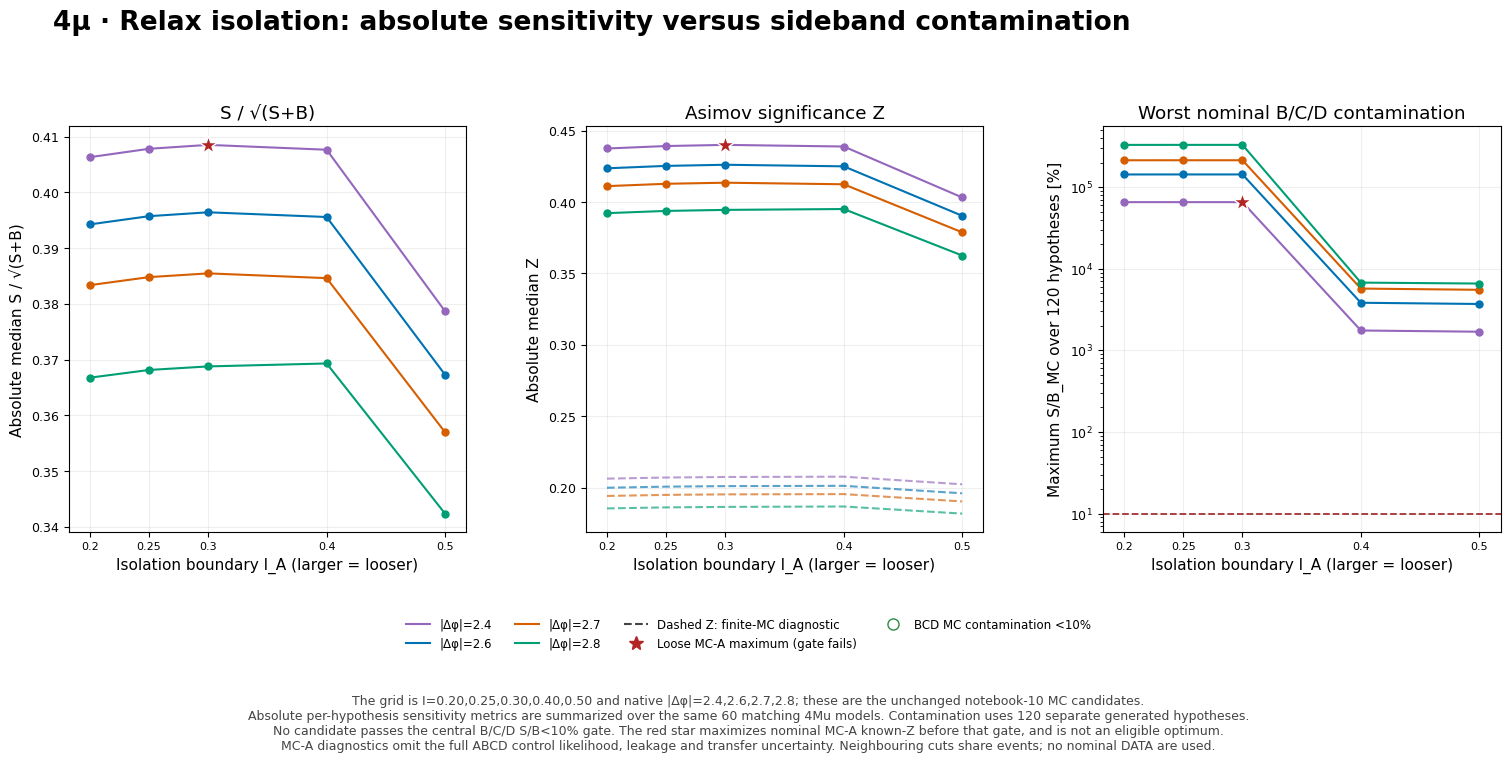

In [5]:
display(figure_lookup['if_tradeoff'])


### Extended loose diagnostic point: $(0.30,2.4)$, failing the nominal gate

The primary comparison point is **$(I_A,\phi_A)=(0.30,2.4)$**. Among the 20 primary scan points, it has the **largest absolute median known-background Z before applying the nominal contamination gate**, making it a separate MC diagnostic. Its boundaries match the existing WP1, but its role here is an extended loose diagnostic point.

The selection table below shows the gate status and MC diagnostics for each angle. No candidate currently passes contamination, so **no eligible loose optimum has been established.** Existing loose WP2 $(0.25,2.4)$ remains an auxiliary anchor.

The existing full native contiguous grid is retained in a separate audit table, distinct from the 20-point primary scan. Neither minimum contamination nor large MC-A sensitivity alone establishes that nominal controls may be used. VR Data κ and nominal Data counts were not used to select this diagnostic point.


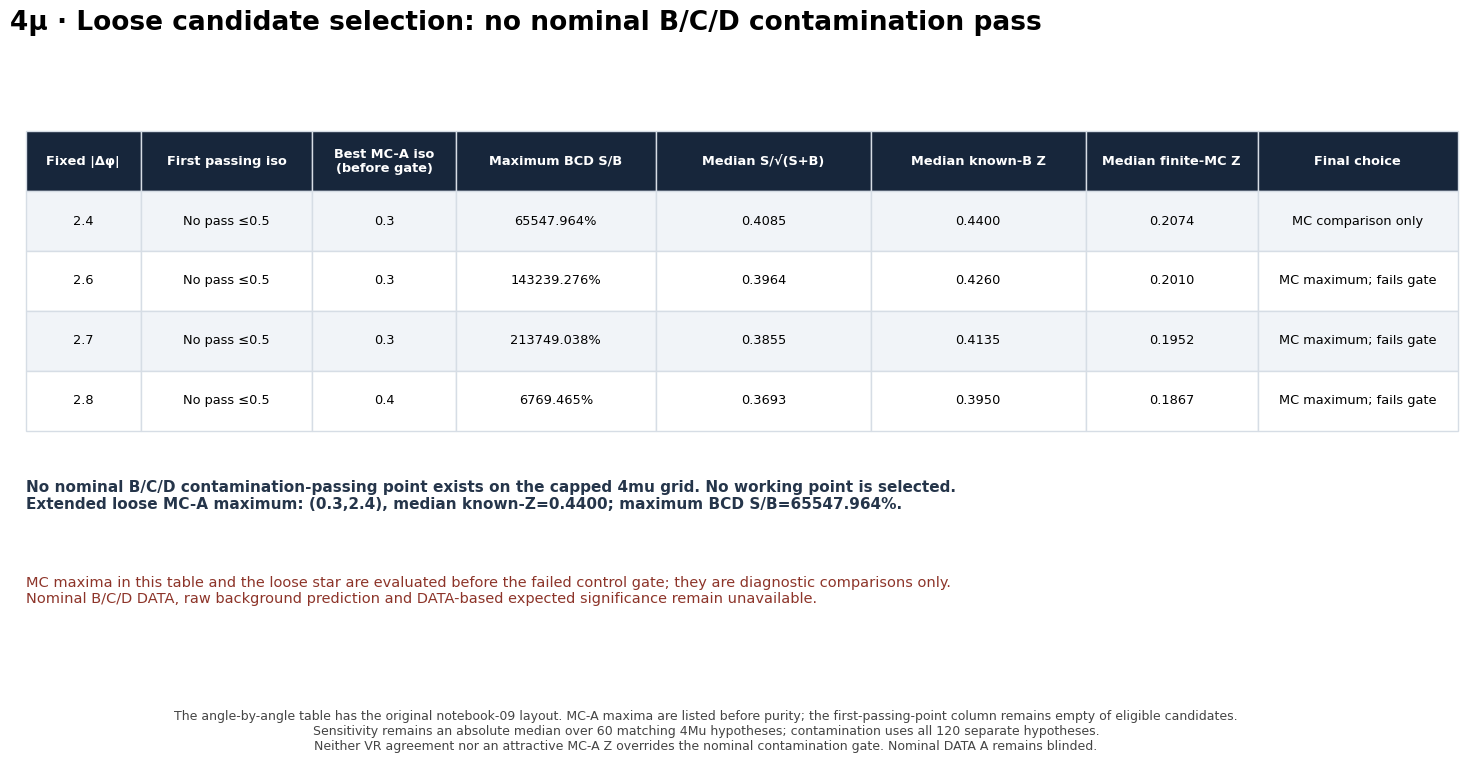

In [6]:
display(figure_lookup['if_selection'])


In [7]:
loose_scan = tables['mc_nominal_scan'].loc[tables['mc_nominal_scan'].strategy.eq('loose')]
display(loose_scan[['candidate_id','a_iso','a_phi','purity_pass_BCD','max_S_B_BCD',
    's_sqrt_s_plus_b_median','z_known_b_median','z_mc_stat_diagnostic_median',
    'min_sideband_neff']].style.hide(axis='index'))
display(Markdown('**Current status: no candidate passes the nominal gate for adoption.**'))


candidate_id,a_iso,a_phi,purity_pass_BCD,max_S_B_BCD,s_sqrt_s_plus_b_median,z_known_b_median,z_mc_stat_diagnostic_median,min_sideband_neff
L_i0p2_p2p4,0.200000,2.400000,False,655.479640,0.406333,0.437430,0.206248,1.000000
L_i0p2_p2p6,0.200000,2.600000,False,1431.087023,0.394267,0.423564,0.199880,1.000000
L_i0p2_p2p7,0.200000,2.700000,False,2136.184644,0.383362,0.411079,0.194136,1.000000
L_i0p2_p2p8,0.200000,2.800000,False,3295.678509,0.366755,0.392155,0.185414,1.000000
L_i0p25_p2p4,0.250000,2.400000,False,655.479640,0.407838,0.439157,0.207042,1.000000
L_i0p25_p2p6,0.250000,2.600000,False,1432.392759,0.395742,0.425249,0.200655,1.000000
L_i0p25_p2p7,0.250000,2.700000,False,2137.490380,0.384804,0.412719,0.194893,1.000000
L_i0p25_p2p8,0.250000,2.800000,False,3298.289982,0.368138,0.393719,0.186137,1.000000
L_i0p3_p2p4,0.300000,2.400000,False,655.479640,0.408540,0.439965,0.207413,1.000000
L_i0p3_p2p6,0.300000,2.600000,False,1432.392759,0.396439,0.426047,0.201022,1.000000


**Current status: no candidate passes the nominal gate for adoption.**

### Nominal MC closure

$\kappa_{\mathrm{MC}}=A_{\mathrm{MC}}/(B_{\mathrm{MC}}C_{\mathrm{MC}}/D_{\mathrm{MC}})$ diagnoses factorization in nominal simulation. It is separate from VR MC and VR Data checks. The green 0.9–1.1 band is a visual reference, not a confidence interval.

Sparse weighted MC can produce large κ values and uncertainties. Central values outside the display range and all numerical results remain in the tables; this κ is not used as an established correction for DD.


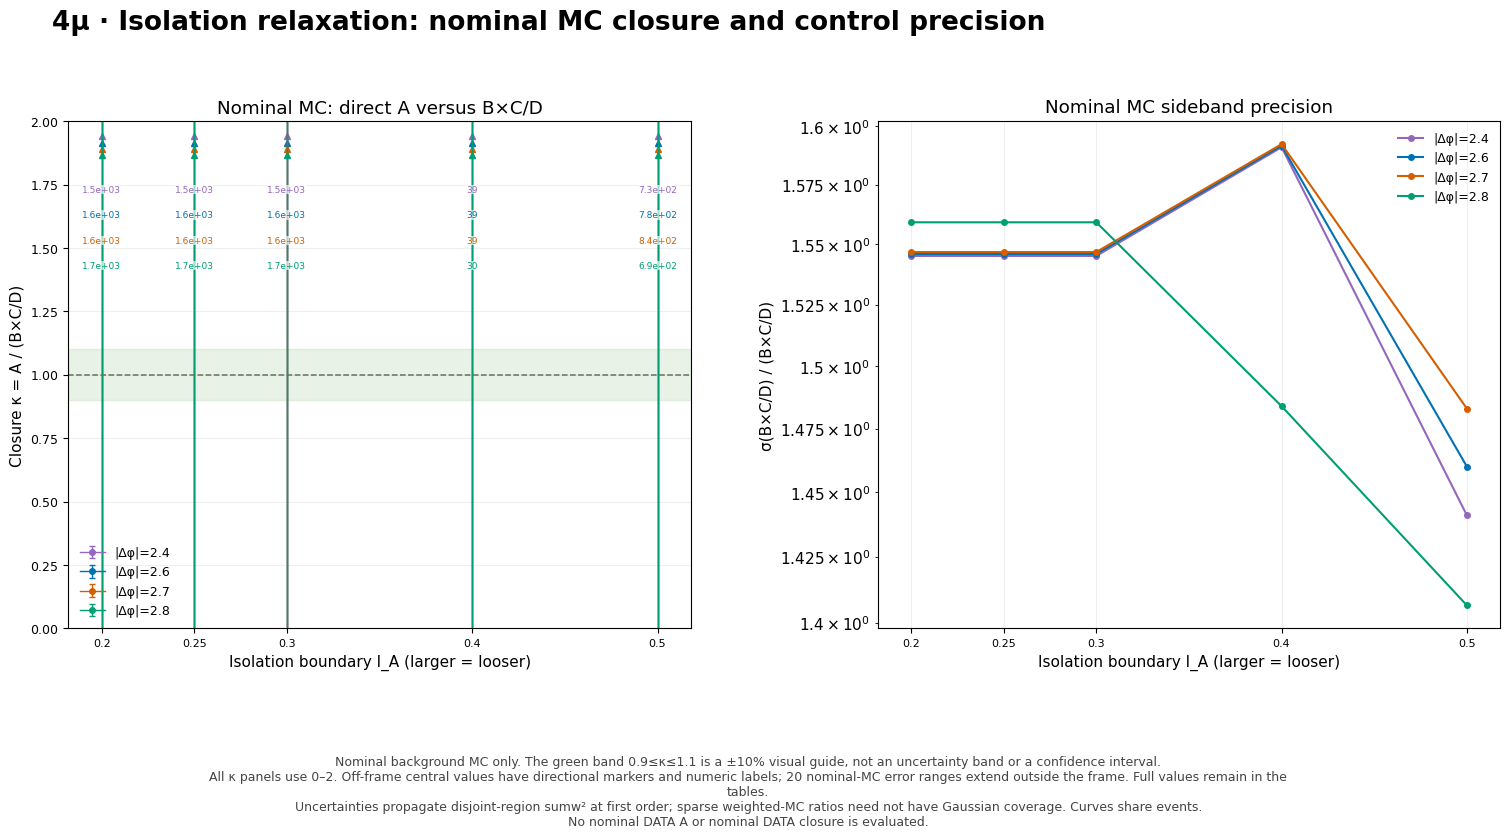

In [8]:
display(figure_lookup['if_nominal_closure'])


### Low mass: separate MC and Data VR closure scans

Each column represents an explicit PP/PD/DP displacement category. MC and Data are shown in separate figures. Low-DD is not added as a primary Data validation column because all current candidates fail the integrated VR MC gate.

Data curves retain only points that exactly reuse public observations with the same selection and also pass the all-120 A/B/C/D gate. Nearby thresholds share events; omitted points are not zero.


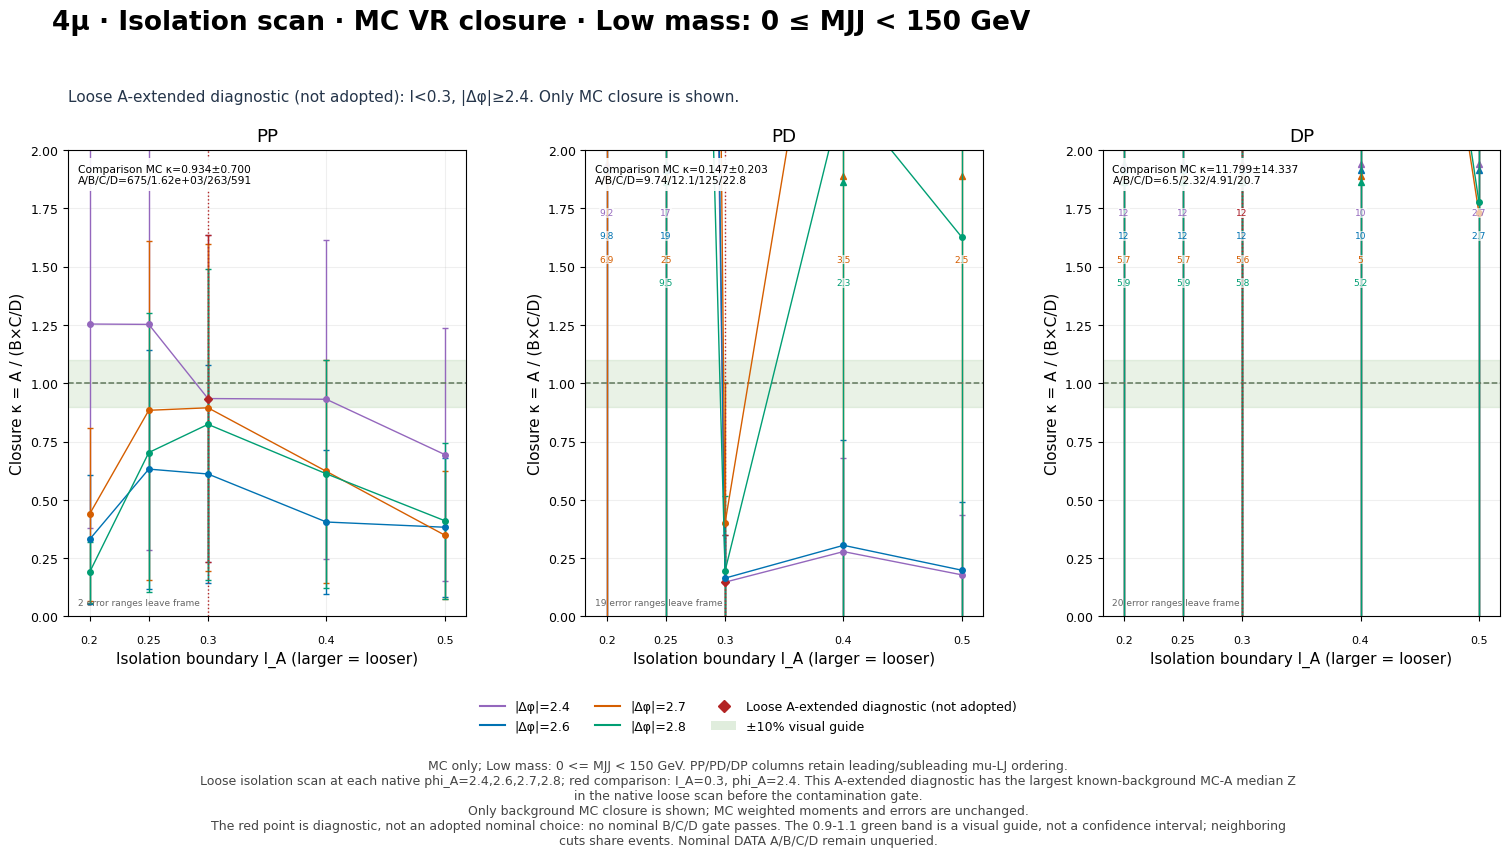

In [9]:
display(figure_lookup['if_vr_mc_low'])


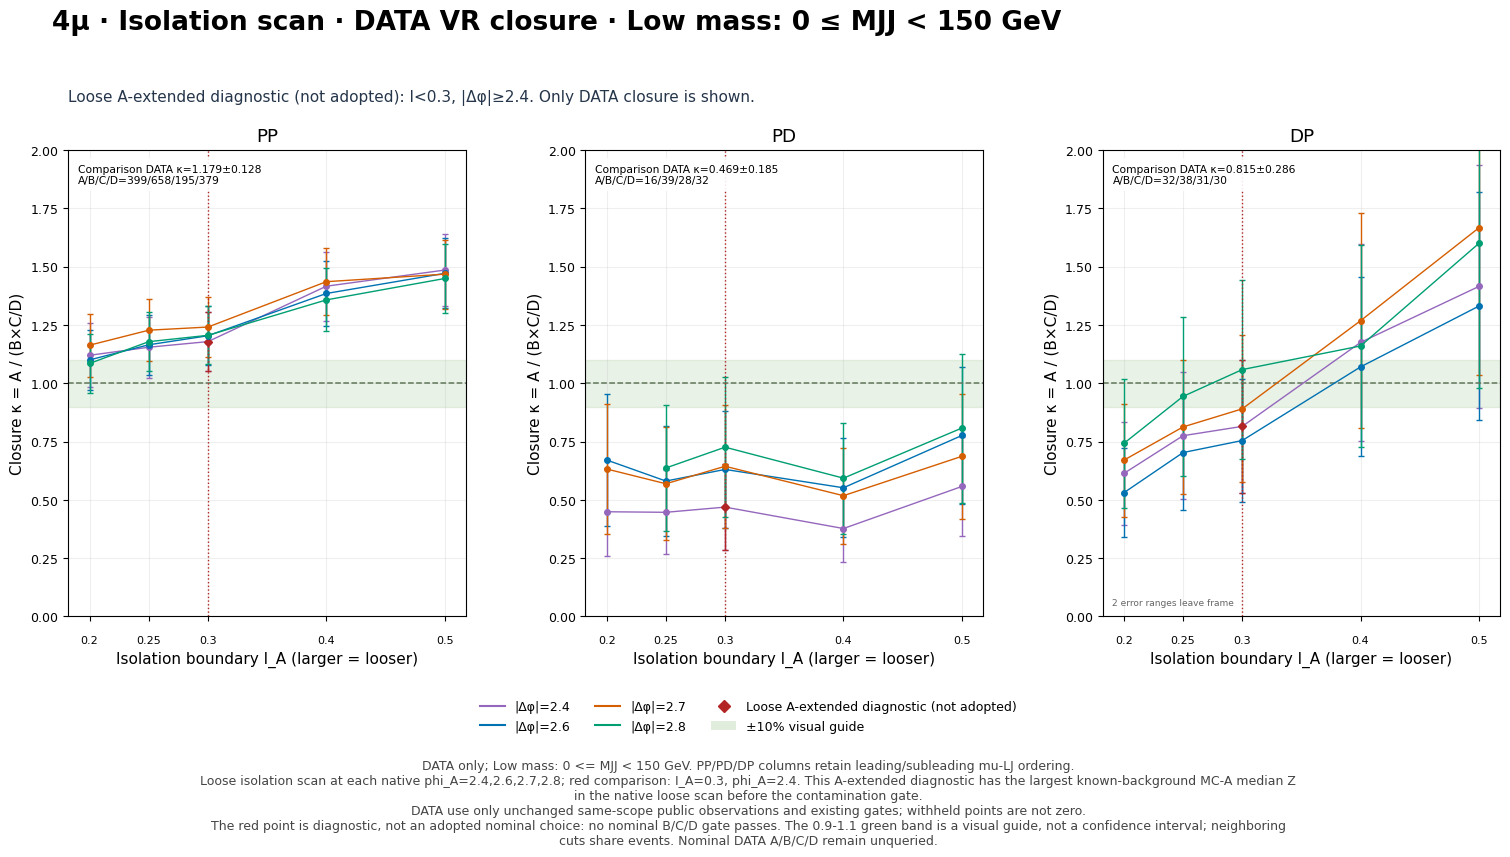

In [10]:
display(figure_lookup['if_vr_data_low'])


### Intermediate mass: separate MC and Data VR closure scans

Use PP/PD in $150\leq M<300$ GeV for primary validation and DP for auxiliary validation. MC and Data are shown separately, and the A/B/C/D gate is reapplied to every candidate. Intermediate DD Data is not used because it lies in the protected nominal-mass region.

Public VR closure validates that scope. It does not resolve a failed nominal DD control gate, and the nominal definition is not changed by choosing points whose Data κ is close to 1.


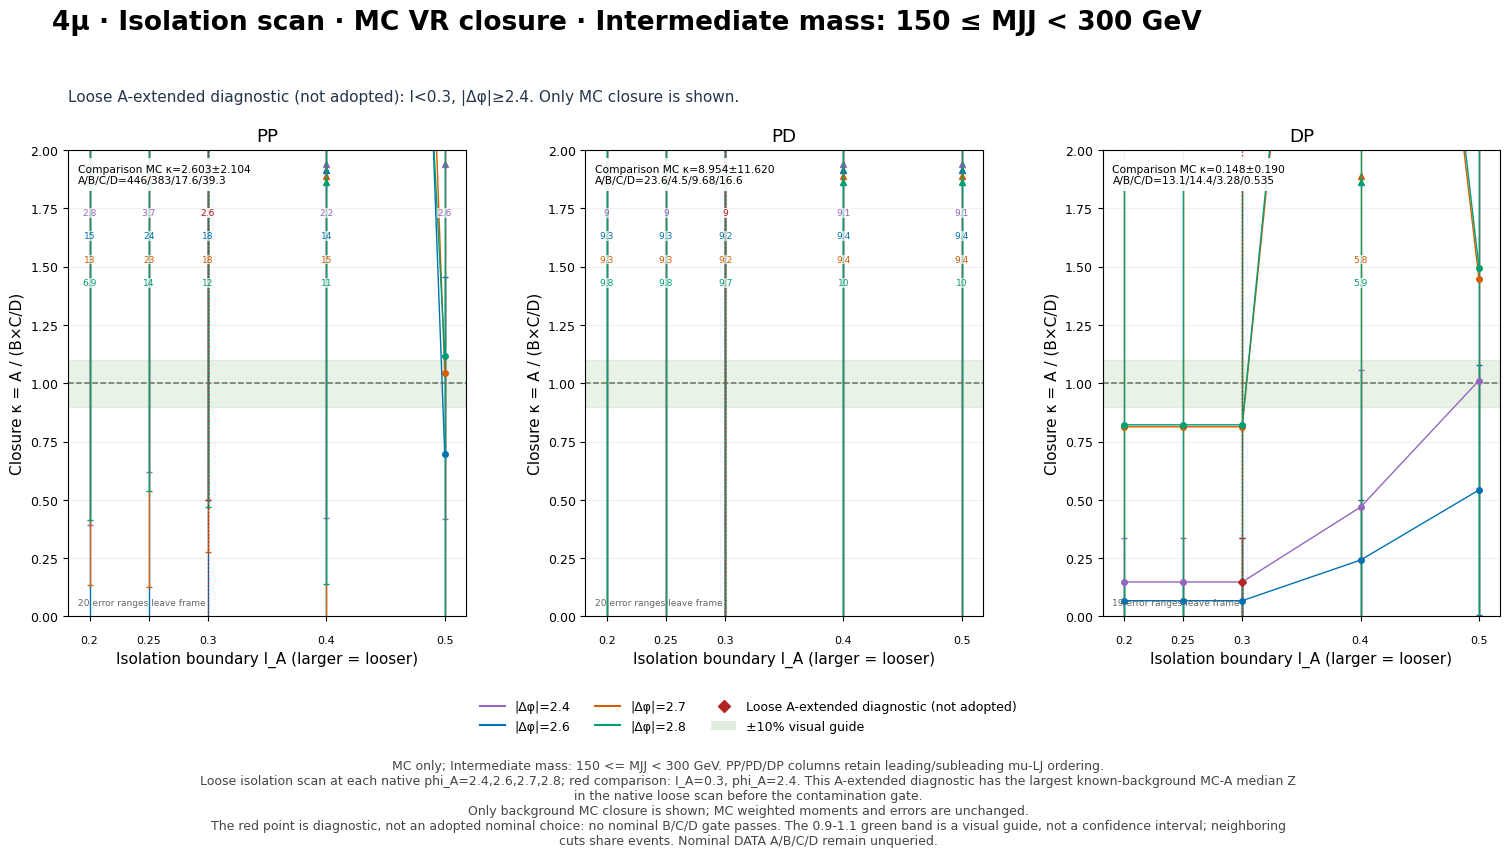

In [11]:
display(figure_lookup['if_vr_mc_intermediate'])


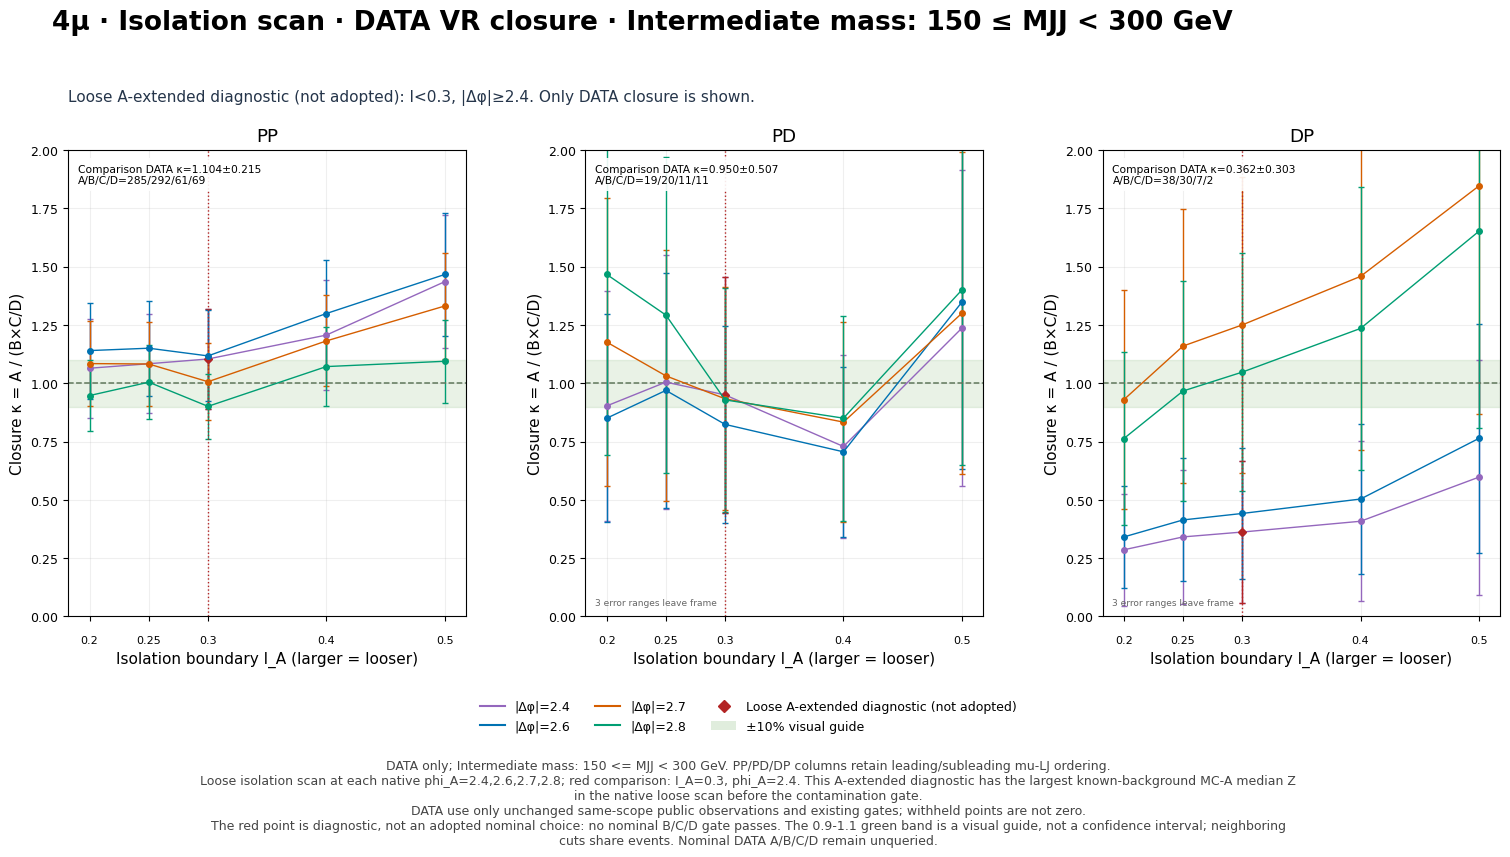

In [12]:
display(figure_lookup['if_vr_data_intermediate'])


### Inclusive mass: MC closure and Data availability

Inclusive MC is the actual MC integral over $M\geq0$. No public inclusive Data input with the same selection exists, so Data slots show the **reason for unavailability**. Low and intermediate Data are not combined to construct inclusive Data.

An empty Data axis means neither closure failure nor zero events. The figure sequence distinguishes the available scopes of MC and Data.


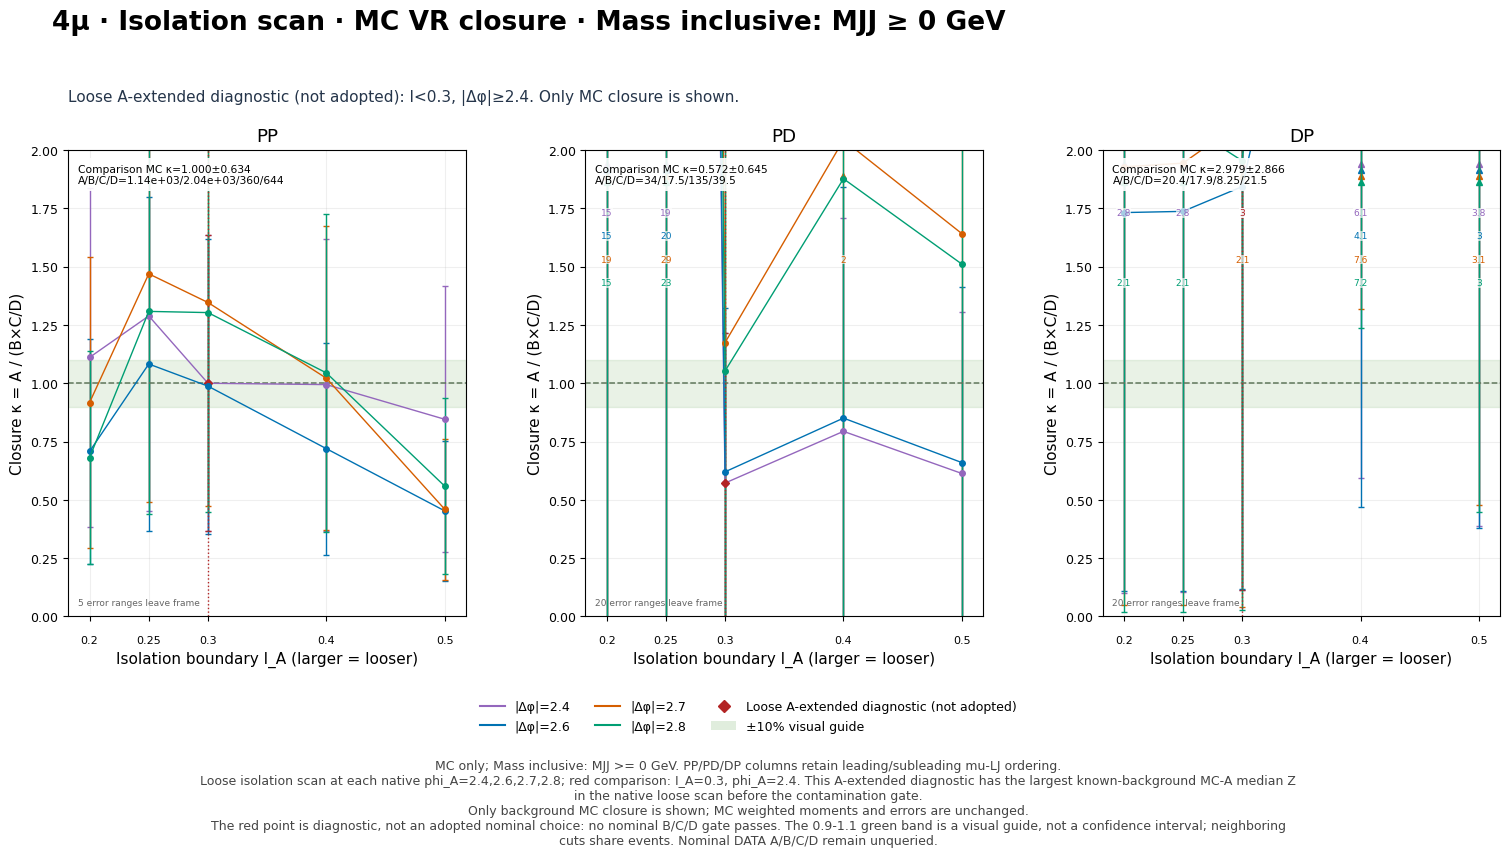

In [13]:
display(figure_lookup['if_vr_mc_all'])


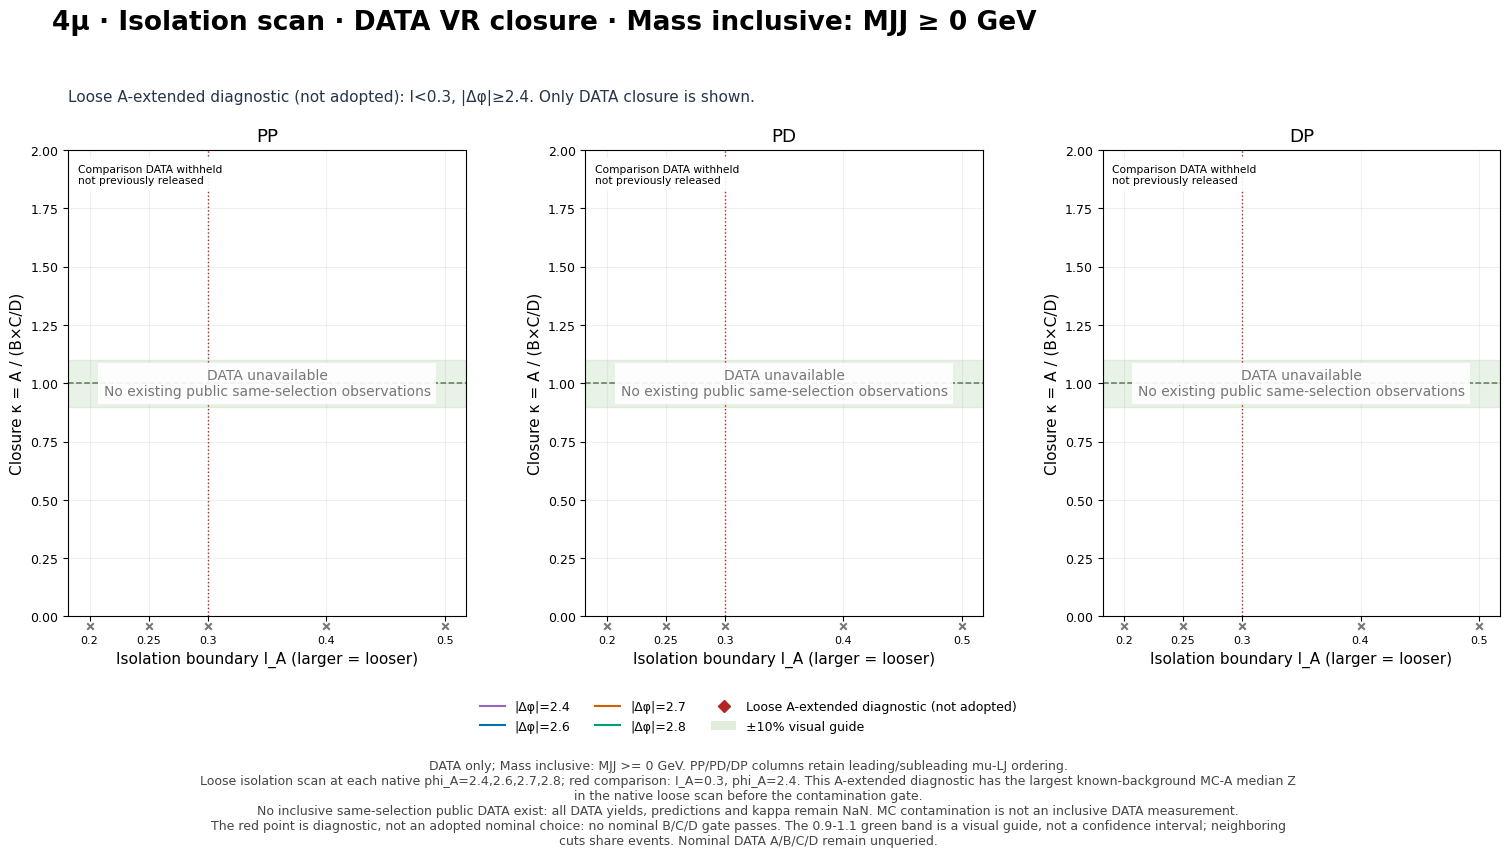

In [14]:
display(figure_lookup['if_vr_data_all'])


### Data validation of the extended loose diagnostic point: $(0.30,2.4)$

Follow the sequence used in 09. For each mass range, first show **1D Data yields, $BC/D$, κ, and MC contamination**, followed by separate MC 2D and masked Data 2D figures. The highlighted loose boundaries are $I_A=0.30$ and $\phi_A=2.4$. The 1D plots scan nearby native boundaries; they are not differential shape fits. Nearby thresholds are correlated.

Gray xx bins are withheld or fail the MC-support or contamination requirements. Valid white bins represent observed zero counts. Even when some previously public safe bins are visible, the selected full ABCD integral may remain withheld. Partial 2D information does not replace complete closure validation. Inclusive Data slots retain the reason that public input is unavailable.


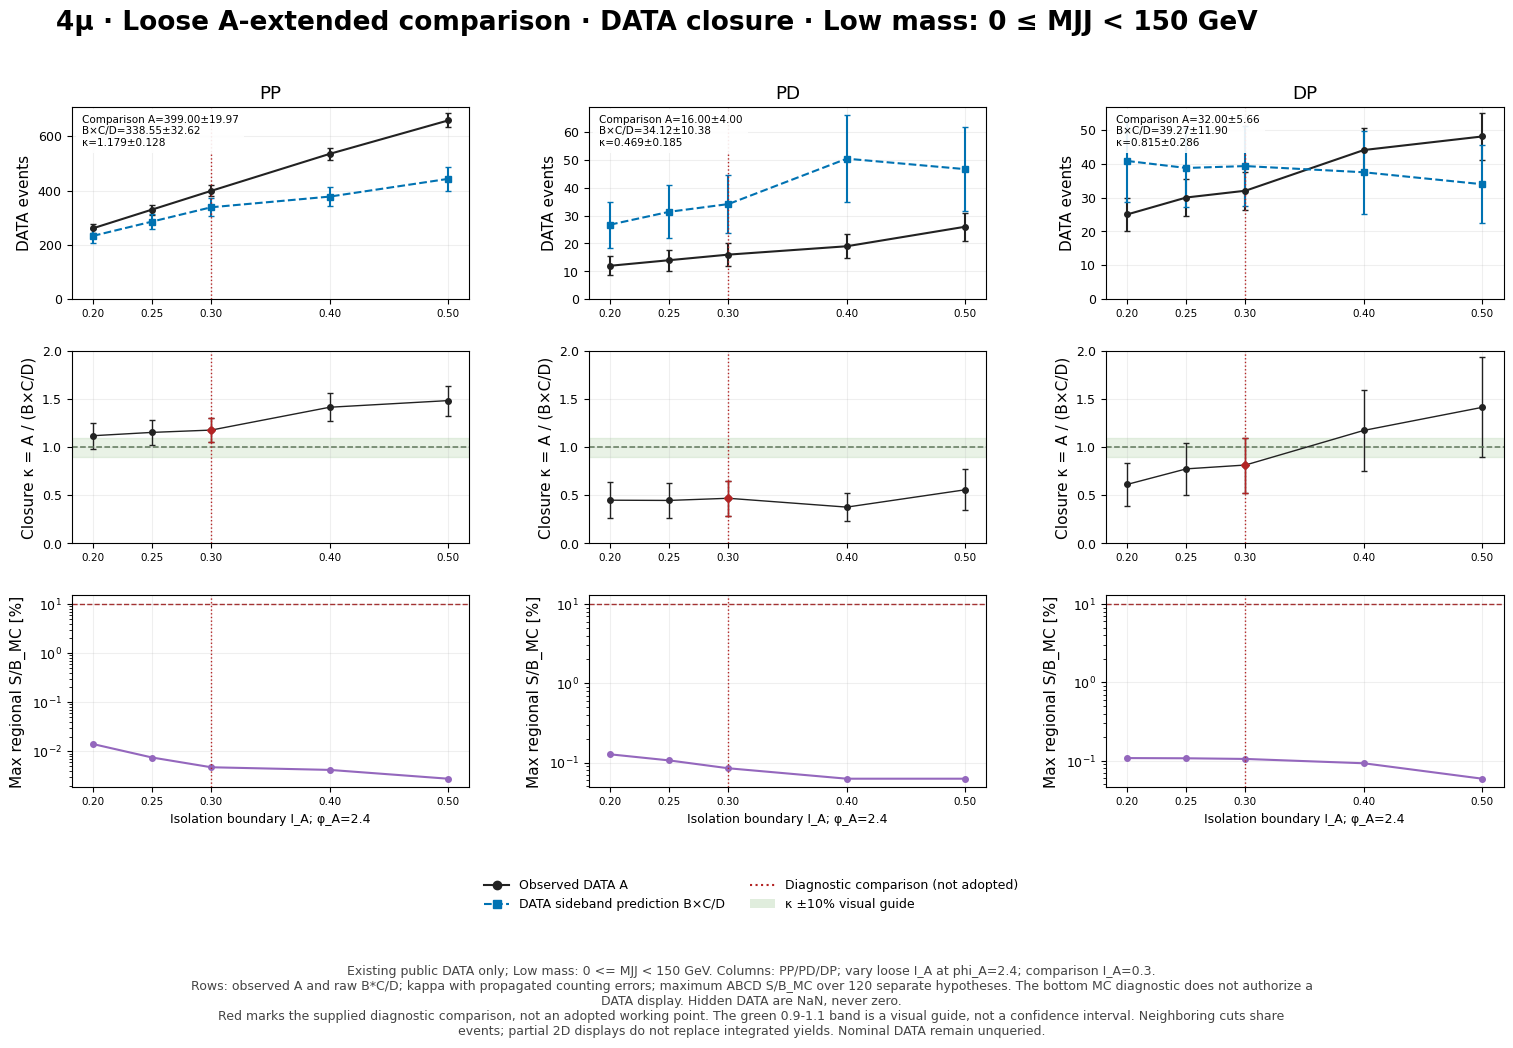

In [15]:
display(figure_lookup['loose_final_1d_low'])


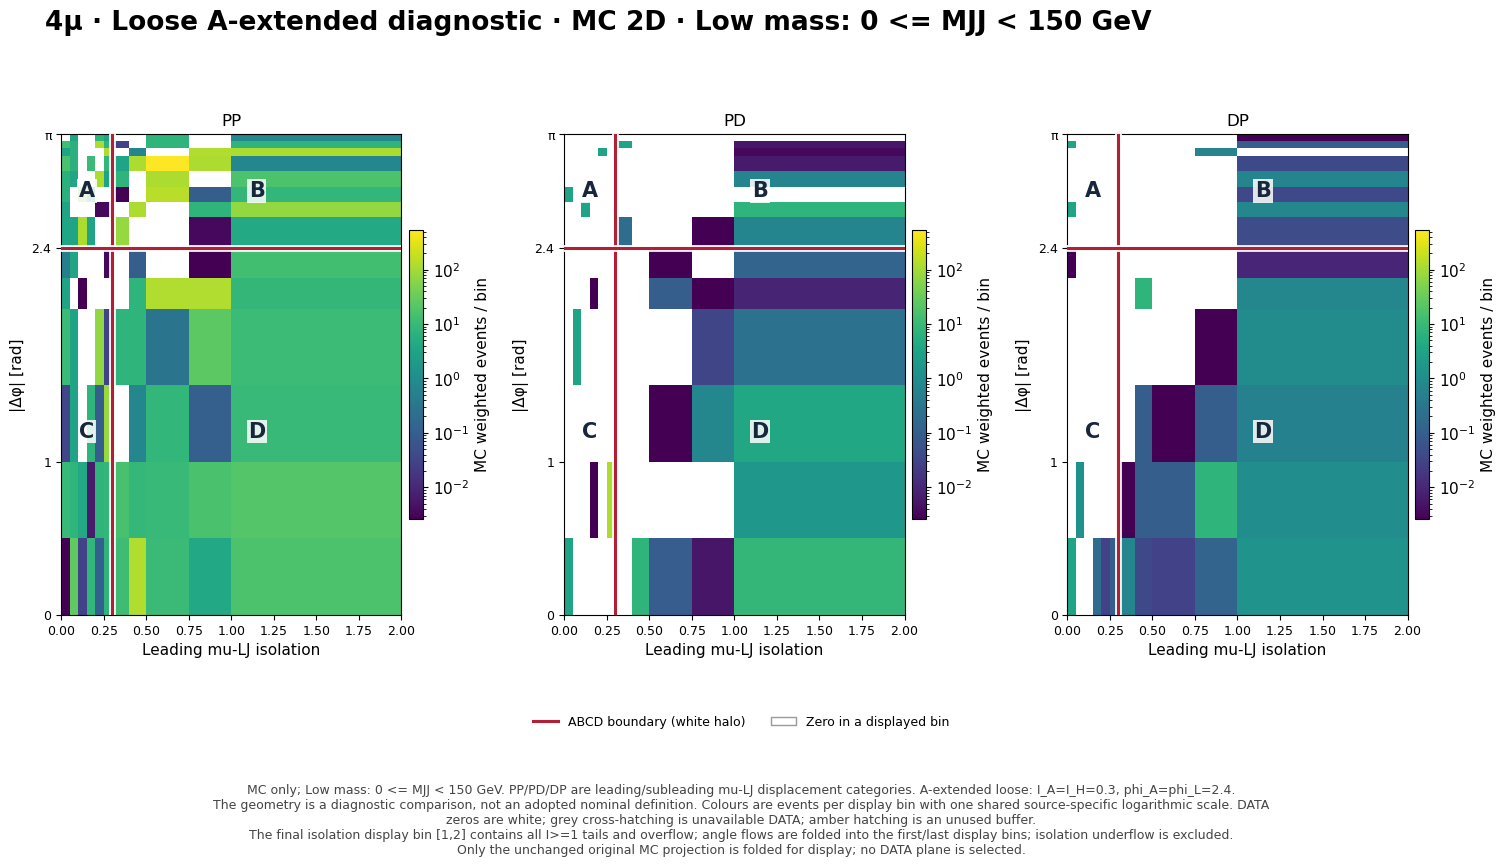

In [16]:
display(figure_lookup['loose2d_mc_low'])


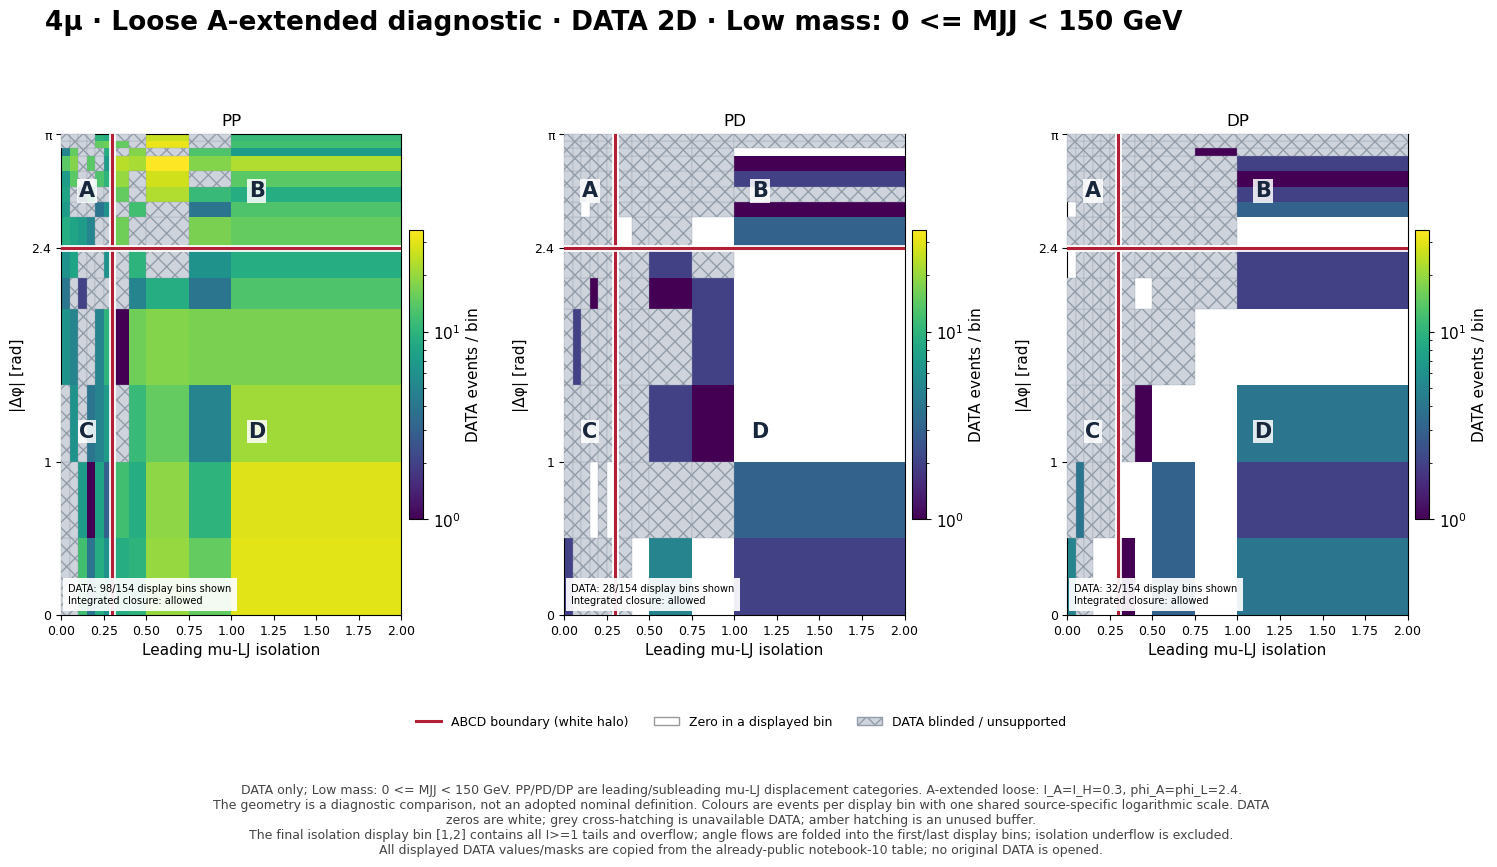

In [17]:
display(figure_lookup['loose2d_data_low'])


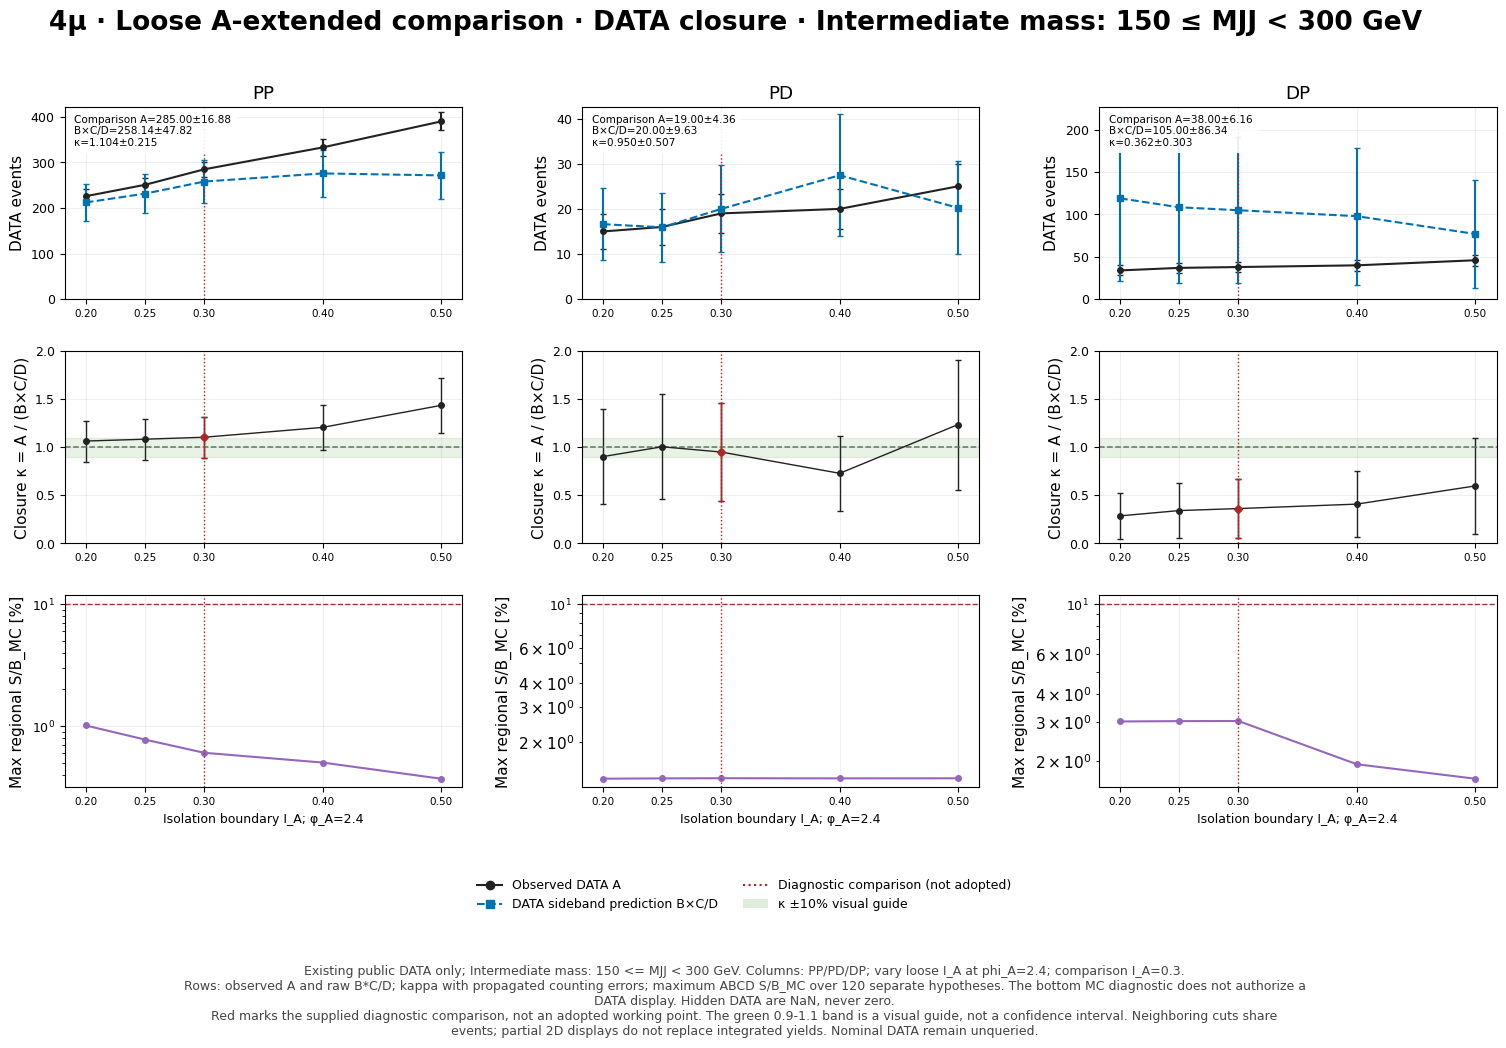

In [18]:
display(figure_lookup['loose_final_1d_intermediate'])


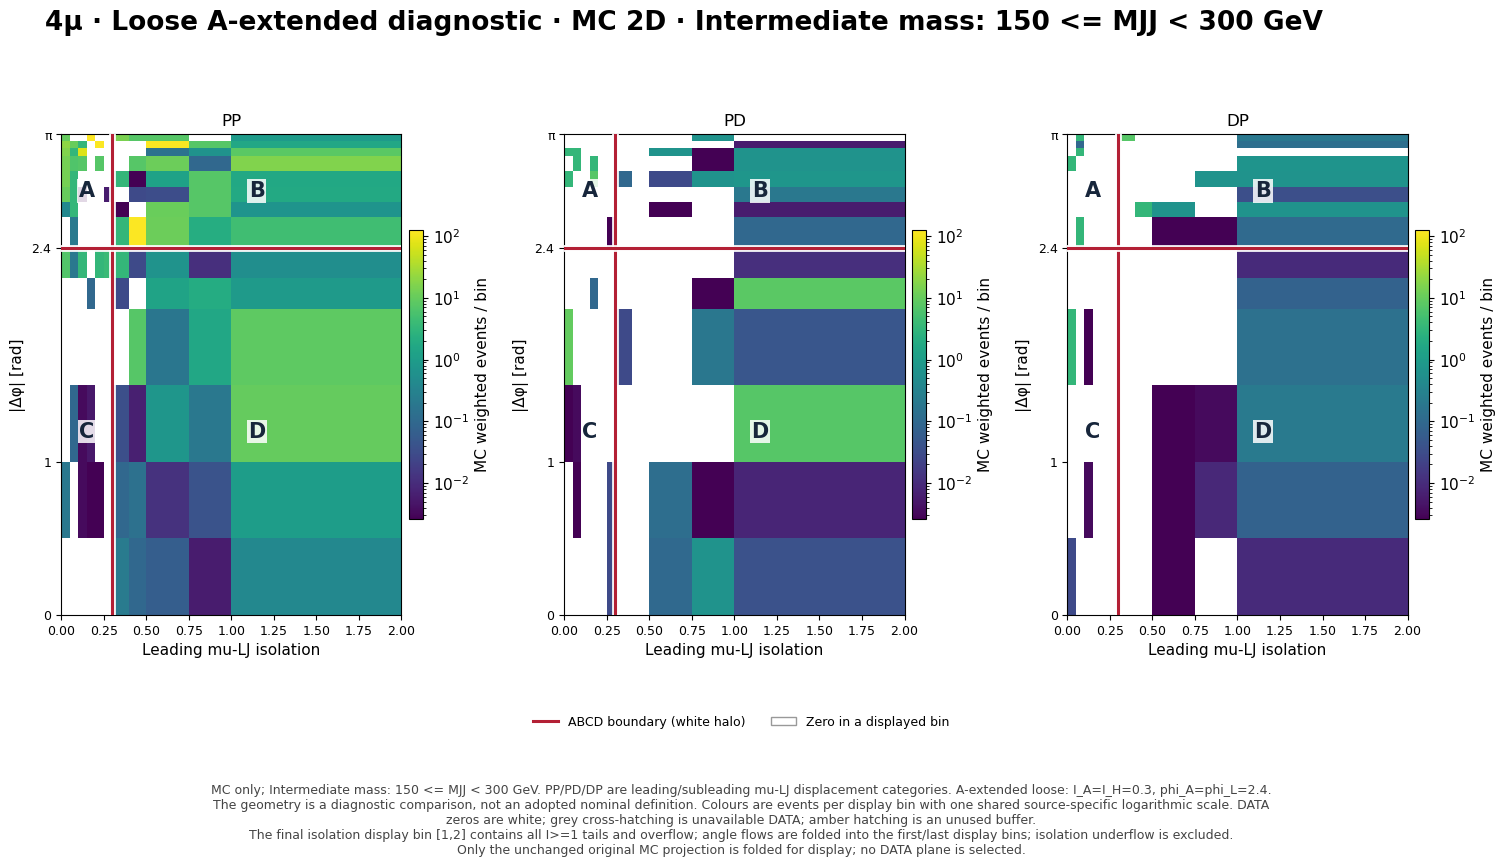

In [19]:
display(figure_lookup['loose2d_mc_intermediate'])


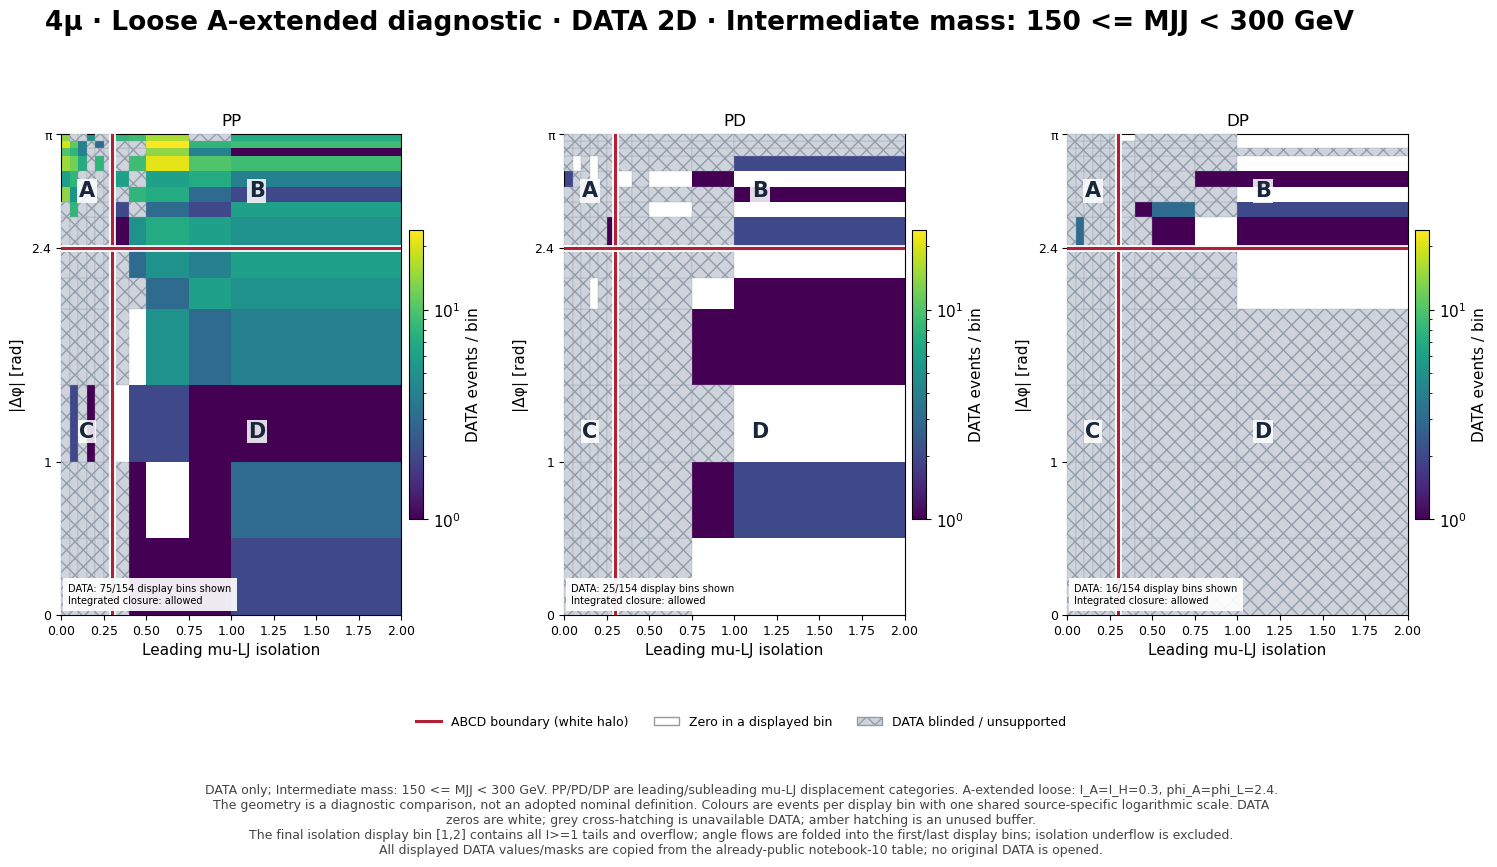

In [20]:
display(figure_lookup['loose2d_data_intermediate'])


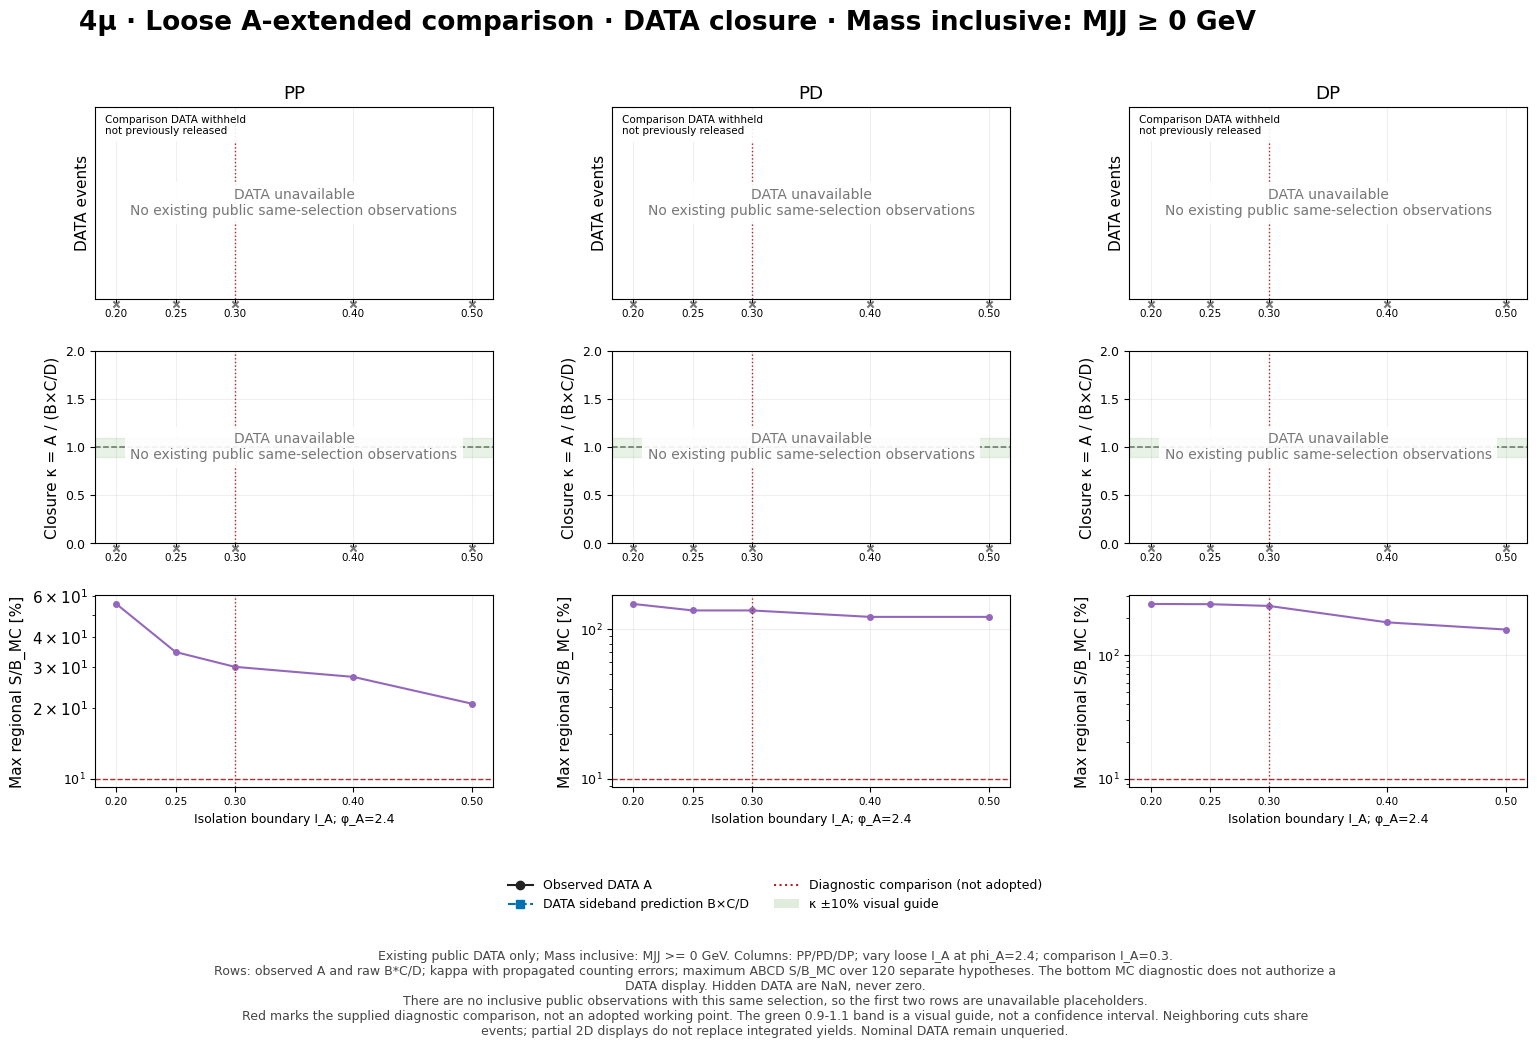

In [21]:
display(figure_lookup['loose_final_1d_all'])


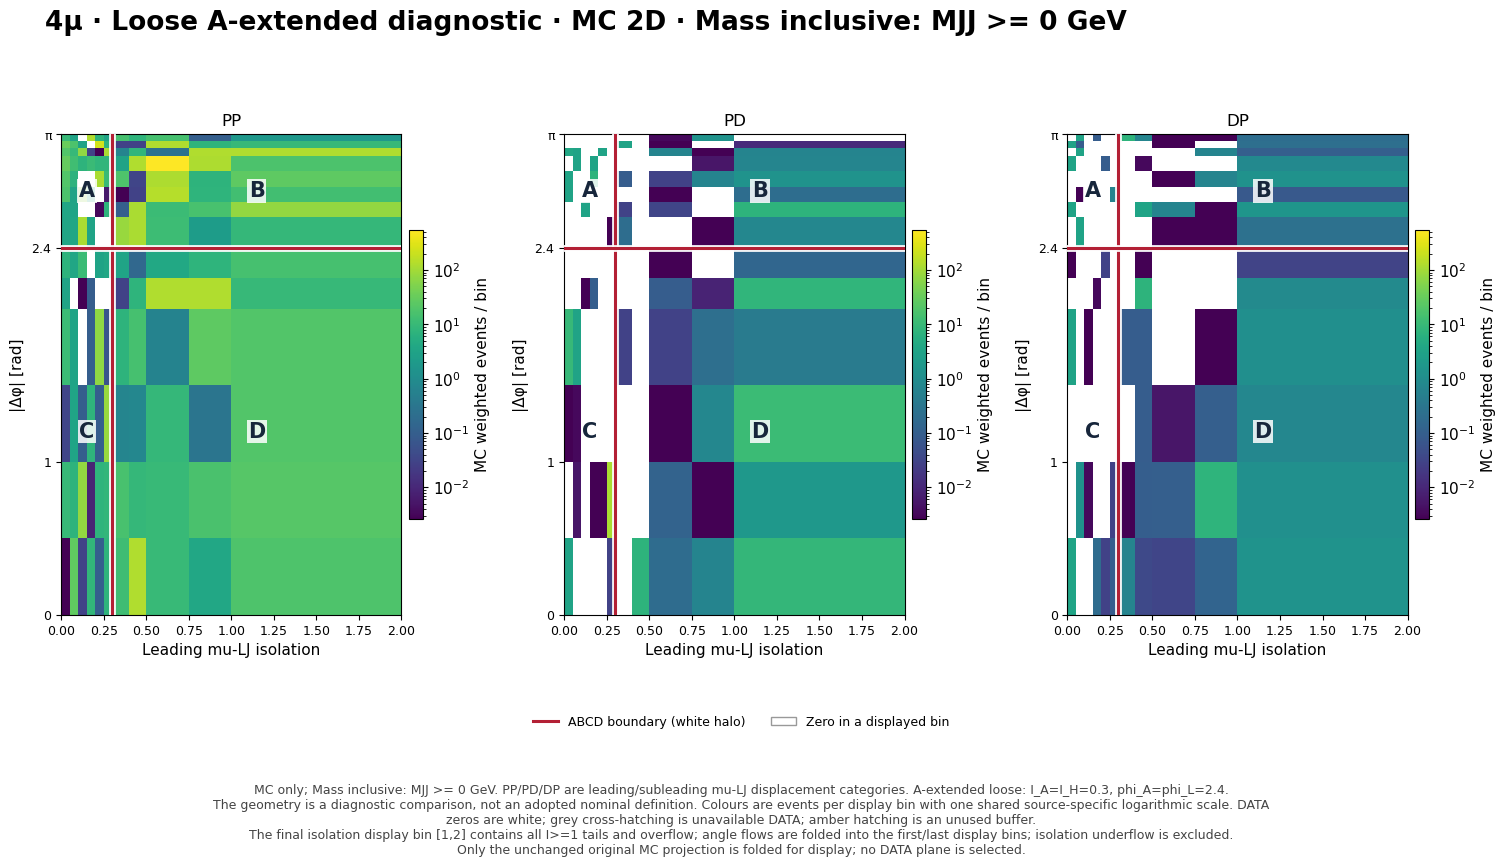

In [22]:
display(figure_lookup['loose2d_mc_all'])


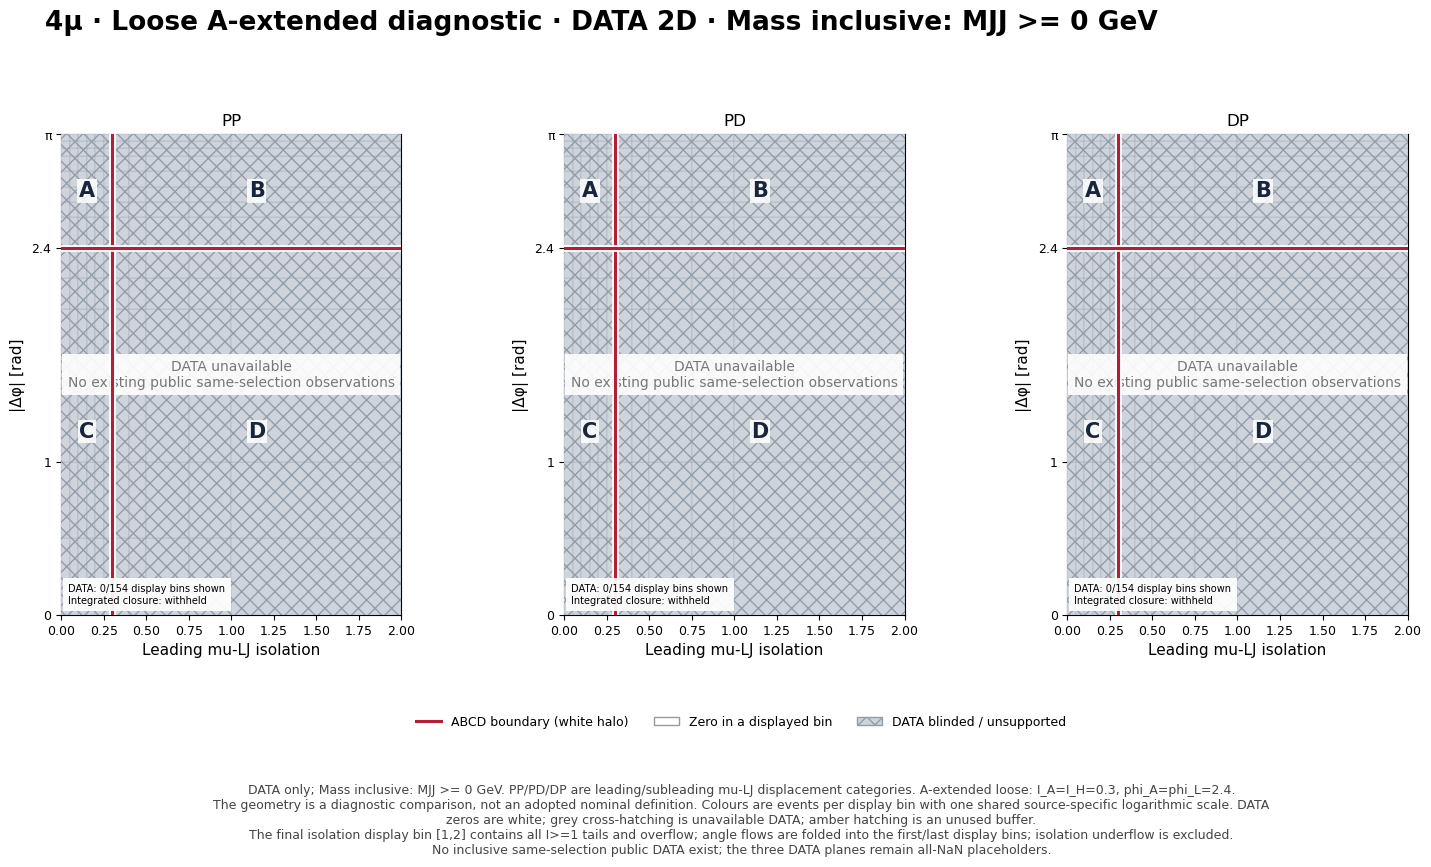

In [23]:
display(figure_lookup['loose2d_data_all'])


In [24]:
vr = tables['diagnostic_data_closure']
vr_columns = ['label','scope','display_allowed','A','B','C','D',
    'pred','pred_error','kappa','kappa_error','reason']
display(Markdown('**Public Data closure for the extended loose diagnostic point (.30,2.4)**'))
display(vr.loc[vr['group'].eq('loose_extended') & ~vr.scope.eq('nominal_DD'),
    vr_columns].style.hide(axis='index'))
display(Markdown('κ tests that VR; it does not authorize nominal controls or establish adoption of a final method.'))


**Public Data closure for the extended loose diagnostic point (.30,2.4)**

label,scope,display_allowed,A,B,C,D,pred,pred_error,kappa,kappa_error,reason
Loose extended (MC-score diagnostic),low_PP,True,399.000000,658.000000,195.000000,379.000000,338.548813,32.624733,1.178560,0.127985,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Loose extended (MC-score diagnostic),low_PD,True,16.000000,39.000000,28.000000,32.000000,34.125000,10.384620,0.468864,0.184655,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Loose extended (MC-score diagnostic),low_DP,True,32.000000,38.000000,31.000000,30.000000,39.266667,11.904160,0.814941,0.285993,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Loose extended (MC-score diagnostic),low_DD,False,nan,nan,nan,nan,nan,nan,nan,nan,VR_MC_GATE_FAILED
Loose extended (MC-score diagnostic),intermediate_PP,True,285.000000,292.000000,61.000000,69.000000,258.144928,47.816673,1.104031,0.214704,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Loose extended (MC-score diagnostic),intermediate_PD,True,19.000000,20.000000,11.000000,11.000000,20.000000,9.629500,0.950000,0.506671,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Loose extended (MC-score diagnostic),intermediate_DP,True,38.000000,30.000000,7.000000,2.000000,105.000000,86.342342,0.361905,0.303333,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Loose extended (MC-score diagnostic),intermediate_DD,False,nan,nan,nan,nan,nan,nan,nan,nan,DD_NOMINAL_MASS_DATA_PROTECTED
Loose extended (MC-score diagnostic),all_PP,False,nan,nan,nan,nan,nan,nan,nan,nan,NO_PUBLIC_SAME_SELECTION
Loose extended (MC-score diagnostic),all_PD,False,nan,nan,nan,nan,nan,nan,nan,nan,NO_PUBLIC_SAME_SELECTION


κ tests that VR; it does not authorize nominal controls or establish adoption of a final method.

## 3. Fixed-A buffer: retain WP2 A, $I_H=0.25$, $\phi_L=2.0$

| Region | Leading μ-LJ isolation | $\lvert\Delta\phi\rvert$ |
|---|---|---|
| A | $0\leq I_0<0.25$ | $\geq2.4$ |
| B | $I_0\geq0.25$ | $\geq2.4$ |
| C | $0\leq I_0<0.25$ | $<2.0$ |
| D | $I_0\geq0.25$ | $<2.0$ |

At this **diagnostic comparison point**, $I_H=I_A$, so the isolation gap is zero and the angular buffer is $[2.0,2.4)$. Scanning to $I_H>0.25$ also creates an isolation buffer. In general, events in either isolation $[I_A,I_H)$ or angle $[\phi_L,2.4)$ are excluded from ABCD.

The signal, background, and MC-A sensitivity of WP2 A remain constant throughout the control scan. This does not imply constant final likelihood sensitivity once control statistics and leakage are included. Larger $I_H$ widens the isolation buffer; larger $\phi_L$ narrows the angular buffer.

The minimum supported C ratio for WP2 is currently about **225.14 times** at $\phi_L=2.0$; smaller boundaries have zero C background MC. This ratio is about 22,514%, not 225.14%. Empty MC does not establish zero true background or zero uncertainty. WP1 is also evaluated as an auxiliary anchor, but no adopted point passes the nominal gate.

Comparing nominal Data while protecting the extended loose A requires an additional geometry condition. The current portion of buffer B with $0.25\leq I_0<0.30$, $|\Delta\phi|\geq2.4$ **overlaps the extended loose A**. A common nominal Data B/C/D comparison using the current $I_H=0.25$ definition therefore cannot protect both A regions. Retain this point for MC and public VR diagnostics; do not change $I_H$ arbitrarily to 0.30.


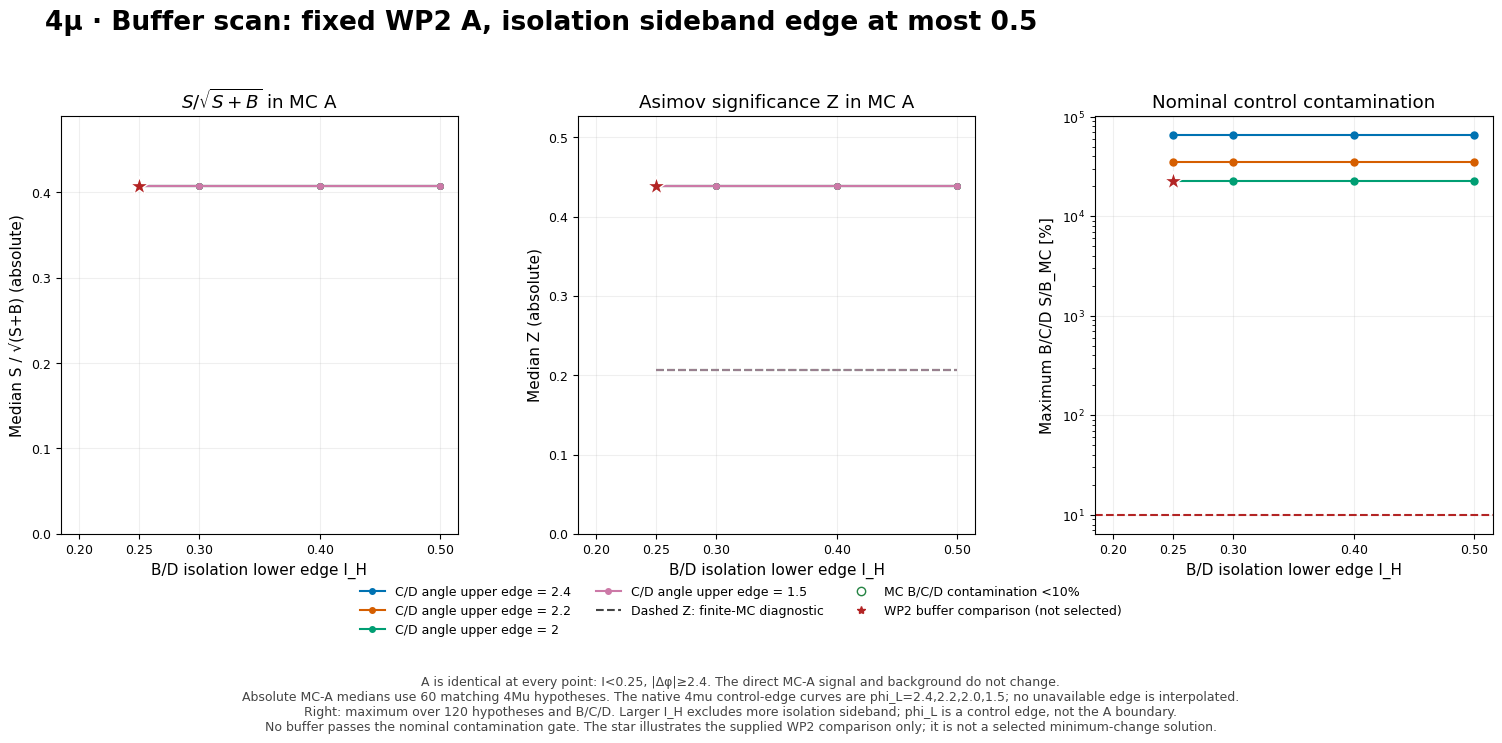

In [25]:
display(figure_lookup['gap_tradeoff'])


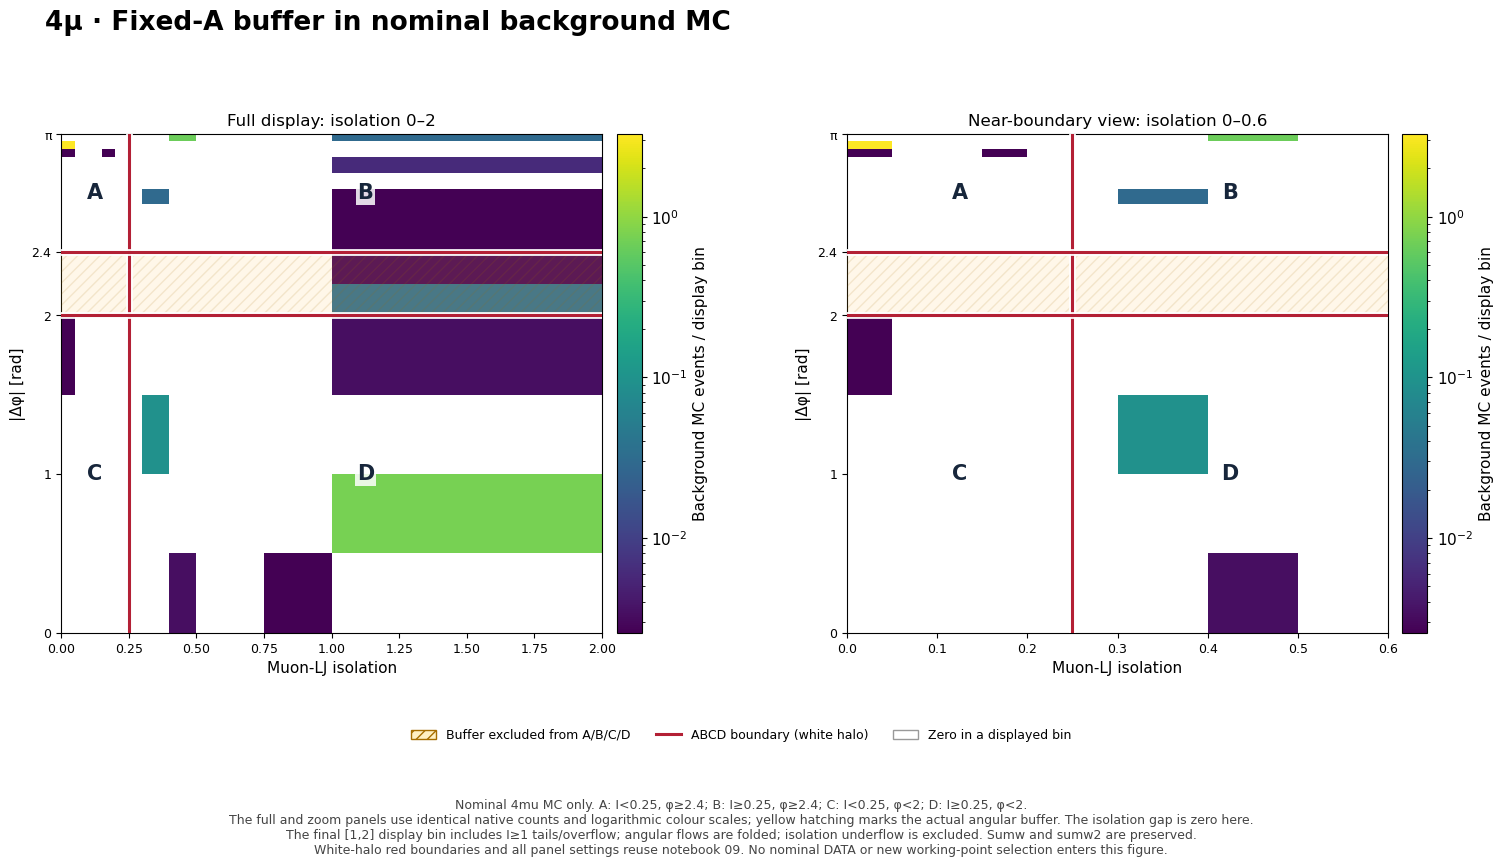

In [26]:
display(figure_lookup['buffer2d_nominal'])


### What the buffer-start closure scan tests

One panel fixes the C/D angular edge and scans the B/D isolation start $I_H$; the other fixes $I_H$ and scans the C/D upper angular edge $\phi_L$. **A remains at $(0.25,2.4)$.**

This diagnoses factorization and control statistics in nominal background MC, rather than Data closure or an A-boundary scan. The highlight marks the diagnostic comparison point $I_H=0.25$, $\phi_L=2.0$, without implying adoption. Read the control support and contamination conditions together.


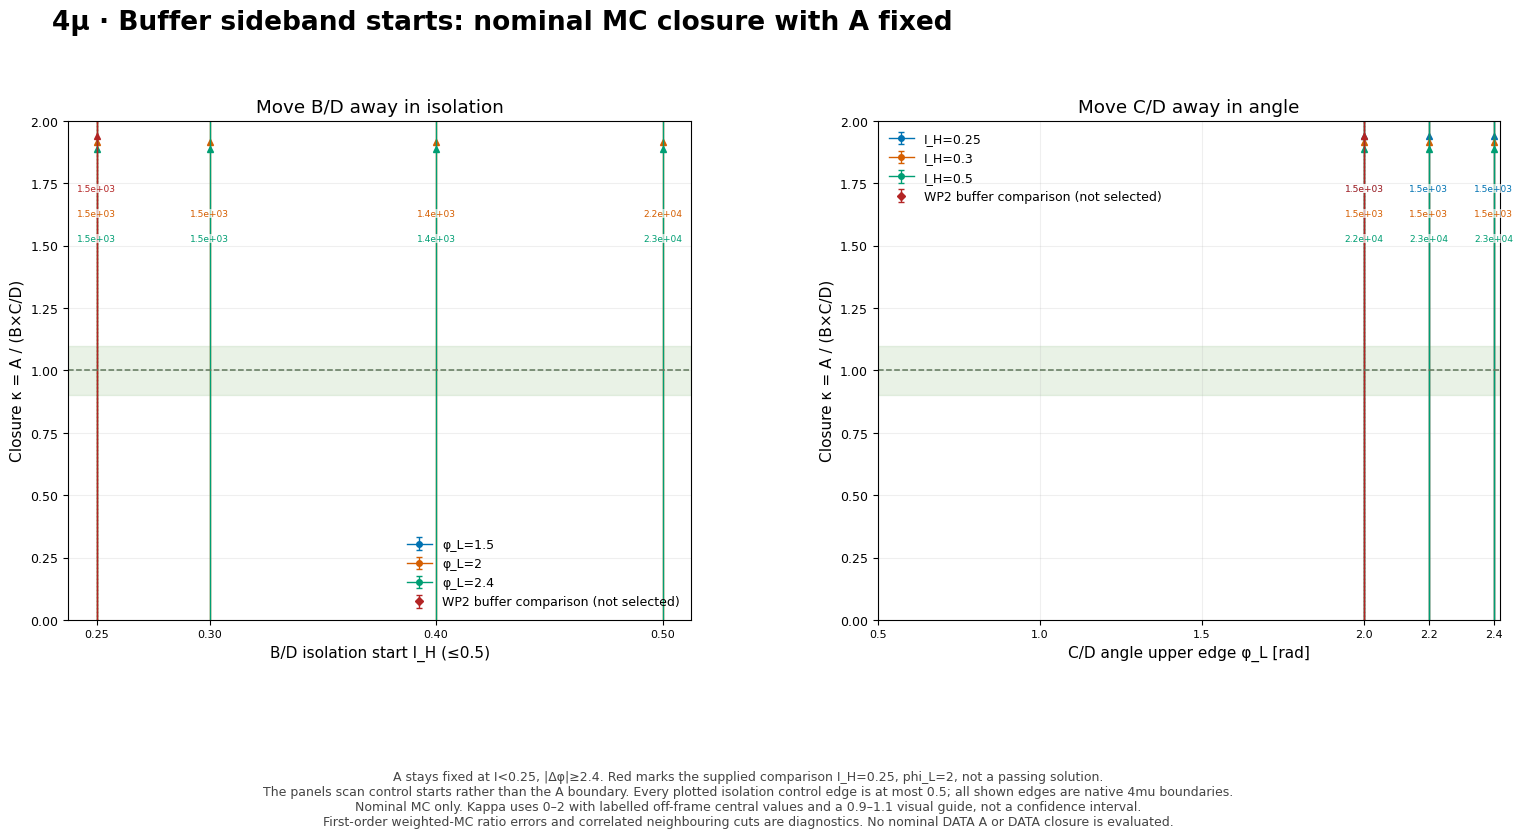

In [27]:
display(figure_lookup['gap_nominal_closure'])


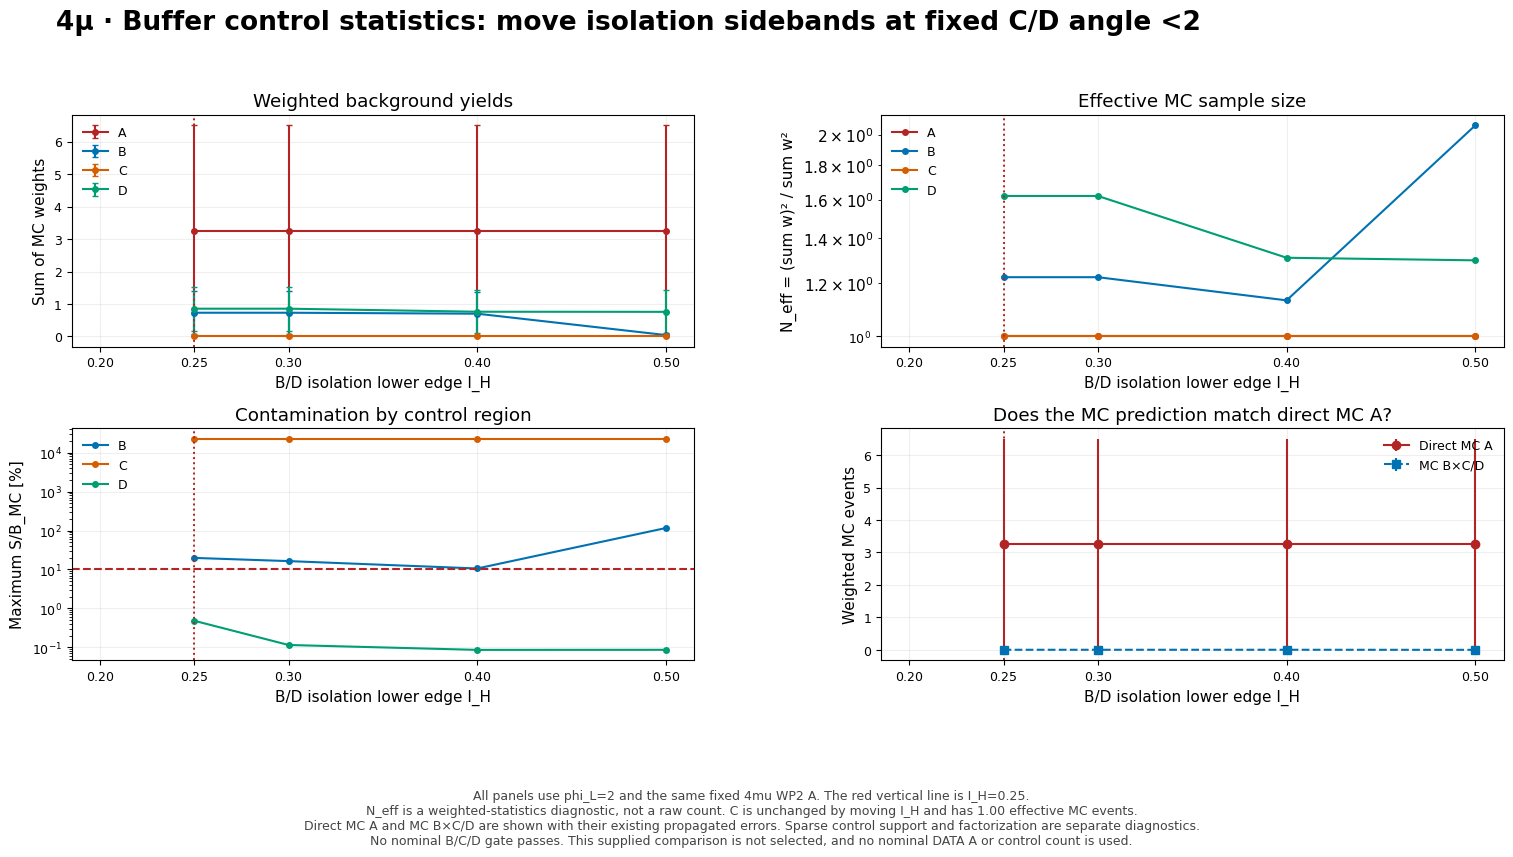

In [28]:
display(figure_lookup['gap_support'])


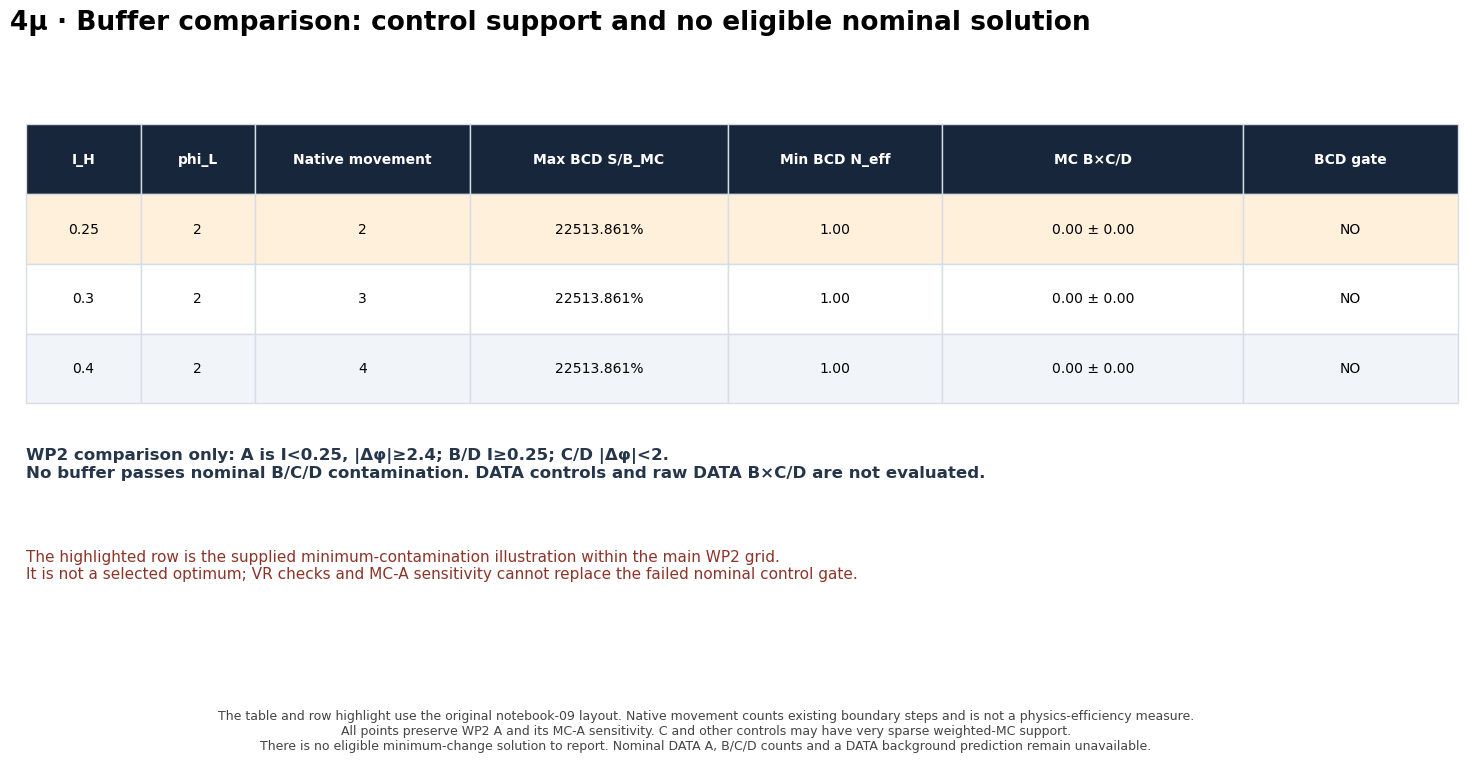

In [29]:
display(figure_lookup['gap_selection'])


### Low mass: buffer MC and Data VR closure

Scan buffer control edges while retaining WP2 A. Apply the same geometry separately to low-mass PP/PD/DP MC and public Data. Low-DD is not added as a primary Data validation because it currently fails the integrated gate.

The κ axis spans 0–2, with 0.9–1.1 as a visual reference. Data points that fail the gate or cannot be reconstructed exactly from public observations are omitted numerically, with a reason retained.


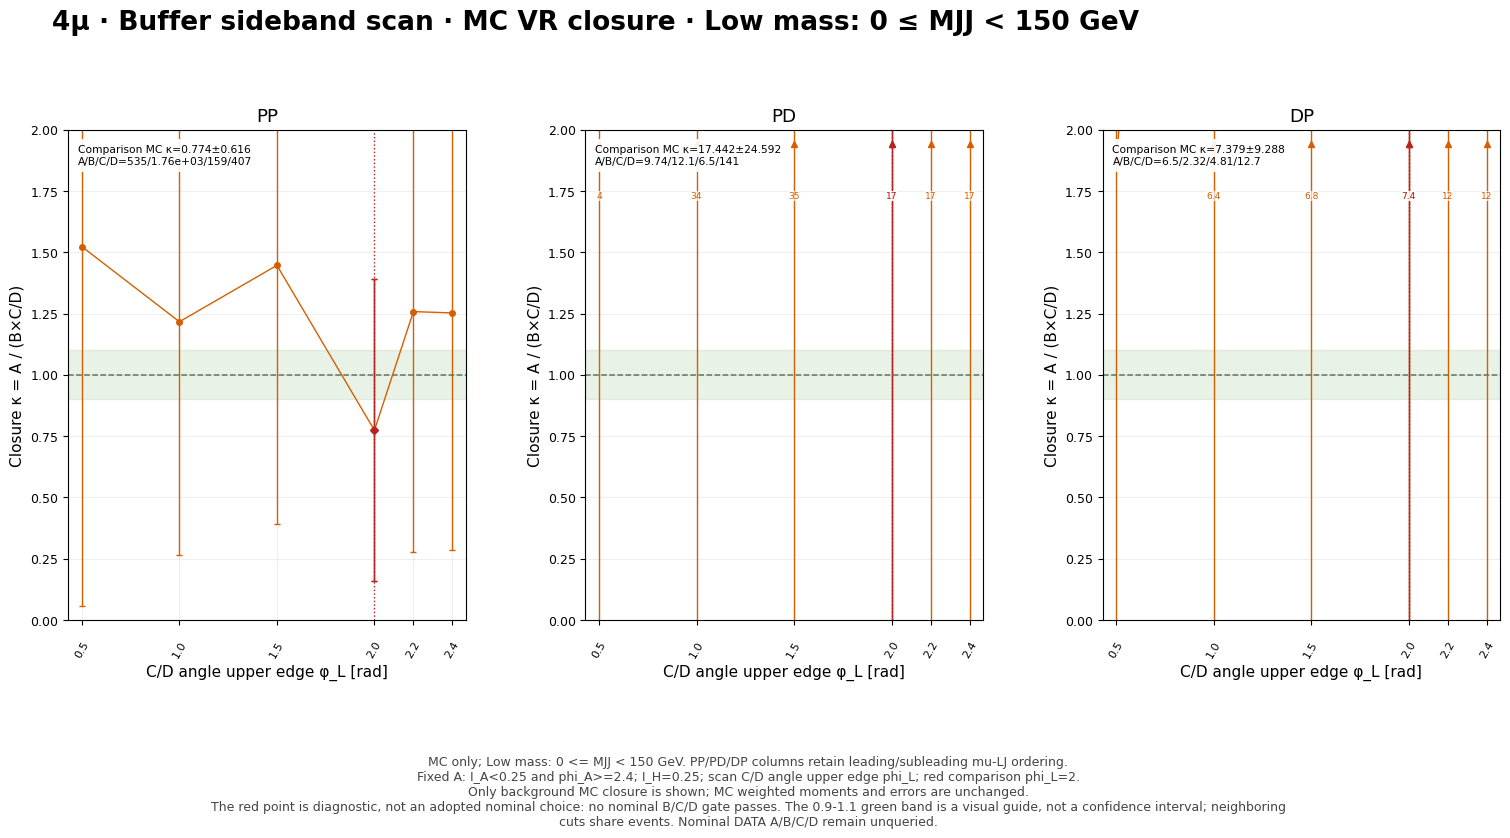

In [30]:
display(figure_lookup['gap_vr_mc_low'])


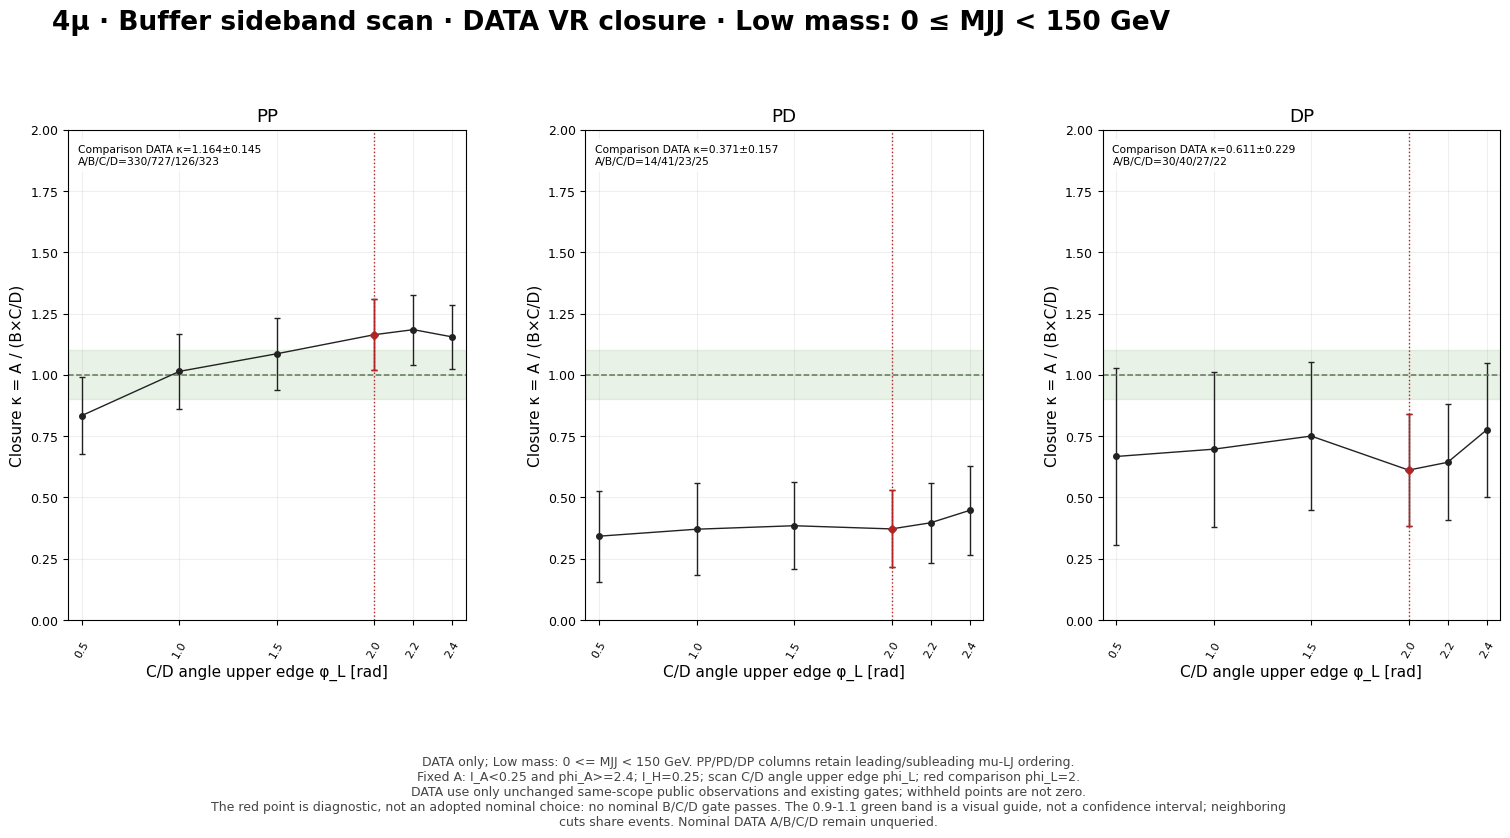

In [31]:
display(figure_lookup['gap_vr_data_low'])


### Intermediate mass: buffer MC and Data VR closure

Apply the same WP2 A and buffer boundaries to PP/PD/DP in $150\leq M<300$ GeV. Show only public Data that passes the all-120 A/B/C/D contamination gate for each candidate.

Even a buffer with relatively smaller nominal C contamination does not automatically pass the VR gate. If intermediate PP Data at the WP2 diagnostic point is withheld, retain that reason rather than substituting a nearby definition.


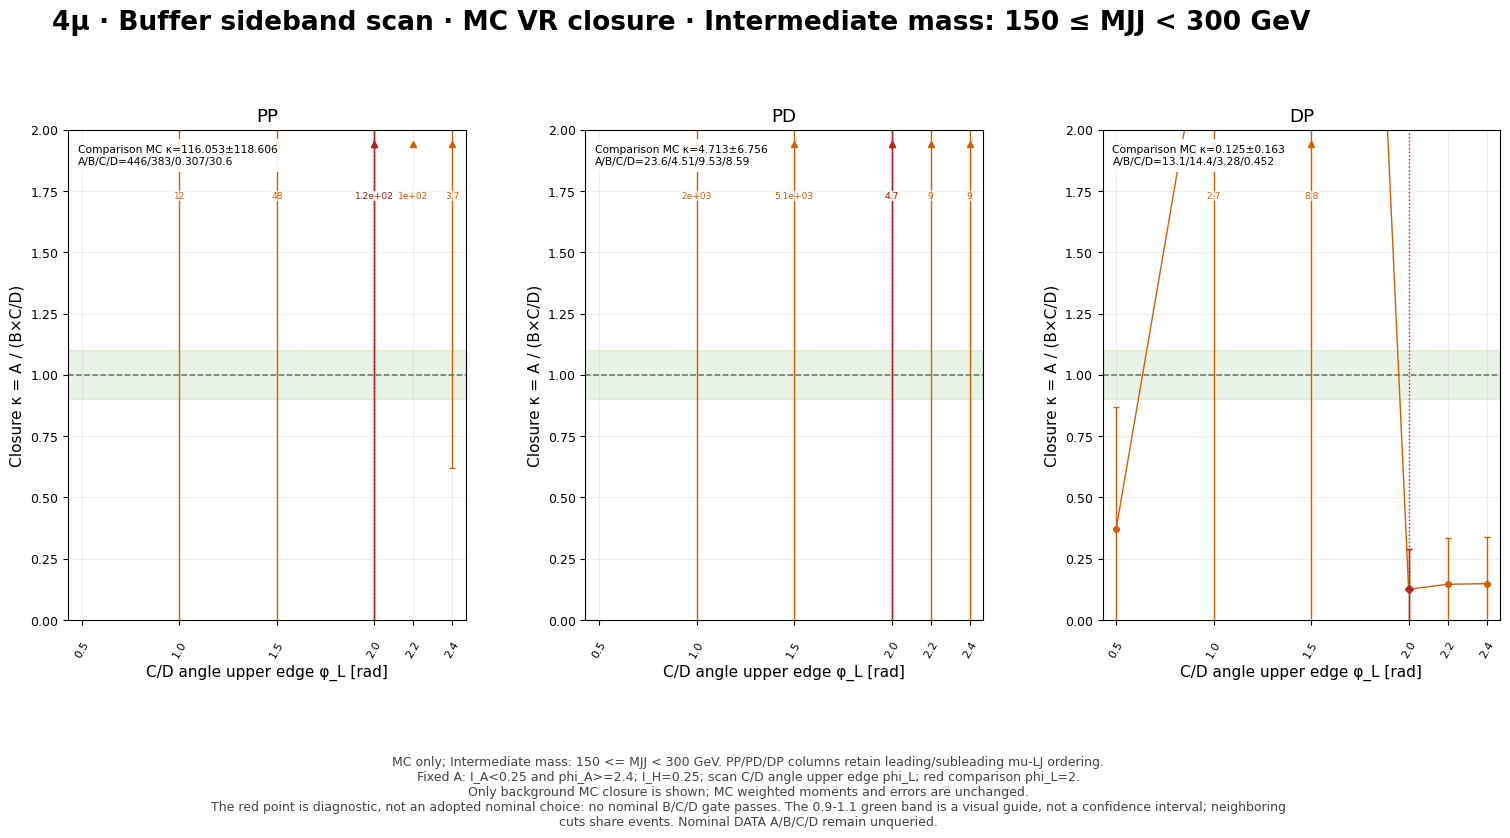

In [32]:
display(figure_lookup['gap_vr_mc_intermediate'])


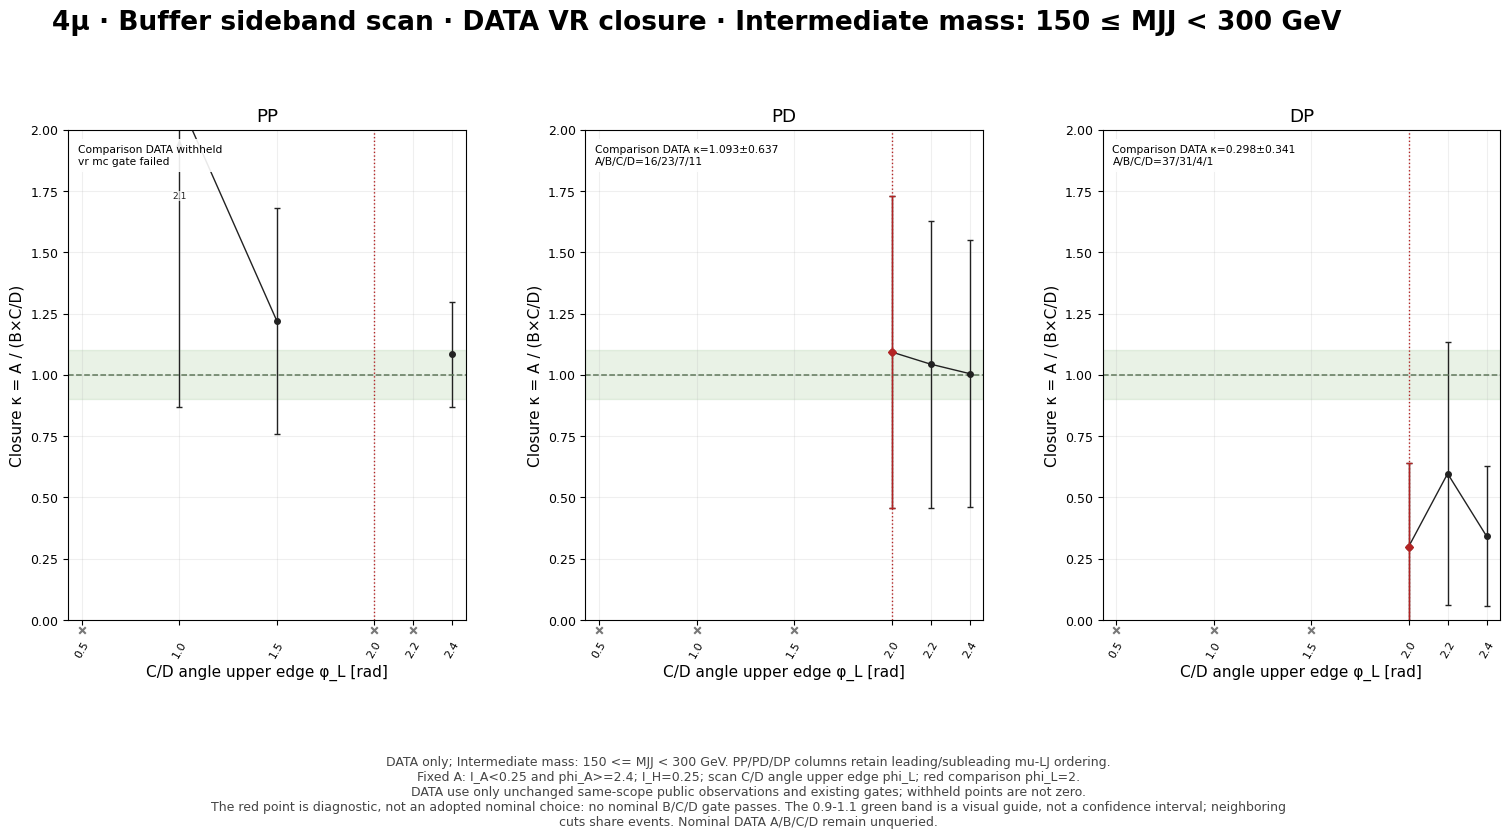

In [33]:
display(figure_lookup['gap_vr_data_intermediate'])


### Inclusive mass: buffer MC and Data availability

Inclusive buffer MC uses the actual integral over $M\geq0$. No public inclusive Data input with the same selection exists, so the Data figure shows its unavailable status and reason.

Do not interpret omitted points as κ=0 or closure failure. Neither low-plus-intermediate Data nor partial 2D bin sums are used to construct inclusive ABCD observations.


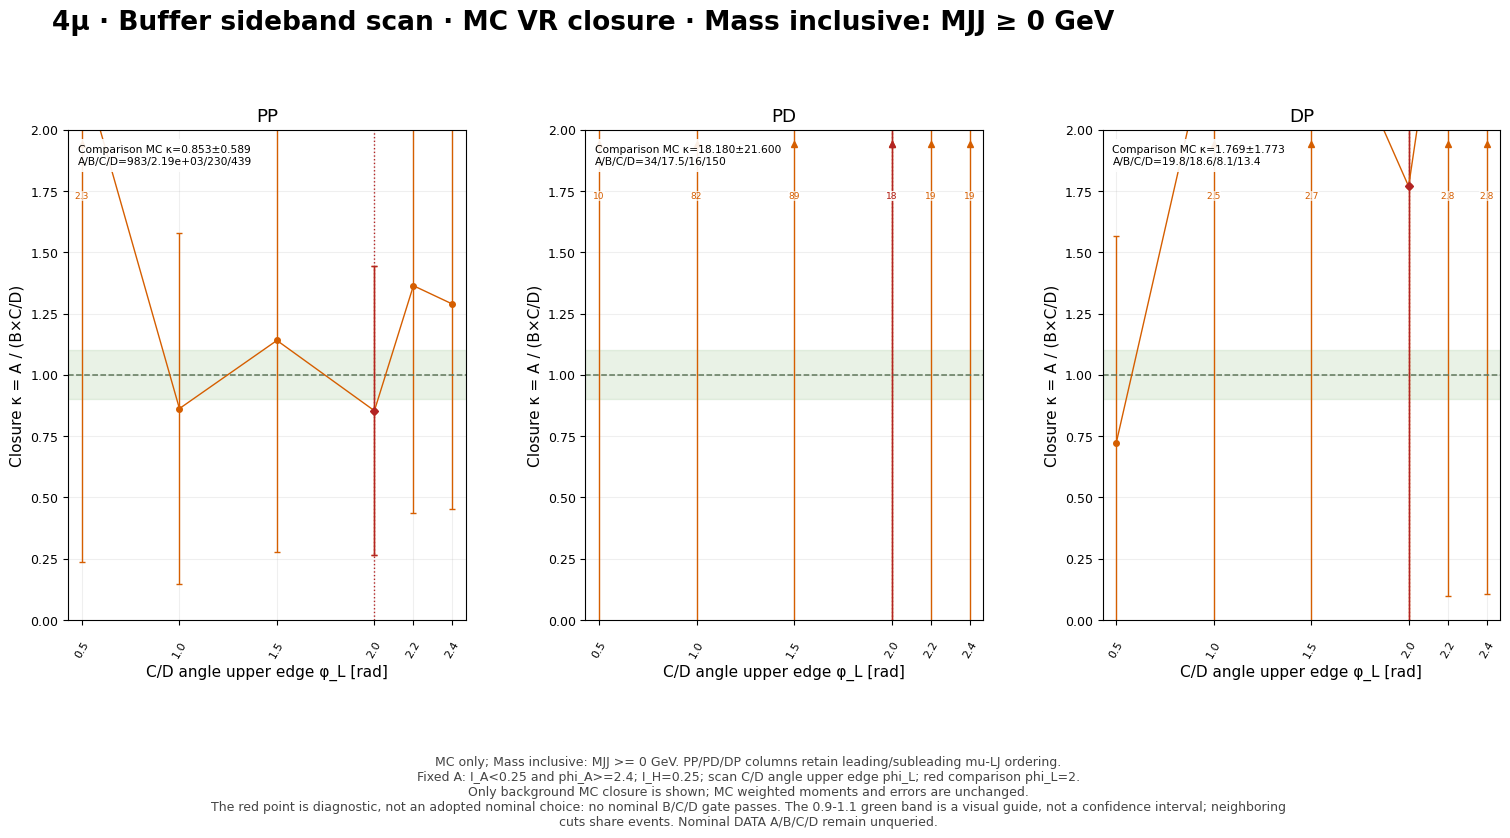

In [34]:
display(figure_lookup['gap_vr_mc_all'])


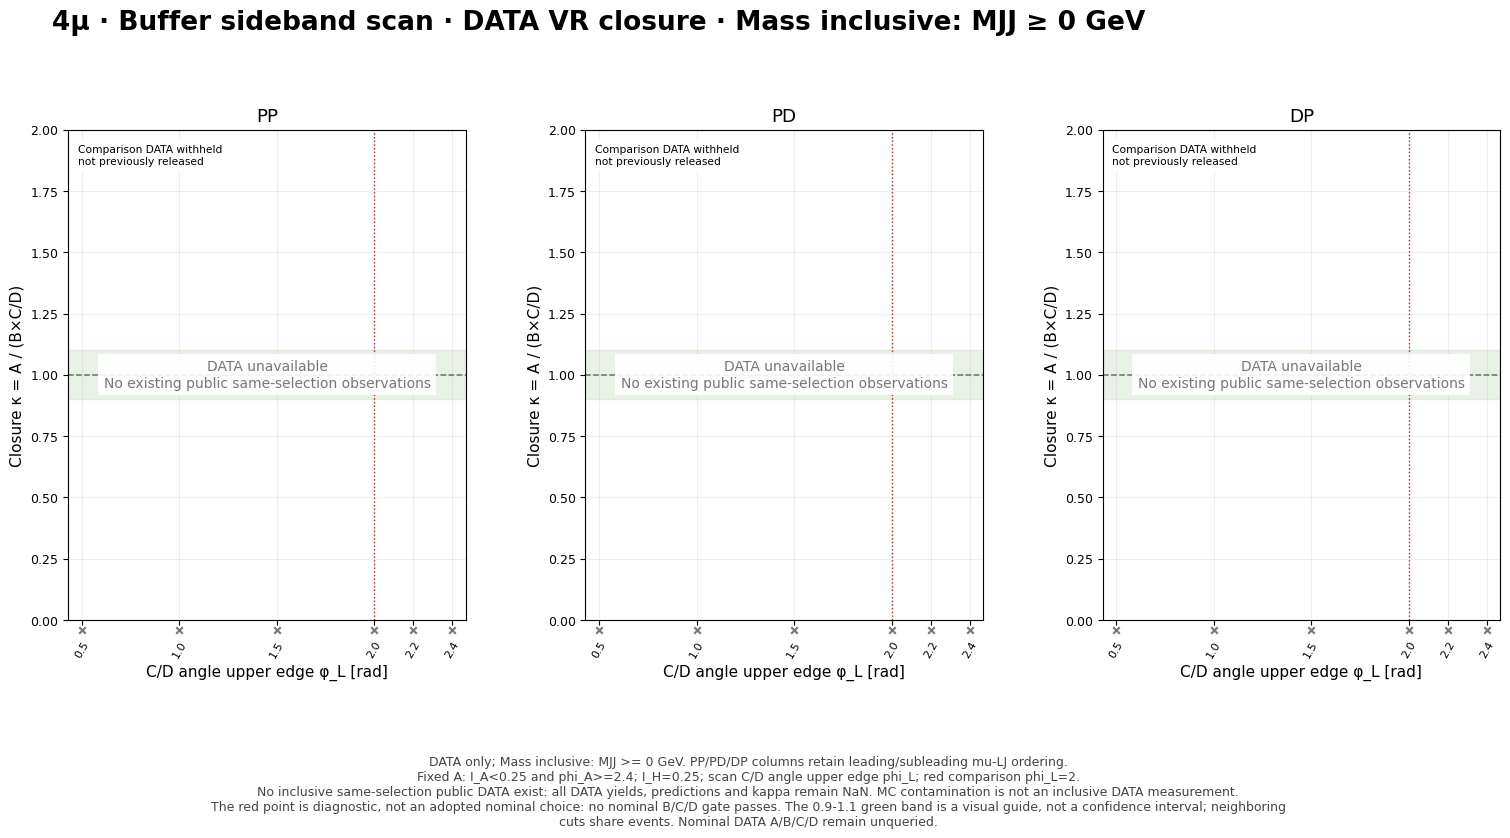

In [35]:
display(figure_lookup['gap_vr_data_all'])


### Data validation of the WP2 fixed-A buffer diagnostic point

As for loose boundaries, show 1D Data yields, predictions, κ, and MC contamination for each mass range before separate MC and masked Data 2D figures. A is $(0.25,2.4)$; the control comparison point is $I_H=0.25$, $\phi_L=2.0$. This is a **diagnostic comparison point** that fails the nominal gate.

Yellow /// marks the buffer excluded from ABCD; gray xx marks Data bins that cannot be displayed. These are distinct conditions and may overlap. Boundaries are overlays on existing stored bins, without new event splitting or interpolation.

Isolation underflow is excluded. The final displayed isolation bin $[1,2]$ includes the physical $[1,\infty)$ tail, and angular flows are folded into the edge bins. Display MC, signal purity, and Data use the same physical bins. Tails outside the zoomed view are retained in ABCD integrals. Inclusive Data shows the reason that public input is unavailable.


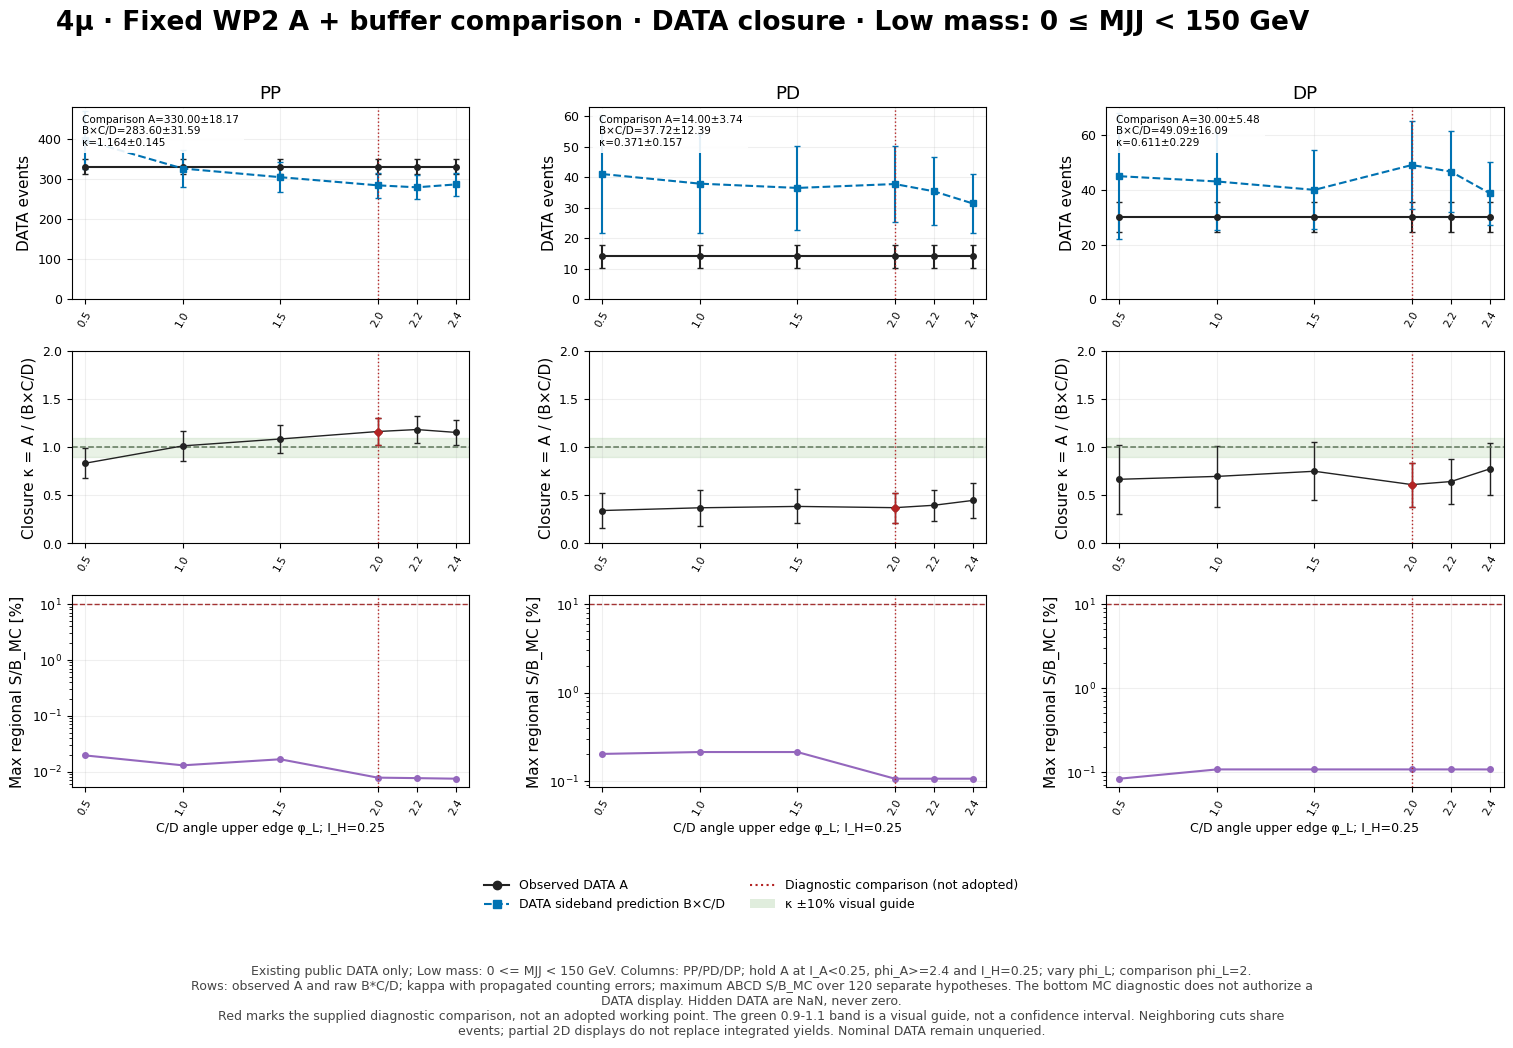

In [36]:
display(figure_lookup['buffer_final_1d_low'])


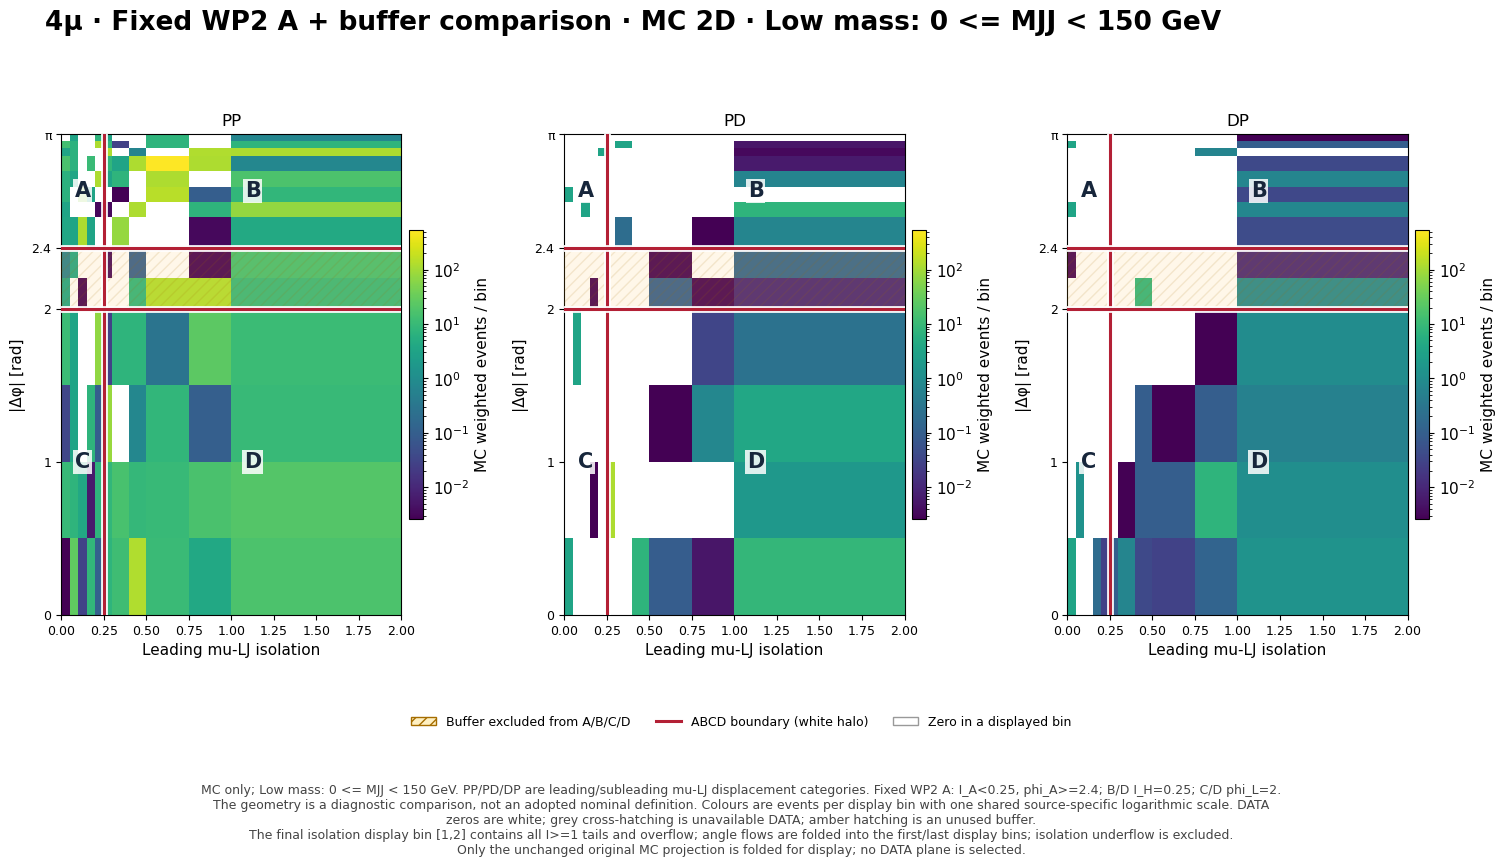

In [37]:
display(figure_lookup['buffer2d_mc_low'])


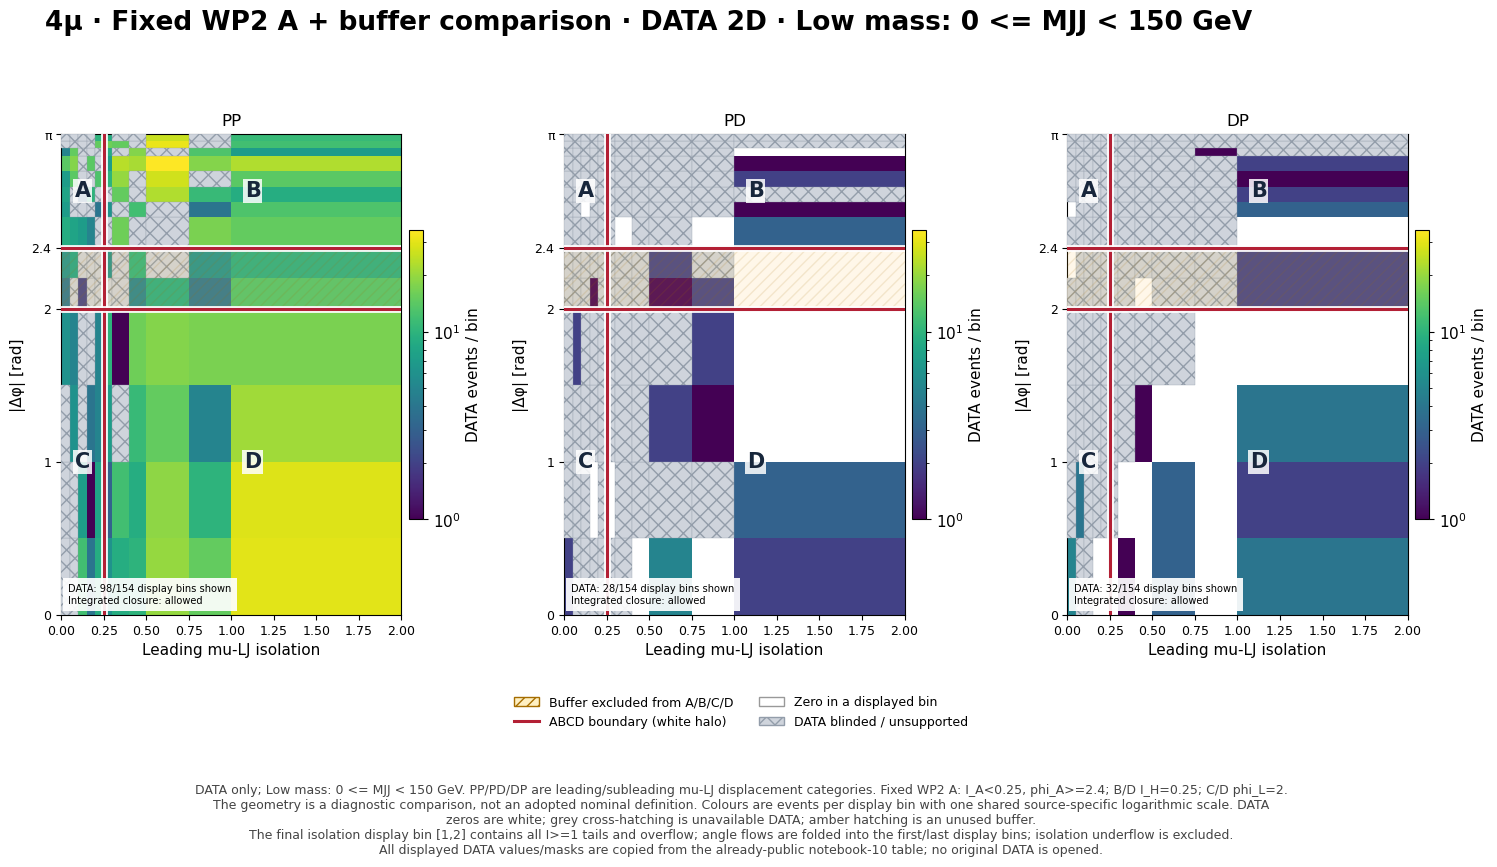

In [38]:
display(figure_lookup['buffer2d_data_low'])


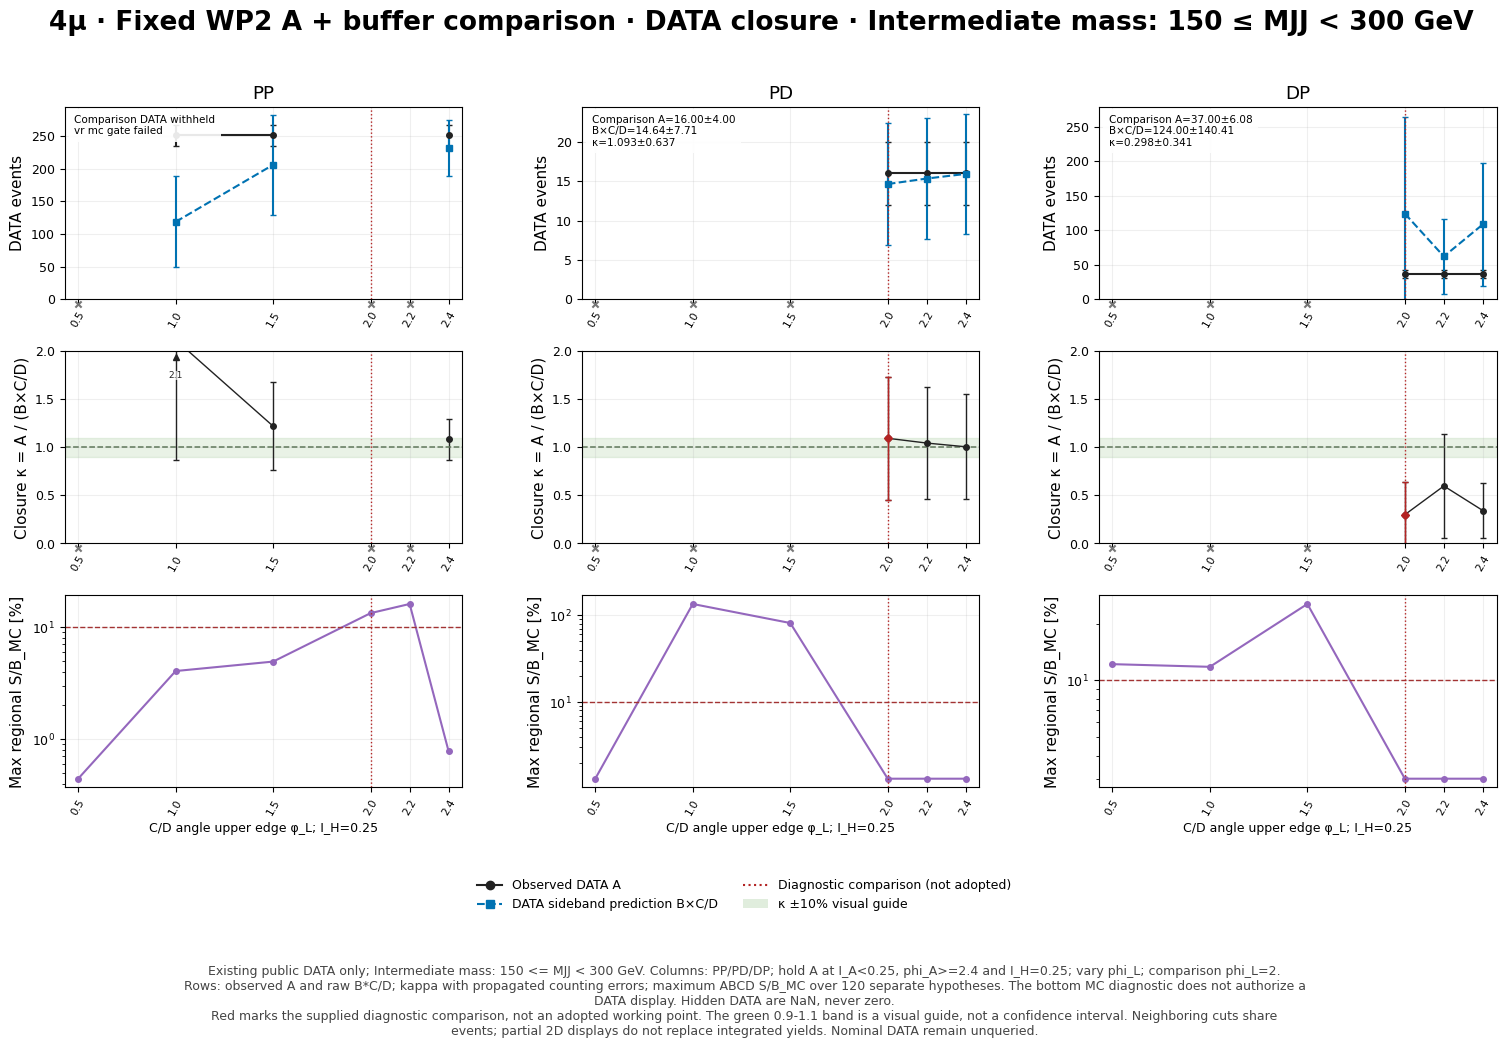

In [39]:
display(figure_lookup['buffer_final_1d_intermediate'])


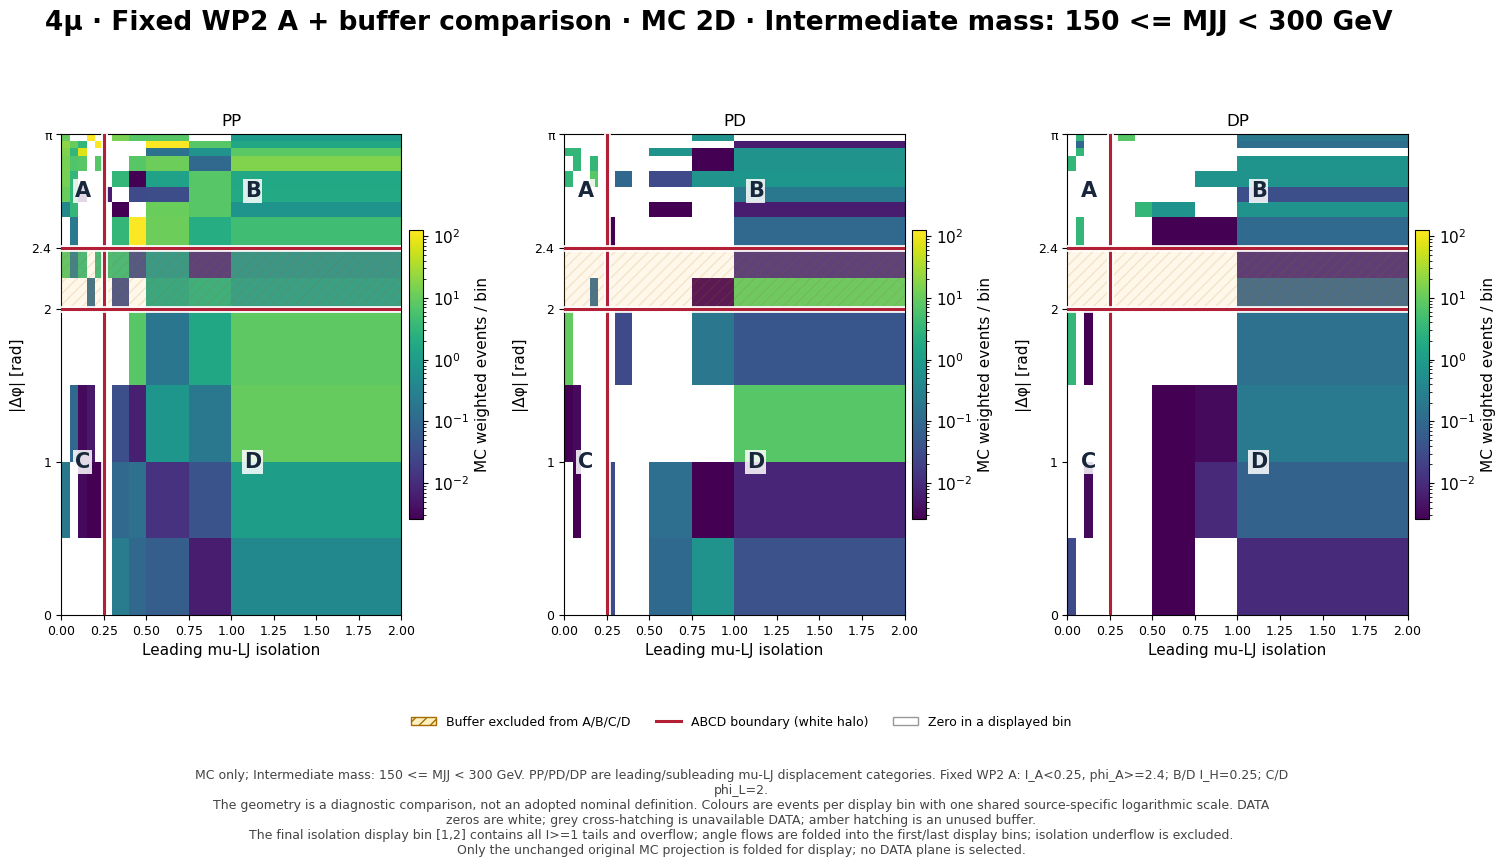

In [40]:
display(figure_lookup['buffer2d_mc_intermediate'])


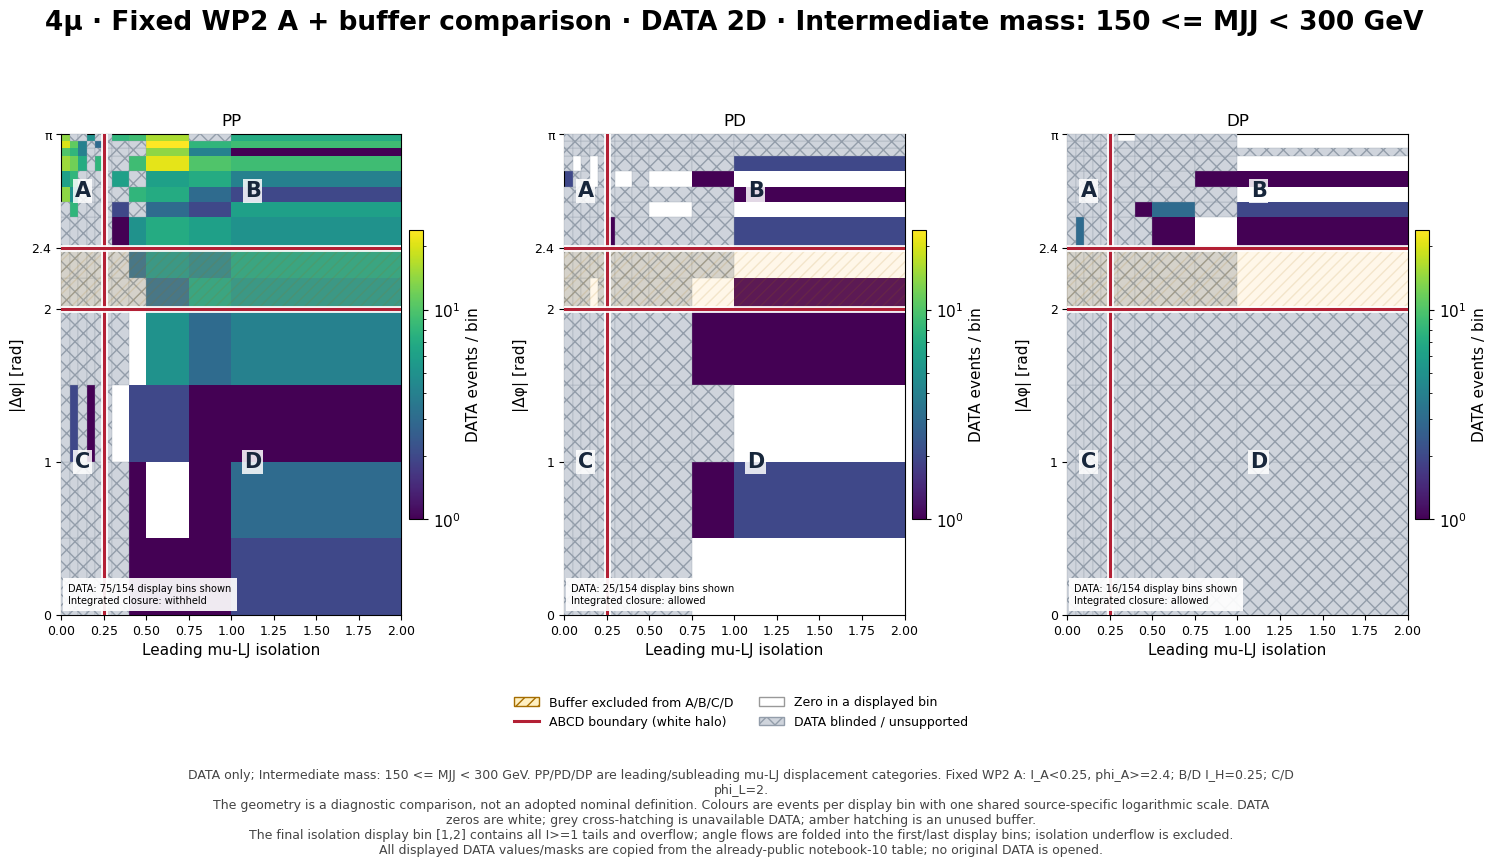

In [41]:
display(figure_lookup['buffer2d_data_intermediate'])


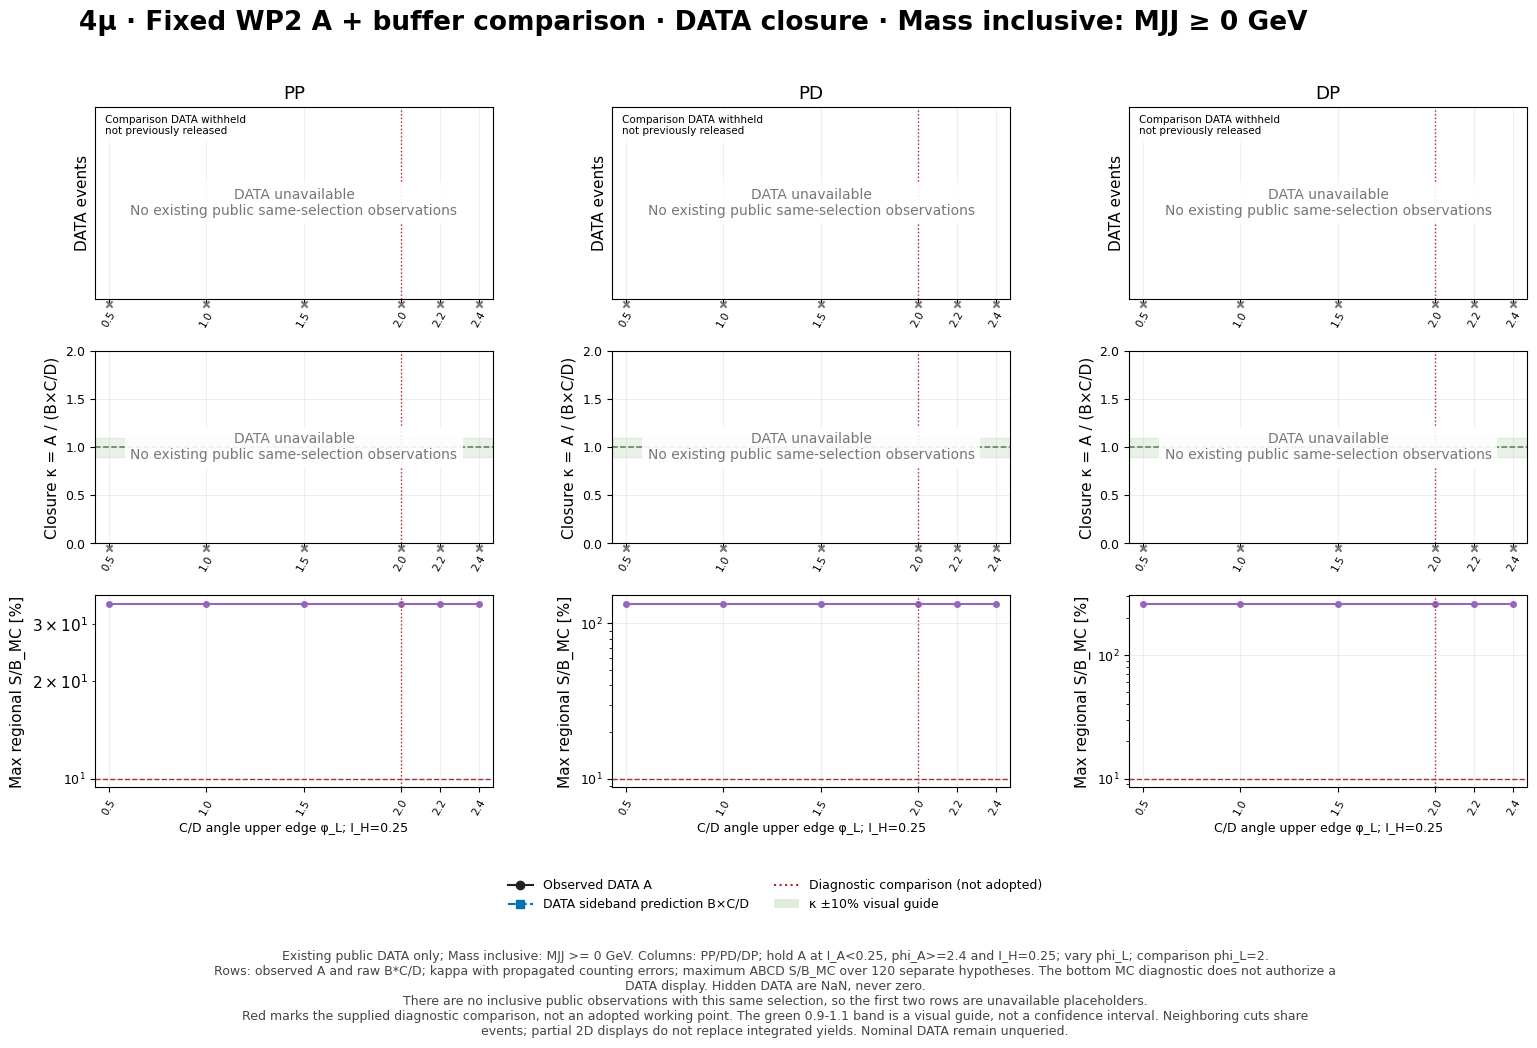

In [42]:
display(figure_lookup['buffer_final_1d_all'])


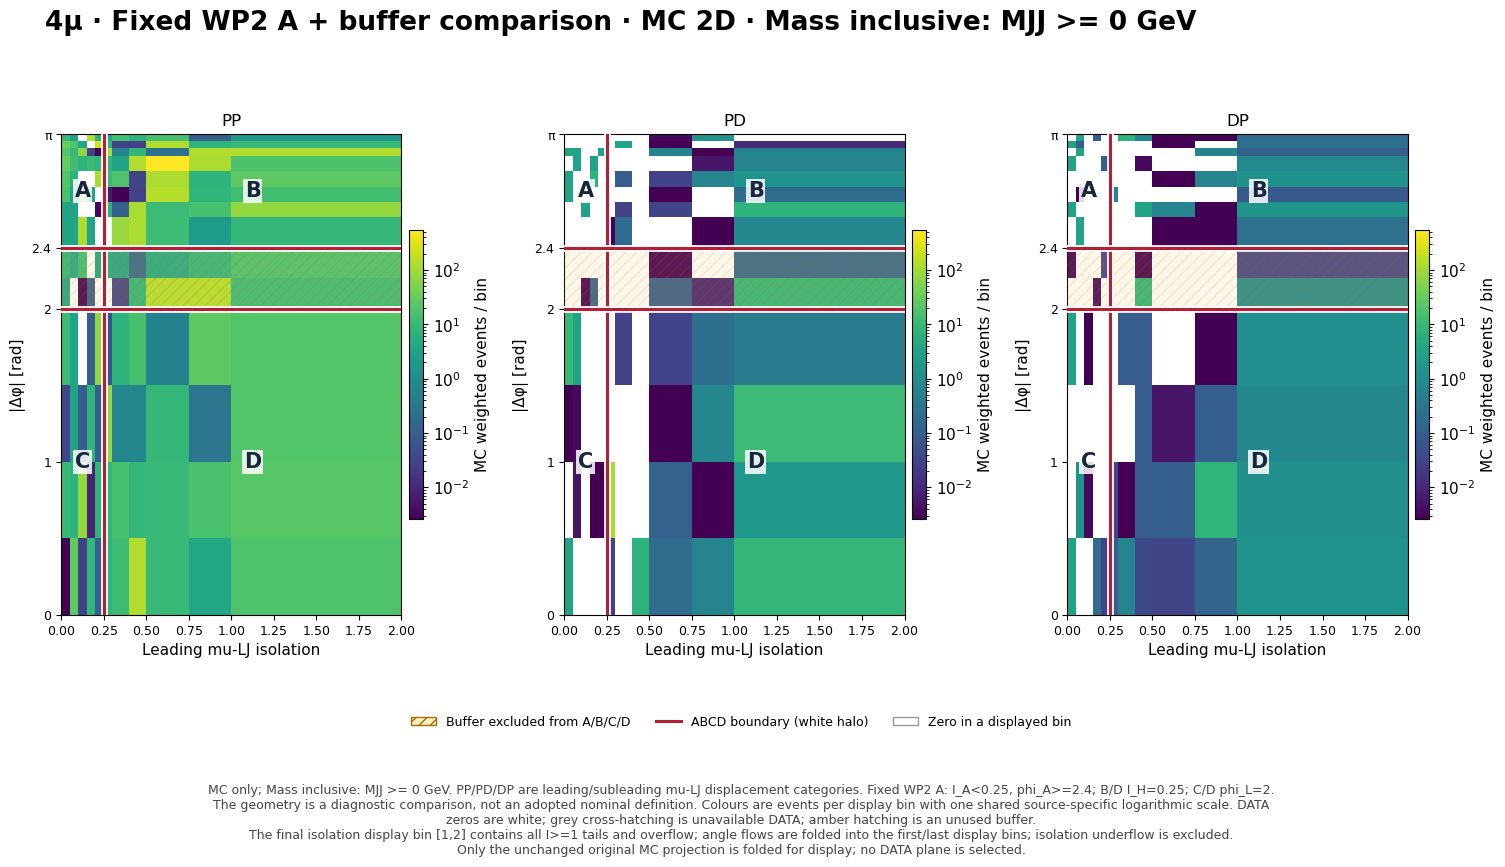

In [43]:
display(figure_lookup['buffer2d_mc_all'])


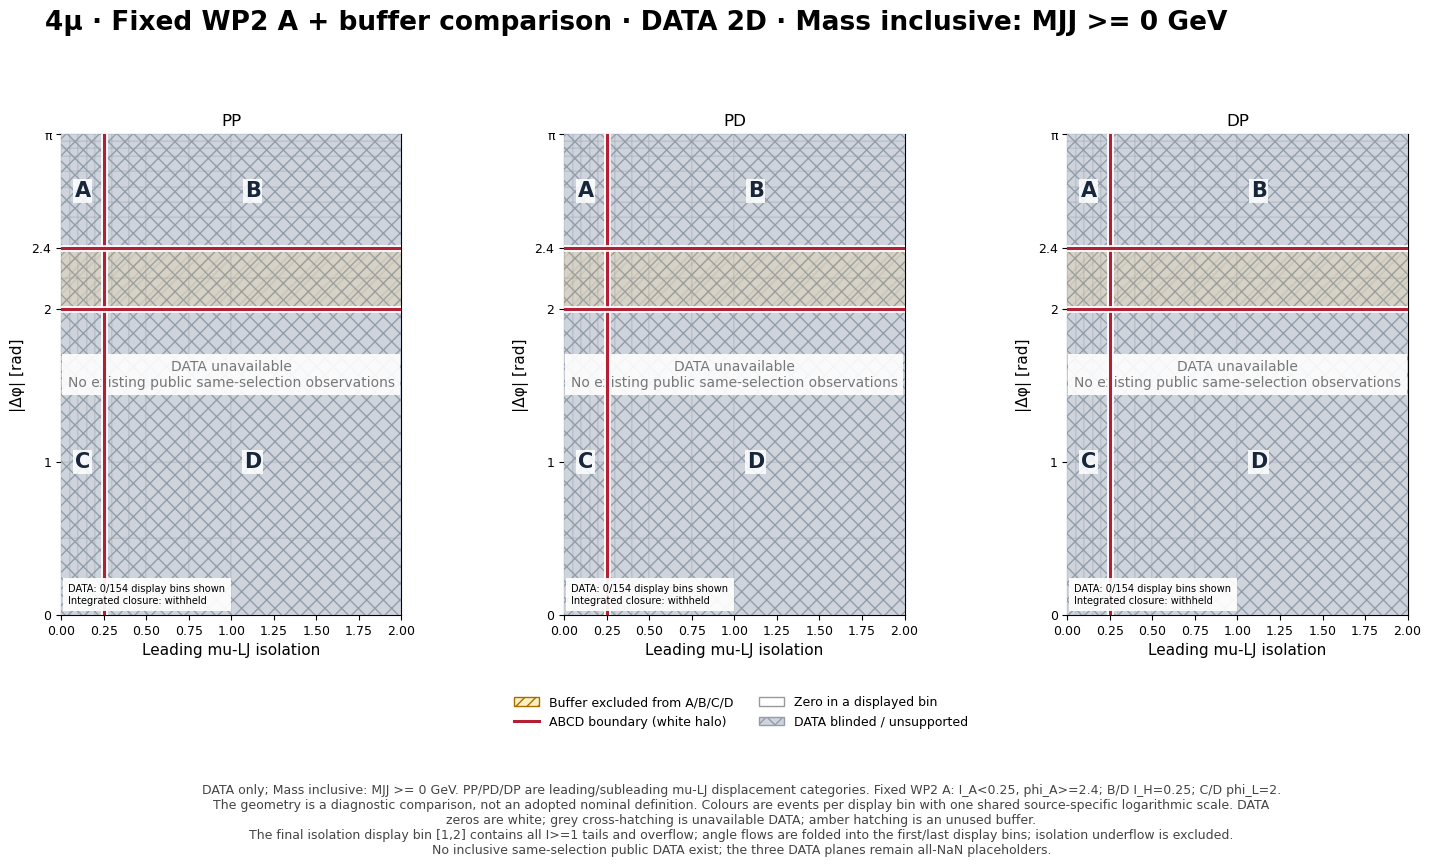

In [44]:
display(figure_lookup['buffer2d_data_all'])


In [45]:
display(Markdown('**Data closure for the WP2 fixed-A buffer diagnostic point**'))
display(vr.loc[vr['group'].eq('buffer_wp2') & ~vr.scope.eq('nominal_DD'),
    vr_columns].style.hide(axis='index'))
display(Markdown('Show only values passing both the MC gate and exact reuse of public observations in the same scope. Withheld is not zero.'))


**Data closure for the WP2 fixed-A buffer diagnostic point**

label,scope,display_allowed,A,B,C,D,pred,pred_error,kappa,kappa_error,reason
Buffered WP2,low_PP,True,330.000000,727.000000,126.000000,323.000000,283.597523,31.590268,1.163621,0.144581,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Buffered WP2,low_PD,True,14.000000,41.000000,23.000000,25.000000,37.720000,12.388508,0.371156,0.157160,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Buffered WP2,low_DP,True,30.000000,40.000000,27.000000,22.000000,49.090909,16.094901,0.611111,0.229330,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Buffered WP2,low_DD,False,nan,nan,nan,nan,nan,nan,nan,nan,VR_MC_GATE_FAILED
Buffered WP2,intermediate_PP,False,nan,nan,nan,nan,nan,nan,nan,nan,VR_MC_GATE_FAILED
Buffered WP2,intermediate_PD,True,16.000000,23.000000,7.000000,11.000000,14.636364,7.706633,1.093168,0.637181,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Buffered WP2,intermediate_DP,True,37.000000,31.000000,4.000000,1.000000,124.000000,140.413675,0.298387,0.341426,EXACT_PUBLIC_REGIONS_OR_ROW_SPACE_REUSE
Buffered WP2,intermediate_DD,False,nan,nan,nan,nan,nan,nan,nan,nan,DD_NOMINAL_MASS_DATA_PROTECTED
Buffered WP2,all_PP,False,nan,nan,nan,nan,nan,nan,nan,nan,NO_PUBLIC_SAME_SELECTION
Buffered WP2,all_PD,False,nan,nan,nan,nan,nan,nan,nan,nan,NO_PUBLIC_SAME_SELECTION


Show only values passing both the MC gate and exact reuse of public observations in the same scope. Withheld is not zero.

In [46]:
display(Markdown(
    '## 4. Inclusive cross-check: regional gates and public Data scope\n\n'
    'Inclusive MC and the availability of public Data with the same selection are separate questions. '
    'Inclusive PP/PD/DP Data currently carries the reason `NO_PUBLIC_SAME_SELECTION`. '
    'Neither partial 2D displays nor low-plus-intermediate sums construct a full inclusive yield. '
    'Neither nominal Data A nor its controls is queried.'
))


## 4. Inclusive cross-check: regional gates and public Data scope

Inclusive MC and the availability of public Data with the same selection are separate questions. Inclusive PP/PD/DP Data currently carries the reason `NO_PUBLIC_SAME_SELECTION`. Neither partial 2D displays nor low-plus-intermediate sums construct a full inclusive yield. Neither nominal Data A nor its controls is queried.

In [47]:
display(vr.loc[vr.mass_slice.eq('all') & vr['group'].isin(['loose_extended','buffer_wp2']),
    ['label','scope','display_allowed','max_S_B','reason']].style.hide(axis='index'))
display(tables['data_public_basis'].style.hide(axis='index'))
display(Markdown('Per-bin Data 2D support, purity, and public row-space decisions are retained in '
    '[data_bins.csv](10_4mu_final_check_outputs/tables/data_bins.csv). '
    'The number of visible bins does not authorize release of integrated closure.'))


label,scope,display_allowed,max_S_B,reason
Loose extended (MC-score diagnostic),all_PP,False,0.299734,NO_PUBLIC_SAME_SELECTION
Loose extended (MC-score diagnostic),all_PD,False,1.335793,NO_PUBLIC_SAME_SELECTION
Loose extended (MC-score diagnostic),all_DP,False,2.502068,NO_PUBLIC_SAME_SELECTION
Buffered WP2,all_PP,False,0.346649,NO_PUBLIC_SAME_SELECTION
Buffered WP2,all_PD,False,1.335720,NO_PUBLIC_SAME_SELECTION
Buffered WP2,all_DP,False,2.584980,NO_PUBLIC_SAME_SELECTION


scope,public_threshold_points,public_region_masks,rank,atomic_cells
low_PP,141,564,166,208
low_PD,114,456,138,208
low_DP,132,528,156,208
low_DD,0,0,0,208
intermediate_PP,125,500,150,208
intermediate_PD,100,400,123,208
intermediate_DP,111,444,136,208


Per-bin Data 2D support, purity, and public row-space decisions are retained in [data_bins.csv](10_4mu_final_check_outputs/tables/data_bins.csv). The number of visible bins does not authorize release of integrated closure.

## 5. Final comparison: MC contamination, controls, and VR validation

The primary comparison is between **extended loose A $(0.30,2.4)$** and **buffer WP2 A $(0.25,2.4)$ with $I_H=0.25$, $\phi_L=2.0$**. Both diagnostic points were defined before examining Data κ. Contamination is the **maximum $S/B_{\mathrm{MC}}$ across 120 individual signal hypotheses** in B/C/D. Nominal Data control counts and $BC/D$ predictions are not queried because the gate fails; NaN and a reason are shown instead.

The intermediate overlay places PP/PD/DP Data yields, closure, and MC contamination on a common isolation axis. The loose A edge $I_A$ varies, while the buffer retains WP2 A and varies the control edge $I_H$. Highlights mark **loose $I_A=0.30$** and **buffer $I_H=0.25$**, preserving the distinction between their roles.

Compare nominal MC-A significance for the same 60 matching 4Mu models. Extended loose A is wider than buffer A, changing signal and background acceptance. In the current MC, the background A yield is equal at the two points, while signal-yield differences produce a small difference in MC-A metrics. This diagnostic difference does not determine the sensitivity ranking of the final ABCD likelihood. Neither approach currently has a usable nominal control definition, and the final method and uncertainty treatment remain unresolved.

Releasing nominal controls requires **blinding geometry that protects both A regions**, in addition to the MC contamination gate. The current portion of buffer B in $[0.25,0.30)\times[2.4,\pi]$ overlaps extended loose A, preventing a common nominal Data control comparison with this definition. Retain $I_H=0.25$ as the diagnostic definition, without changing control boundaries or querying new Data.


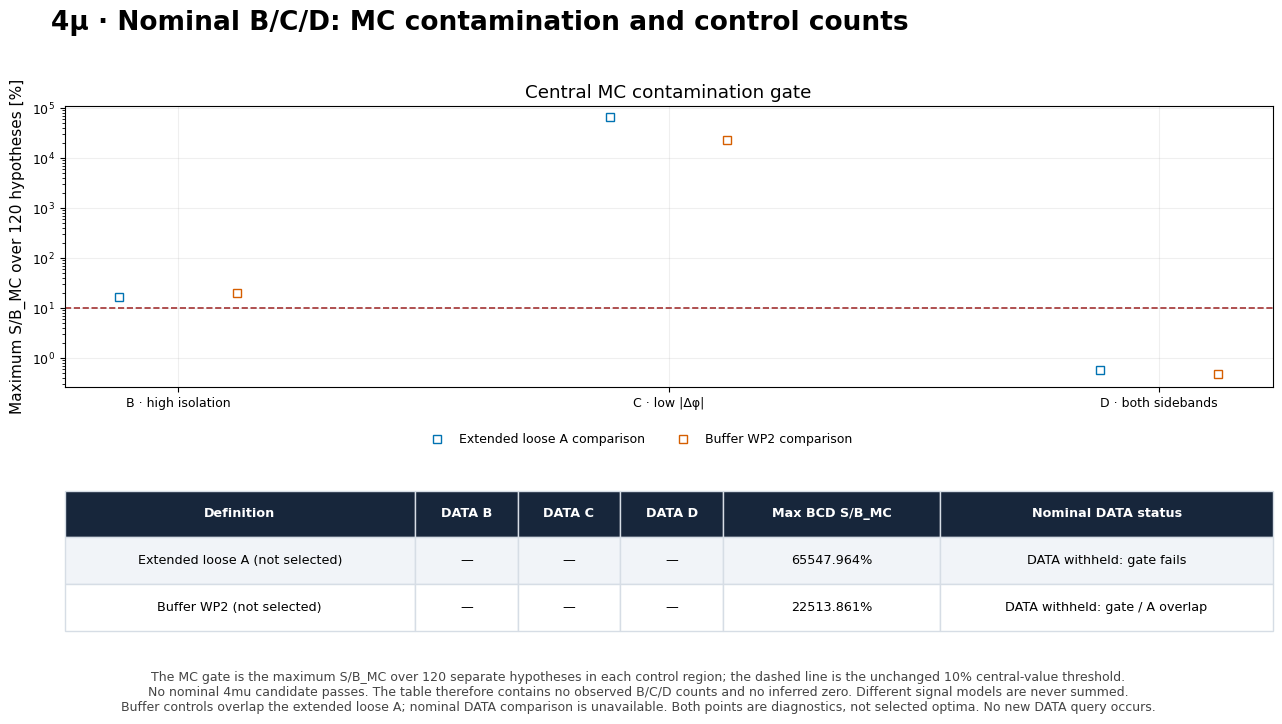

In [48]:
display(figure_lookup['if_nominal_data_contamination'])


In [49]:
diagnostic_ids = set(primary_candidates.candidate_id)
nominal_status = tables['data_nominal_status']
display(nominal_status.loc[nominal_status.candidate_id.isin(diagnostic_ids),
    ['candidate_id','mc_BCD_gate_pass','final_A_geometry_safe',
     'data_B','data_C','data_D','pred','pred_error','reason']].style.hide(axis='index'))
display(Markdown('**Nominal Data B/C/D and raw BC/D are not queried because the gate fails. NaN does not mean zero events.**'))
display(Markdown('Buffer B in [.25,.30)×|Δφ|≥2.4 overlaps extended loose A, so '
    'a common nominal Data comparison protecting both A regions is also unavailable. MC-gate and geometry decisions appear in separate columns. '
    'IH=.25 is retained for diagnostics, without new Data queries.'))


candidate_id,mc_BCD_gate_pass,final_A_geometry_safe,data_B,data_C,data_D,pred,pred_error,reason
L_i0p3_p2p4,False,True,nan,nan,nan,nan,nan,NOMINAL_MC_GATE_FAILED_NO_DATA_QUERY
G_WP2_i0p25_p2,False,False,nan,nan,nan,nan,nan,NOMINAL_MC_GATE_FAILED_NO_DATA_QUERY


**Nominal Data B/C/D and raw BC/D are not queried because the gate fails. NaN does not mean zero events.**

Buffer B in [.25,.30)×|Δφ|≥2.4 overlaps extended loose A, so a common nominal Data comparison protecting both A regions is also unavailable. MC-gate and geometry decisions appear in separate columns. IH=.25 is retained for diagnostics, without new Data queries.

### Intermediate mass: overlay of loose and buffer scans

Columns represent PP/PD/DP; rows show Data yields, κ, and maximum regional MC contamination. The common isolation coordinate is loose $I_A$ or buffer $I_H$. Loose A changes during the scan, whereas buffer A remains at $(0.25,2.4)$. Differences between their observed A yields are not interpreted as closure differences.

Highlighted lines mark **loose $I_A=0.30$** and **buffer $I_H=0.25$**, respectively. Neither is an adopted point passing the nominal gate. Points that fail the integrated Data gate are omitted with reasons, without filling them from partial 2D information. Nearby thresholds share events.


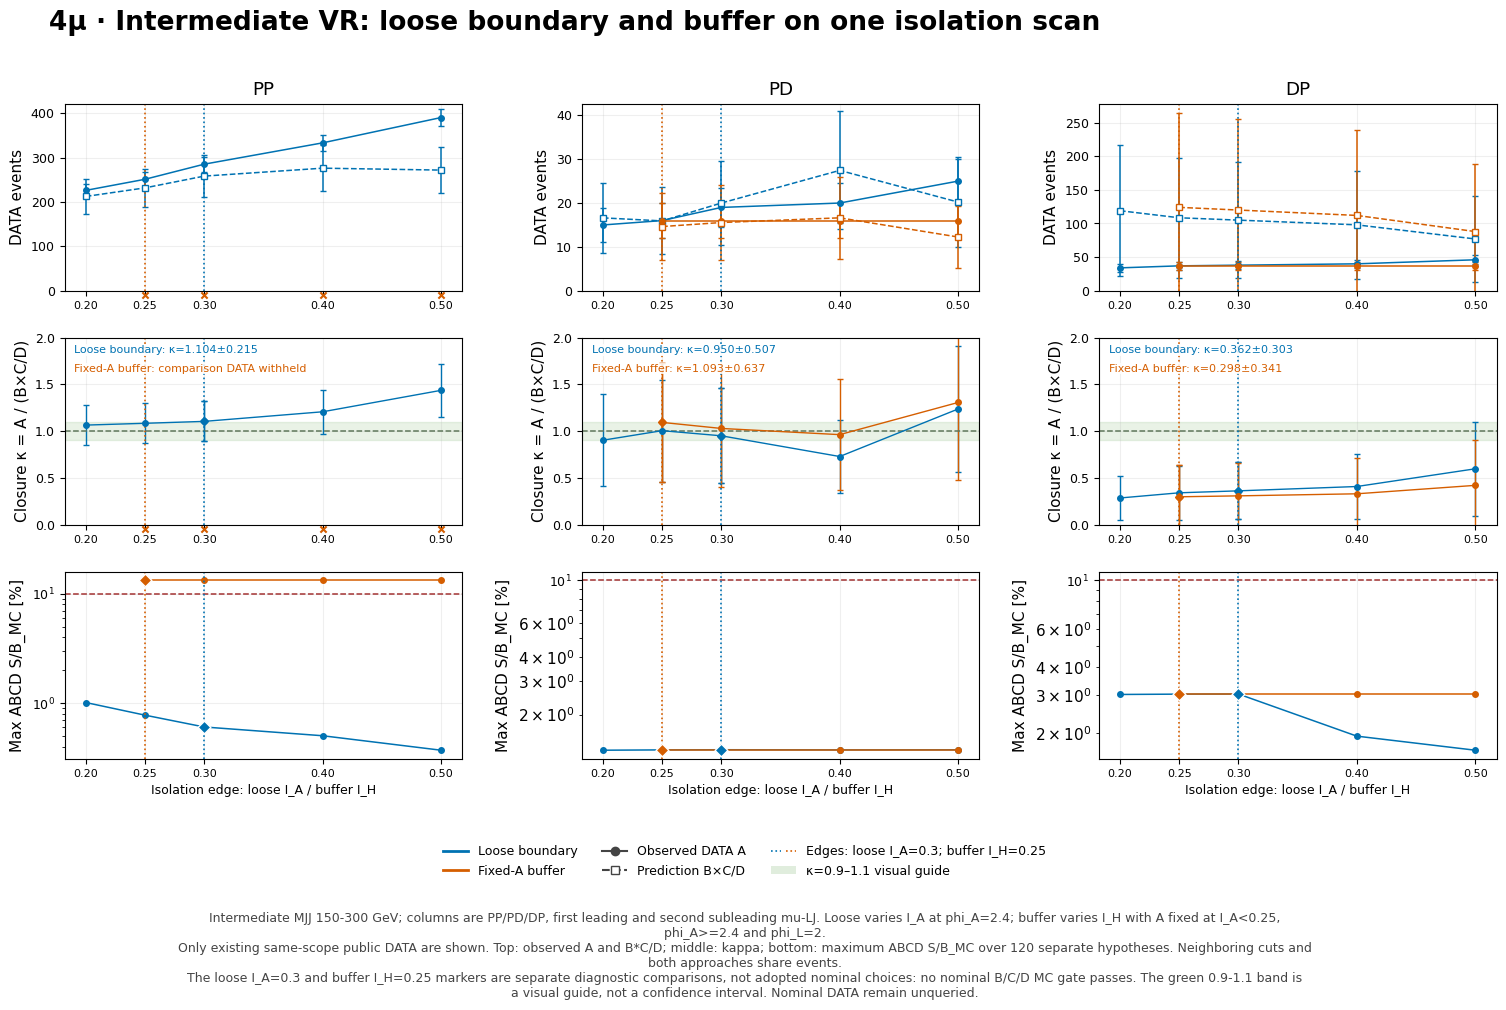

In [50]:
display(figure_lookup['final_intermediate_overlay'])

### Nominal MC significance: comparison of the same signal hypotheses

Compare the same 60 matching 4Mu models ordered by $m_B$, $m_{Z_D}$, and proper $c\tau$. Use the absolute $S/\sqrt{S+B}$, known-background Z, and finite-MC Z for each model, without summing hypothesis yields.

**Extended loose A is $(0.30,2.4)$; buffer fixed A is $(0.25,2.4)$.** Model-specific signal, background, and MC-A metrics can therefore differ; this is not a comparison with identical A regions. The maximum known-background Z at the extended loose point is an MC diagnostic before gating. Failed nominal B/C/D gates and limited control statistics remain separate constraints. The comparison table below also distinguishes the diagnostic criterion from adoption.


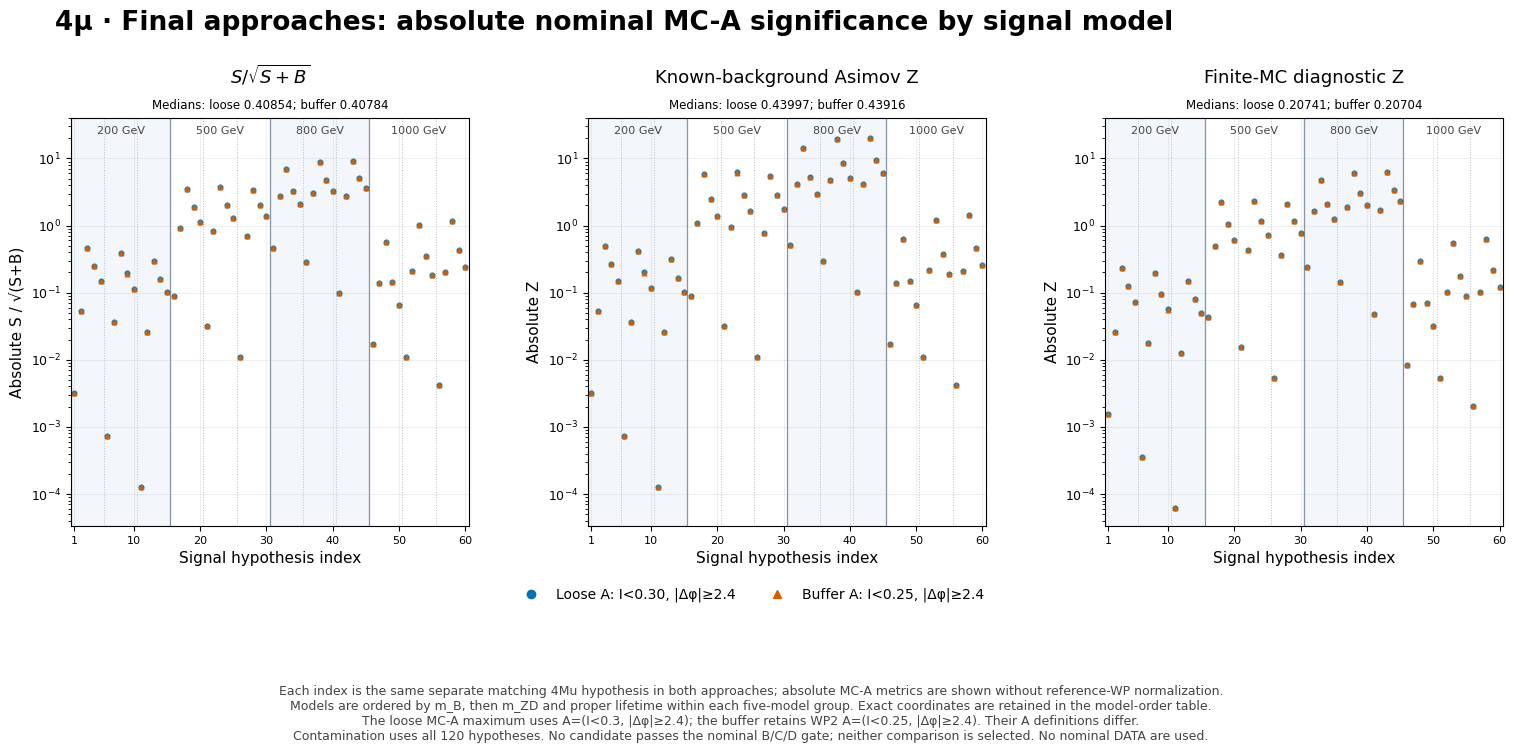

In [51]:
display(figure_lookup['final_significance_comparison'])

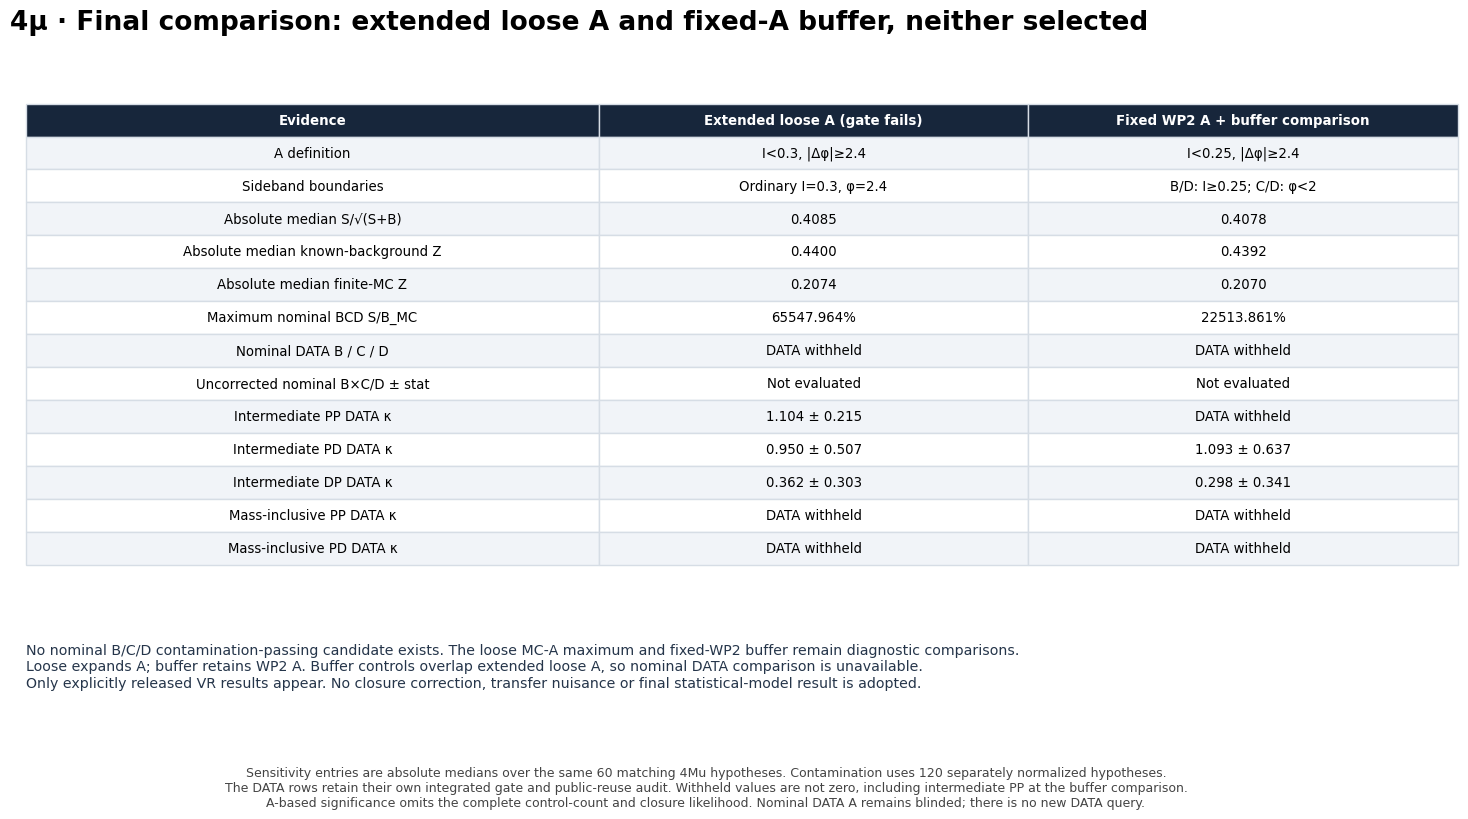

In [52]:
display(figure_lookup['if_meeting_comparison'])


In [53]:
display(Markdown('### Comparison basis and outstanding decisions for the two approaches'))
display(primary_candidates[['label','role','a_iso','a_phi','b_iso','c_phi',
    's_sqrt_s_plus_b_median','z_known_b_median','z_mc_stat_diagnostic_median',
    'max_S_B_BCD','min_sideband_neff','purity_pass_BCD']].style.hide(axis='index'))
display(Markdown('**Auxiliary anchors, distinct from the primary comparison and adopted working points.**'))
display(tables['plot_candidates'].loc[~tables['plot_candidates'].is_primary.astype(bool),
    ['label','role','a_iso','a_phi','b_iso','c_phi','purity_pass_BCD']].style.hide(axis='index'))
display(tables['decision_summary'].style.hide(axis='index'))
display(Markdown(
    '**Current conclusion:** neither loose nor buffer has a supported nominal control definition. '
    'Extended loose (.30,2.4) is the MC diagnostic with the largest median known-background Z before gating among the 20 primary points; '
    'the buffer retains WP2 A(.25,2.4). Their A regions and MC-A sensitivities differ, and neither point is adopted. '
    'Large MC contamination reflects limited current MC support, rather than a measurement of the actual Data background. '
    'The final likelihood incorporating control statistics, leakage, VR nonclosure, and DD transfer uncertainty remains unresolved.'
))


### Comparison basis and outstanding decisions for the two approaches

label,role,a_iso,a_phi,b_iso,c_phi,s_sqrt_s_plus_b_median,z_known_b_median,z_mc_stat_diagnostic_median,max_S_B_BCD,min_sideband_neff,purity_pass_BCD
Loose extended (MC-score diagnostic),diagnostic,0.300000,2.400000,0.300000,2.400000,0.408540,0.439965,0.207413,655.479640,1.000000,False
Buffered WP2,diagnostic,0.250000,2.400000,0.250000,2.000000,0.407838,0.439157,0.207042,225.138606,1.000000,False


**Auxiliary anchors, distinct from the primary comparison and adopted working points.**

label,role,a_iso,a_phi,b_iso,c_phi,purity_pass_BCD
Loose WP2 (reference only),diagnostic,0.250000,2.400000,0.250000,2.400000,False
Buffered WP1,diagnostic,0.300000,2.400000,0.300000,2.000000,False


strategy,candidates,main_candidates,positive_control_candidates,nominal_BCD_gate_pass,minimum_supported_max_S_B,limiting_region,limiting_sample,selected,status,interpretation
loose,20,20,20,0,16.933229,C,4Mu_800GeV_5p0GeV_5p0mm,False,NO_NOMINAL_GATE_PASS,Minimum contamination is diagnostic; this is not an adopted point satisfying statistical support and disclosure requirements
buffer_wp2,42,24,21,0,225.138606,C,4Mu_800GeV_1p2GeV_1p2mm,False,NO_NOMINAL_GATE_PASS,Minimum contamination is diagnostic; this is not an adopted point satisfying statistical support and disclosure requirements
buffer_wp1,36,18,18,0,226.746739,C,4Mu_800GeV_1p2GeV_1p2mm,False,NO_NOMINAL_GATE_PASS,Minimum contamination is diagnostic; this is not an adopted point satisfying statistical support and disclosure requirements


**Current conclusion:** neither loose nor buffer has a supported nominal control definition. Extended loose (.30,2.4) is the MC diagnostic with the largest median known-background Z before gating among the 20 primary points; the buffer retains WP2 A(.25,2.4). Their A regions and MC-A sensitivities differ, and neither point is adopted. Large MC contamination reflects limited current MC support, rather than a measurement of the actual Data background. The final likelihood incorporating control statistics, leakage, VR nonclosure, and DD transfer uncertainty remains unresolved.

## Statistical conventions

### Uncertainty and sensitivity definitions

For disjoint regions, use weighted MC $X=\sum w$, $V_X=\sum w^2$, and unweighted Data $V_X=N_X$. For positive B/C/D,

$$P=\frac{BC}{D},\qquad
V_P=\left(\frac{C}{D}\right)^2V_B+
\left(\frac{B}{D}\right)^2V_C+
\left(\frac{BC}{D^2}\right)^2V_D.$$

$$\kappa=\frac{A}{P},\qquad
V_\kappa=\frac{V_A}{P^2}+\frac{A^2}{P^4}V_P,\qquad
N_{\mathrm{eff}}=\frac{(\sum w)^2}{\sum w^2}.$$

The prediction is undefined for D=0. A zero numerator is not assigned an artificial zero symmetric uncertainty. Symmetric errors in sparse samples are diagnostic approximations, not intervals with exact coverage. $N_{\mathrm{eff}}$ is not called raw entries.

For each signal hypothesis, let $s=S_A^{\mathrm{MC}}$ and $b=B_A^{\mathrm{MC}}$. The known-background diagnostic is

$$Z_0=\sqrt{2[(s+b)\ln(1+s/b)-s]}.$$

The finite-MC diagnostic uses $v=V_A^{\mathrm{MC}}$:

$$Z_v=\sqrt{2\left[(s+b)\ln\frac{(s+b)(b+v)}{b^2+(s+b)v}
-\frac{b^2}{v}\ln\left(1+\frac{vs}{b(b+v)}\right)\right]}.$$

These values are not the final ABCD likelihood incorporating B/C/D controls, leakage, and nonclosure transfer. The 0.9–1.1 band in κ figures is a visual reference, not a confidence interval.


The auxiliary sensitivity $S/\sqrt{S+B}$ also uses model-specific nominal MC A yields. Compare absolute values for the same 60 matching models; the 10–90% model range reflects variation across hypotheses rather than statistical uncertainty. The central nonclosure estimate, its uncertainty, and the basis for transfer to DD have not yet been established.


In [54]:
checks = tables['validation_all']
assert checks.passed.all()
assert not tables['data_nominal_status'][['data_B','data_C','data_D','pred','pred_error']].notna().any().any()
assert not REPORT['metadata']['data']['new_data_queries']
assert not REPORT['metadata']['data']['original_data_files_opened']
assert not REPORT['metadata']['nominal_DATA_A_evaluated']
assert not REPORT['metadata']['nominal_DATA_BCD_evaluated']
assert REPORT['metadata']['selected_method'] is None
display(checks.groupby('component',as_index=False).agg(checks=('passed','size'),passed=('passed','all')))
print('Original inputs unchanged:', REPORT['metadata']['source_files_unchanged'])
print('New public linear functionals:', REPORT['metadata']['data']['new_public_linear_functionals'])
print('Selected method:', REPORT['metadata']['selected_method'])
print('Final status:', REPORT['metadata']['finalization_status'])


,component,checks,passed
0,MC,112,True
1,display_binning,847,True
2,public_DATA,12,True


Original inputs unchanged: True
New public linear functionals: 0
Selected method: None
Final status: NO_MC_SUPPORTED_NOMINAL_CONTROL_DEFINITION


## 6. Placeholder for Data-sideband-based expected significance

This stage should combine each signal MC A yield with the nominal Data $BC/D$ background prediction to compare expected sensitivity for the same 60 models. Currently, however, **no candidate passes the nominal B/C/D gate, so Data controls are not queried and this calculation is not performed.** The figure slot below states this reason for unavailability.

$$s=S_A^{\mathrm{MC}},\qquad b_{\mathrm{pred}}=\frac{N_BN_C}{N_D},\qquad
\sigma_{b,\mathrm{count}}^2=b_{\mathrm{pred}}^2
\left(\frac1{N_B}+\frac1{N_C}+\frac1{N_D}\right).$$

This defines a future calculation once an allowed control definition is established; it is not a current numerical result. MC-A Z is not relabeled as Data-sideband Z. Nominal Data A remains blinded, and the final statistical interpretation incorporating control signal leakage, nonclosure, and transfer uncertainty is separate work.

The current buffer B partly overlaps extended loose A, so both the MC gate and the geometry protecting both A regions prevent a common nominal Data comparison. Data-sideband expected significance cannot be constructed for both approaches with these definitions unchanged; $I_H$ is not changed arbitrarily to avoid the overlap.


In [55]:
display(Markdown('**Data-sideband expected sensitivity: not calculated. Controls are not queried because the nominal MC gate fails.**'))
display(nominal_status.loc[nominal_status.candidate_id.isin(diagnostic_ids),
    ['candidate_id','mc_BCD_gate_pass','data_B','data_C','data_D','pred','pred_error','reason']]
    .style.hide(axis='index'))


**Data-sideband expected sensitivity: not calculated. Controls are not queried because the nominal MC gate fails.**

candidate_id,mc_BCD_gate_pass,data_B,data_C,data_D,pred,pred_error,reason
L_i0p3_p2p4,False,nan,nan,nan,nan,nan,NOMINAL_MC_GATE_FAILED_NO_DATA_QUERY
G_WP2_i0p25_p2,False,nan,nan,nan,nan,nan,NOMINAL_MC_GATE_FAILED_NO_DATA_QUERY


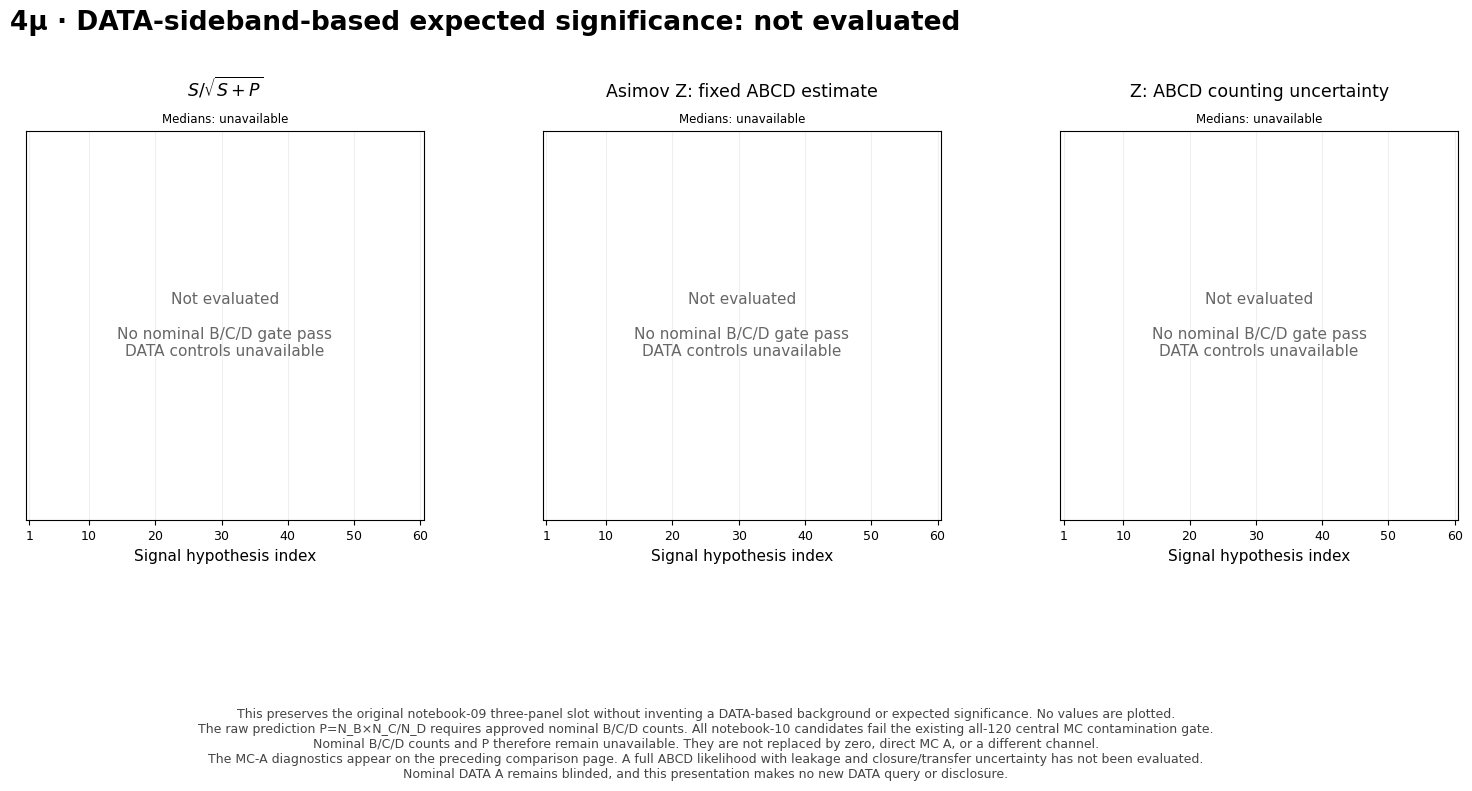

In [56]:
display(figure_lookup['final_data_expected_significance'])

## Shareable outputs

The full PNG sequence follows the 45 figures above. The short sequence retains the same 18 roles as 09, with status and reasons for Data results unsupported in 4μ. Existing WP1 results remain in auxiliary tables.

The original 02/04/06/08/09 outputs and shared helpers are read-only inputs to this report; source SHA256 hashes and validation results are retained in the manifest. The report builder above saves the outputs. The cell below checks only order and links, without querying Data or recalculating plots.


In [57]:
OUTPUT_DIR = NOTEBOOK_DIR/'10_4mu_final_check_outputs'
presentation_order=['if_nominal_plane','if_approaches','if_tradeoff','if_selection','if_nominal_closure']
for mass in ['low','intermediate','all']:
    presentation_order += ['if_vr_mc_'+mass,'if_vr_data_'+mass]
for mass in ['low','intermediate','all']:
    presentation_order += ['loose_final_1d_'+mass,'loose2d_mc_'+mass,'loose2d_data_'+mass]
presentation_order += ['gap_tradeoff','buffer2d_nominal','gap_nominal_closure','gap_support','gap_selection']
for mass in ['low','intermediate','all']:
    presentation_order += ['gap_vr_mc_'+mass,'gap_vr_data_'+mass]
for mass in ['low','intermediate','all']:
    presentation_order += ['buffer_final_1d_'+mass,'buffer2d_mc_'+mass,'buffer2d_data_'+mass]
presentation_order += ['if_nominal_data_contamination','final_intermediate_overlay','final_significance_comparison','if_meeting_comparison','final_data_expected_significance']
decision_names=['if_nominal_plane','if_approaches','if_tradeoff','if_selection',
    'loose_final_1d_intermediate','loose2d_data_intermediate','loose2d_data_all',
    'gap_tradeoff','buffer2d_nominal','gap_selection','buffer_final_1d_intermediate',
    'buffer2d_data_intermediate','buffer2d_data_all','if_nominal_data_contamination','final_intermediate_overlay','final_significance_comparison','if_meeting_comparison','final_data_expected_significance']
assert len(presentation_order) == len(set(presentation_order)) == len(figure_lookup) == 45
assert list(REPORT['catalog'].name) == presentation_order
assert set(presentation_order) == set(figure_lookup)
manifest = json.loads((OUTPUT_DIR/'manifest.json').read_text())
assert manifest['presentation_sequences']['full'] == presentation_order
assert manifest['presentation_sequences']['decision'] == decision_names
display(Markdown('[Full 45-figure PNG index](10_4mu_final_check_outputs/tables/figure_catalog.csv) · '
    '[Short 18-figure PNG index](10_4mu_final_check_outputs/tables/decision_figure_manifest.csv) · '
    '[Team summary](10_4mu_final_check_outputs/final_team_proposal.txt)'))
print('Verified the 09 ordering for 45 main figures and the short 18-figure sequence')


[Full 45-figure PNG index](10_4mu_final_check_outputs/tables/figure_catalog.csv) · [Short 18-figure PNG index](10_4mu_final_check_outputs/tables/decision_figure_manifest.csv) · [Team summary](10_4mu_final_check_outputs/final_team_proposal.txt)

Verified the 09 ordering for 45 main figures and the short 18-figure sequence
